# Thesis — SOM Analysis of the AML (2011–2021)



**Notebook structure:**



0. [Imports & Configuration](#0)

1. [Data Loading](#1)

2. [Feature Engineering & Spatial Harmonisation](#2)

3. [Pooling & Preprocessing](#3)

4. [Data Exploration](#4)

5. [SOM Training — Grid Search](#5)

6. [Clustering on Neurons](#6)

7. [Trajectory Analysis](#7)

8. [Final Visualisations](#8)

9. [Interactive Dashboard](#9)

---

<a id='0'></a>

## 0. Imports & Configuration




In [1]:
import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap
from matplotlib.lines import Line2D
import matplotlib.colors as mcolors
import seaborn as sns
import pandas as pd
from itertools import product
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import VarianceThreshold
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, adjusted_rand_score
from minisom import MiniSom
import param
import panel as pn
import panel.widgets as pnw
from bokeh.plotting import figure
from bokeh.models import (
    ColumnDataSource, ColorBar, LinearColorMapper,
    CategoricalColorMapper, HoverTool, TapTool,
    CustomJS, Div, CDSView, IndexFilter,
    MultiLine, Patches,)
from bokeh.palettes import Viridis256, YlOrRd9, RdBu11
from bokeh.layouts import gridplot
from bokeh.io import output_notebook
import scipy.stats as stats

In [2]:
DATA_2021_PATH  = "C:\\Users\\Botelho\\Desktop\\Tese\\Dados\\2021\\BGRI21_170.gpkg"
DATA_2011_PATH  = "C:\\Users\\Botelho\\Desktop\\Tese\\Dados\\2011\\BGRI11_170.gpkg"

TARGET_CRS      = 3763
SOM_ITER        = 5000
RANDOM_SEED     = 42
VAR_THRESHOLD   = 0.1
OPTIMAL_K       = 7


---

<a id='1'></a>

## 1. Data Loading



We load two geospatial sources: the 2011 and 2021 statistical subsections (BGRI) 

In [3]:
df_2021 = gpd.read_file(DATA_2021_PATH)
df_2011 = gpd.read_file(DATA_2011_PATH)

---

<a id='2'></a>

## 2. Feature Engineering & Spatial Harmonisation



### 2.1 Feature Engineering (2011)



The 2011 Census uses more granular categories than the 2021 one. To make the two editions comparable, we aggregate the detailed 2011 categories into groups equivalent to those published in 2021.

In [4]:
df_2011['N_EDIFICIOS_3OU_MAIS_PISOS']        = df_2011['F_N_EDIFICIOS_5OU_MAIS_PISOS'] + df_2011['N_EDIFICIOS_3OU4_PISOS']
df_2011['N_EDIFICIOS_CONST_ANTES1945']       = df_2011['N_EDIFICIOS_CONSTR_1919A1945'] + df_2011['N_EDIFICIOS_CONSTR_ANTES_1919']
df_2011['N_EDIFICIOS_CONST_1946A1980']       = df_2011['N_EDIFICIOS_CONSTR_1946A1960'] + df_2011['N_EDIFICIOS_CONSTR_1961A1970'] + df_2011['N_EDIFICIOS_CONSTR_1971A1980']
df_2011['N_EDIFICIOS_CONST_1981A2000']       = df_2011['N_EDIFICIOS_CONSTR_1981A1990'] + df_2011['N_EDIFICIOS_CONSTR_1991A1995'] + df_2011['N_EDIFICIOS_CONSTR_1996A2000']
df_2011['N_EDIFICIOS_CONST_2001A2011']       = df_2011['N_EDIFICIOS_CONSTR_2001A2005'] + df_2011['N_EDIFICIOS_CONSTR_2006A2011']
df_2011['N_EDIFICIOS_CONST_DEPOIS2011']      = 0
df_2011['N_RES_HABITUAL_COM_ESTACIONAMENTO'] = df_2011['N_RES_HABITUAL_ESTAC_1'] + df_2011['N_RES_HABITUAL_ESTAC_2'] + df_2011['N_RES_HABITUAL_ESTAC_3']
df_2011['N_INDIVIDUOS_RESIDENT_15A24']       = df_2011['N_INDIVIDUOS_RESIDENT_15A19'] + df_2011['N_INDIVIDUOS_RESIDENT_20A24']
df_2011['N_INDIVIDUOS_RESIDENT_0A14']        = (df_2011['N_INDIVIDUOS_RESIDENT']
                                                - df_2011['N_INDIVIDUOS_RESIDENT_65']
                                                - df_2011['N_INDIVIDUOS_RESIDENT_15A24']
                                                - df_2011['N_INDIVIDUOS_RESIDENT_25A64'])
df_2011['N_FAMILIAS_CLASSICAS_3OUMAIS']      = df_2011['N_FAMILIAS_CLASSICAS'] - df_2011['N_FAMILIAS_CLASSICAS_1OU2_PESS']

The variable `N_EDIFICIOS_CONST_DEPOIS2011` is set to zero for 2011 by construction - in 2011 no buildings built after that year existed yet. This column will be filled with real values in the 2021 data.

### 2.2 Column Selection and Renaming



We remove the intermediate columns used in the aggregations above and variables without an equivalent in the other year. We then rename the 2011 columns to exactly match the 2021 Census nomenclature, preparing the dataset for the final concatenation

In [5]:
DROP_2011 = [
    'N_EDIFICIOS_CLASSICOS_ISOLADOS','N_EDIFICIOS_CLASSICOS_GEMIN','N_EDIFICIOS_CLASSICOS_EMBANDA',
    'N_EDIFICIOS_CLASSICOS_OUTROS','N_EDIFICIOS_PRINCIPAL_RESID','N_EDIFICIOS_PRINCIP_NAO_RESID',
    'N_EDIFICIOS_3OU4_PISOS','F_N_EDIFICIOS_5OU_MAIS_PISOS',
    'N_EDIFICIOS_CONSTR_ANTES_1919','N_EDIFICIOS_CONSTR_1919A1945','N_EDIFICIOS_CONSTR_1946A1960',
    'N_EDIFICIOS_CONSTR_1961A1970','N_EDIFICIOS_CONSTR_1971A1980','N_EDIFICIOS_CONSTR_1981A1990',
    'N_EDIFICIOS_CONSTR_1991A1995','N_EDIFICIOS_CONSTR_1996A2000','N_EDIFICIOS_CONSTR_2001A2005',
    'N_EDIFICIOS_CONSTR_2006A2011',
    'N_EDIFICIOS_ESTRUT_BETAO','N_EDIFICIOS_ESTRUT_COM_PLACA','N_EDIFICIOS_ESTRUT_SEM_PLACA',
    'N_EDIFICIOS_ESTRUT_ADOBE_PEDRA','N_EDIFICIOS_ESTRUT_OUTRA',
    'N_ALOJAMENTOS_FAM_CLASSICOS','N_ALOJAMENTOS_FAM_N_CLASSICOS','N_ALOJAMENTOS_COLECTIVOS',
    'N_CLASSICOS_RES_HABITUAL','N_ALOJAMENTOS_RES_HABITUAL','N_ALOJAMENTOS_VAGOS',
    'N_RES_HABITUAL_COM_AGUA','N_RES_HABITUAL_COM_RETRETE','N_RES_HABITUAL_COM_ESGOTOS',
    'N_RES_HABITUAL_COM_BANHO','N_RES_HABITUAL_AREA_50','N_RES_HABITUAL_AREA_50_100',
    'N_RES_HABITUAL_AREA_100_200','N_RES_HABITUAL_AREA_200',
    'N_RES_HABITUAL_1_2_DIV','N_RES_HABITUAL_3_4_DIV',
    'N_RES_HABITUAL_ESTAC_1','N_RES_HABITUAL_ESTAC_2','N_RES_HABITUAL_ESTAC_3',
    'N_FAMILIAS_INSTITUCIONAIS','N_FAMILIAS_CLASSICAS_3OU4_PESS','N_FAMILIAS_CLASSICAS_NPES65',
    'N_FAMILIAS_CLASSICAS_NPES14','N_FAMILIAS_CLASSIC_SEM_DESEMP','N_FAMILIAS_CLASSIC_1DESEMPREG',
    'N_FAMILIAS_CLASS_2MAIS_DESEMP','N_NUCLEOS_1FILH_NAO_CASADO','N_NUCLEOS_2FILH_NAO_CASADO',
    'N_NUCLEOS_FILH_INF_6ANOS','N_NUCLEOS_FILH_INF_15ANOS','N_NUCLEOS_FILH_MAIS_15ANOS',
    'N_INDIVIDUOS_PRESENT','N_INDIVIDUOS_PRESENT_H','N_INDIVIDUOS_PRESENT_M',
    'N_INDIVIDUOS_RESIDENT_0A4','N_INDIVIDUOS_RESIDENT_5A9','N_INDIVIDUOS_RESIDENT_10A13',
    'N_INDIVIDUOS_RESIDENT_14A19','N_INDIVIDUOS_RESIDENT_15A19','N_INDIVIDUOS_RESIDENT_20A24',
    'N_INDIVIDUOS_RESIDENT_20A64',
    'N_INDIVIDUOS_RESIDENT_H_0A4','N_INDIVIDUOS_RESIDENT_H_5A9','N_INDIVIDUOS_RESIDENT_H_10A13',
    'N_INDIVIDUOS_RESIDENT_H_14A19','N_INDIVIDUOS_RESIDENT_H_15A19','N_INDIVIDUOS_RESIDENT_H_20A24',
    'N_INDIVIDUOS_RESIDENT_H_20A64','N_INDIVIDUOS_RESIDENT_H_25A64','N_INDIVIDUOS_RESIDENT_H_65',
    'N_INDIVIDUOS_RESIDENT_M_0A4','N_INDIVIDUOS_RESIDENT_M_5A9','N_INDIVIDUOS_RESIDENT_M_10A13',
    'N_INDIVIDUOS_RESIDENT_M_14A19','N_INDIVIDUOS_RESIDENT_M_15A19','N_INDIVIDUOS_RESIDENT_M_20A24',
    'N_INDIVIDUOS_RESIDENT_M_20A64','N_INDIVIDUOS_RESIDENT_M_25A64','N_INDIVIDUOS_RESIDENT_M_65',
    'N_INDIV_RESIDENT_N_LER_ESCRV',
    'N_IND_RESIDENT_FENSINO_1BAS','N_IND_RESIDENT_FENSINO_2BAS','N_IND_RESIDENT_FENSINO_3BAS',
    'N_IND_RESIDENT_FENSINO_SEC','N_IND_RESIDENT_FENSINO_POSSEC','N_IND_RESIDENT_FENSINO_SUP',
    'N_IND_RESIDENT_ENSINCOMP_1BAS','N_IND_RESIDENT_ENSINCOMP_2BAS','N_IND_RESIDENT_ENSINCOMP_3BAS',
    'N_IND_RESIDENT_ENSINCOMP_SEC','N_IND_RESIDENT_ENSINCOMP_POSEC','N_IND_RESIDENT_ENSINCOMP_SUP',
    'N_IND_RESID_DESEMP_PROC_1EMPRG','N_IND_RESID_DESEMP_PROC_EMPRG','N_IND_RESID_EMPREGADOS',
    'N_IND_RESID_PENS_REFORM','N_IND_RESID_SEM_ACT_ECON',
    'N_IND_RESID_EMPREG_SECT_PRIM','N_IND_RESID_EMPREG_SECT_SEQ','N_IND_RESID_EMPREG_SECT_TERC',
    'N_IND_RESID_ESTUD_MUN_RESID','N_IND_RESID_TRAB_MUN_RESID'
]

df_2011_data = df_2011.drop(columns=DROP_2011, errors='ignore')

DROP_2021 = [
    'N_EDIFICIOS_COM_NECESSIDADES_REPARACAO',
    'N_RHABITUAL_ACESSIVEL_CADEIRAS_RODAS',
    'N_NUCLEOS_FAMILIARES_COM_FILHOS_TENDO_O_MAIS_NOVO_MENOS_DE_25',
    'N_ALOJAMENTOS_FAM_CLASS_RHABITUAL',
    'N_ALOJAMENTOS_FAM_CLASS_VAGOS_OU_RESID_SECUNDARIA'
]
df_2021_data = df_2021.drop(columns=DROP_2021, errors='ignore')

In [6]:
COLUMN_RENAME_MAP = {
    'N_FAMILIAS_CLASSICAS_1OU2_PESS': 'N_ADP_1_OU_2_PESSOAS',
    'N_FAMILIAS_CLASSICAS_3OUMAIS':   'N_ADP_3_OU_MAIS_PESSOAS',
    'N_FAMILIAS_CLASSICAS':           'N_AGREGADOS_DOMESTICOS_PRIVADOS',
    'N_ALOJAMENTOS':                  'N_ALOJAMENTOS_TOTAL',
    'N_EDIFICIOS_1OU2_PISOS':         'N_EDIFICIOS_1_OU_2_PISOS',
    'N_EDIFICIOS_3OU_MAIS_PISOS':     'N_EDIFICIOS_3_OU_MAIS_PISOS',
    'N_EDIFICIOS_CLASSICOS_1OU2':     'N_EDIFICIOS_CLASS_CONST_1_OU_2_ALOJ',
    'N_EDIFICIOS_CLASSICOS_3OUMAIS':  'N_EDIFICIOS_CLASS_CONST_3_OU_MAIS_ALOJAMENTOS',
    'N_EDIFICIOS_CLASSICOS':          'N_EDIFICIOS_CLASSICOS',
    'N_EDIFICIOS_CONST_1946A1980':    'N_EDIFICIOS_CONSTR_1946_1980',
    'N_EDIFICIOS_CONST_1981A2000':    'N_EDIFICIOS_CONSTR_1981_2000',
    'N_EDIFICIOS_CONST_2001A2011':    'N_EDIFICIOS_CONSTR_2001_2010',
    'N_EDIFICIOS_CONST_DEPOIS2011':   'N_EDIFICIOS_CONSTR_2011_2021',
    'N_EDIFICIOS_CONST_ANTES1945':    'N_EDIFICIOS_CONSTR_ANTES_1945',
    'N_INDIVIDUOS_RESIDENT':          'N_INDIVIDUOS',
    'N_INDIVIDUOS_RESIDENT_0A14':     'N_INDIVIDUOS_0_14',
    'N_INDIVIDUOS_RESIDENT_15A24':    'N_INDIVIDUOS_15_24',
    'N_INDIVIDUOS_RESIDENT_25A64':    'N_INDIVIDUOS_25_64',
    'N_INDIVIDUOS_RESIDENT_65':       'N_INDIVIDUOS_65_OU_MAIS',
    'N_INDIVIDUOS_RESIDENT_H':        'N_INDIVIDUOS_H',
    'N_INDIVIDUOS_RESIDENT_M':        'N_INDIVIDUOS_M',
    'N_RES_HABITUAL_ARREND':          'N_RHABITUAL_ARRENDADOS',
    'N_RES_HABITUAL_COM_ESTACIONAMENTO': 'N_RHABITUAL_COM_ESTACIONAMENTO',
    'N_RES_HABITUAL_PROP_OCUP':       'N_RHABITUAL_PROP_OCUP'
}

df_2011_data = df_2011_data.rename(columns=COLUMN_RENAME_MAP)
print(f"2011 — {df_2011_data.shape[1]} colunas após renomeação")
print(f"2021 — {df_2021_data.shape[1]} colunas")

2011 — 42 colunas após renomeação
2021 — 43 colunas


### 2.3 Dissolving 2021 Subsections into Sections



The 2021 data are published at the **statistical subsection** level (BGRI21). To work at a scale comparable with 2011 and to have stable geometries over time, we dissolve the subsections by the `DTMNFRSEC21` column, which identifies the **statistical section**.

In [7]:
df_2021_seccoes = (
    df_2021_data
    .dissolve(by='DTMNFRSEC21', aggfunc='sum')
    .reset_index()
    .copy()
)

print(f"Secções 2021 após dissolução: {len(df_2021_seccoes)}")

Secções 2021 após dissolução: 2399


### 2.4 Reprojection to the National Coordinate System



We convert all GeoDataFrames to EPSG:3763 (PT-TM06) before any operation involving area or geometric overlay. 

In [8]:
df_2011_data    = df_2011_data.to_crs(epsg=TARGET_CRS)
df_2021_seccoes = df_2021_seccoes.to_crs(epsg=TARGET_CRS)

print("CRS após reprojeção:")
print(f"  df_2011_data    → {df_2011_data.crs}")
print(f"  df_2021_seccoes → {df_2021_seccoes.crs}")

CRS após reprojeção:
  df_2011_data    → EPSG:3763
  df_2021_seccoes → EPSG:3763


### 2.5 Areal Interpolation (Overlay 2011 → 2021)



The boundaries of statistical sections changed between 2011 and 2021. To compare both censuses at the level of **2021 sections**, we use areal interpolation by proportional weight:



1. We perform an **intersection overlay** between the 2011 subsections and the 2021 sections — each resulting fragment belongs to one unit from each year.

2. For each fragment we compute the **weight** = fragment area ÷ total area of the originating 2011 subsection. This reflects the proportion of the population/variable that geographically falls within the 2021 section.

3. We multiply each variable by its weight (`variable × weight`) and sum by 2021 section.

In [9]:
df_2021_seccoes["area_seccao_2021"] = df_2021_seccoes.geometry.area

fragment = gpd.overlay(df_2011_data, df_2021_seccoes, how='intersection').reset_index(drop=True)
fragment['fragment_area']        = fragment.geometry.area
fragment['area_subseccao_2011']  = fragment.groupby('BGRI11')['fragment_area'].transform('sum')
fragment['area_weight']          = fragment['fragment_area'] / fragment['area_subseccao_2011']

peso_check = fragment.groupby('BGRI11')['area_weight'].sum()
print("Soma de pesos por subseccao 2011 (deve ser ~1.0 por BGRI11):")
print(peso_check.describe())
low_coverage = peso_check[peso_check < 0.95]
if len(low_coverage):
    print(f"AVISO: {len(low_coverage)} subseccoes 2011 com cobertura < 0.95:")
    print(low_coverage.sort_values().head(10))
else:
    print("OK — todas as subseccoes 2011 tem cobertura >= 0.95")

Soma de pesos por subseccao 2011 (deve ser ~1.0 por BGRI11):
count    3.493700e+04
mean     1.000000e+00
std      1.691547e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: area_weight, dtype: float64
OK — todas as subseccoes 2011 tem cobertura >= 0.95


c:\Users\Botelho\miniconda3\envs\tese\Lib\site-packages\geopandas\tools\overlay.py:358: UserWarning: `keep_geom_type=True` in overlay resulted in 40457 dropped geometries of different geometry types than df1 has. Set `keep_geom_type=False` to retain all geometries
  result = _collection_extract(result, geom_type, keep_geom_type_warning)


In [10]:
colunas_2011_origem = [c for c in fragment.columns if c.endswith('_1')]
fragment_clean = fragment[colunas_2011_origem + ['DTMNFRSEC21', 'area_weight']].copy()
fragment_clean.index = pd.RangeIndex(len(fragment_clean))

for col_origem in colunas_2011_origem:

    var_name = col_origem[:-2] 
    valores  = fragment_clean[col_origem].astype(float).values
    pesos    = fragment_clean['area_weight'].astype(float).values
    fragment_clean[f'{var_name}_frag'] = valores * pesos

colunas_finais       = [c for c in fragment_clean.columns if c.endswith('_frag')]
df_2011_harmonizado  = fragment_clean.groupby('DTMNFRSEC21')[colunas_finais].sum().reset_index()

print(f"Dados de 2011 harmonizados para {len(df_2011_harmonizado)} secções de 2021.")

Dados de 2011 harmonizados para 2399 secções de 2021.


The coverage check below confirms that the overlay captured the vast majority of the 2011 area. Sections with `sum(weight) < 0.95` lost data in the overlay and should be investigated if total coverage is below 98%.

In [11]:
area_original = df_2011_data.geometry.area.sum()
area_overlay  = fragment['fragment_area'].sum()

print(f"Área original 2011 : {area_original:,.0f} m²")
print(f"Área após overlay  : {area_overlay:,.0f} m²")
print(f"Cobertura          : {area_overlay / area_original * 100:.1f}%")

Área original 2011 : 3,001,902,156 m²
Área após overlay  : 3,001,864,079 m²
Cobertura          : 100.0%


---

<a id='3'></a>

## 3. Pooling & Preprocessing



### 3.1 Building the Longitudinal Dataset



We align both years into a single stacked dataframe (`pooled_data`). Only columns present in both years are retained, ensuring perfect comparability.

In [12]:
df_2011_ready = df_2011_harmonizado.copy()
df_2011_ready.columns = [c.replace('_frag', '') for c in df_2011_ready.columns]
df_2011_ready['ANO'] = 2011

df_2021_ready = df_2021_seccoes.copy()
df_2021_ready['ANO'] = 2021

print('\n=== 2011 harmonised columns ===')
print(sorted(df_2011_ready.columns.tolist()))
print('\n=== 2021 section columns ===')
print(sorted(df_2021_ready.columns.tolist()))
_sym_diff = set(df_2011_ready.columns).symmetric_difference(set(df_2021_ready.columns))
print('\nSymmetric difference (expected: only id/geometry columns):')
print(sorted(_sym_diff))


colunas_comuns = [c for c in df_2011_ready.columns if c in df_2021_ready.columns]
df_11_stack    = df_2011_ready[colunas_comuns]
df_21_stack    = df_2021_ready[colunas_comuns]

pooled_data = pd.concat([df_11_stack, df_21_stack], axis=0).reset_index(drop=True)
pooled_data.drop('OBJECTID', axis=1, errors='ignore', inplace=True)


EXPECTED_VARS = [
    # 5 construction-era brackets
    'N_EDIFICIOS_CONSTR_ANTES_1945', 'N_EDIFICIOS_CONSTR_1946_1980',
    'N_EDIFICIOS_CONSTR_1981_2000',  'N_EDIFICIOS_CONSTR_2001_2010',
    'N_EDIFICIOS_CONSTR_2011_2021',
    # 4 age cohorts
    'N_INDIVIDUOS_0_14', 'N_INDIVIDUOS_15_24',
    'N_INDIVIDUOS_25_64', 'N_INDIVIDUOS_65_OU_MAIS',
    # 2 tenure classes
    'N_RHABITUAL_PROP_OCUP', 'N_RHABITUAL_ARRENDADOS',
    # 2 household-size classes
    'N_ADP_1_OU_2_PESSOAS', 'N_ADP_3_OU_MAIS_PESSOAS',
    # 2 building-floor classes
    'N_EDIFICIOS_1_OU_2_PISOS', 'N_EDIFICIOS_3_OU_MAIS_PISOS',
]
_missing = [v for v in EXPECTED_VARS if v not in pooled_data.columns]
assert not _missing, f'Expected harmonised variables missing from pooled_data: {_missing}'
print('\nASSERT OK — all 16 expected harmonised variables present in pooled_data.')


print(f"Colunas comuns: {len(colunas_comuns)}")
print(f"Total de observações no pooled_data: {len(pooled_data)}")
print(f"  → 2011: {(pooled_data['ANO']==2011).sum()} | 2021: {(pooled_data['ANO']==2021).sum()}")


=== 2011 harmonised columns ===
['ANO', 'DTMNFRSEC21', 'N_ADP_1_OU_2_PESSOAS', 'N_ADP_3_OU_MAIS_PESSOAS', 'N_AGREGADOS_DOMESTICOS_PRIVADOS', 'N_ALOJAMENTOS_FAMILIARES', 'N_ALOJAMENTOS_TOTAL', 'N_EDIFICIOS_1_OU_2_PISOS', 'N_EDIFICIOS_3_OU_MAIS_PISOS', 'N_EDIFICIOS_CLASSICOS', 'N_EDIFICIOS_CLASS_CONST_1_OU_2_ALOJ', 'N_EDIFICIOS_CLASS_CONST_3_OU_MAIS_ALOJAMENTOS', 'N_EDIFICIOS_CONSTR_1946_1980', 'N_EDIFICIOS_CONSTR_1981_2000', 'N_EDIFICIOS_CONSTR_2001_2010', 'N_EDIFICIOS_CONSTR_2011_2021', 'N_EDIFICIOS_CONSTR_ANTES_1945', 'N_EDIFICIOS_EXCLUSIV_RESID', 'N_INDIVIDUOS', 'N_INDIVIDUOS_0_14', 'N_INDIVIDUOS_15_24', 'N_INDIVIDUOS_25_64', 'N_INDIVIDUOS_65_OU_MAIS', 'N_INDIVIDUOS_H', 'N_INDIVIDUOS_M', 'N_NUCLEOS_FAMILIARES', 'N_RHABITUAL_ARRENDADOS', 'N_RHABITUAL_COM_ESTACIONAMENTO', 'N_RHABITUAL_PROP_OCUP', 'OBJECTID']

=== 2021 section columns ===
['ANO', 'BGRI2021', 'DT21', 'DTMN21', 'DTMNFR21', 'DTMNFRSEC21', 'NUTS1', 'NUTS2', 'NUTS3', 'N_ADP_1_OU_2_PESSOAS', 'N_ADP_3_OU_MAIS_PESSOAS', 'N_AGR

---
<a id='3b'></a>
### 3.2 Preprocessing Comparison Pipeline

Five preprocessing dimensions are tested systematically before the main SOM grid search (Section 5). Each combination trains a lightweight 20×20 SOM and is evaluated on four complementary metrics. The winner's preprocessed data is forwarded to Section 5.

| Dimension | Options | Rationale |
|---|---|---|
| **Scaler** | Z-Score vs Min-Max | Z-Score handles outliers better; Min-Max preserves zero-bounded semantics of counts |
| **Variable set** | Full (19) vs Reduced (Spearman ρ > 0.85 pairs removed) | Highly correlated variables double-weight a dimension in SOM distance |
| **Compositional transform** | Raw counts vs **ILR** per group | Census age/tenure/era parts live on a simplex; ILR makes Euclidean distance geometrically valid |
| **Scaling scope** | Joint (2011+2021) vs 2011-anchored | Joint preserves cross-year comparability; anchored avoids 2021 inflating the 2011 scale |
| **PCA** | With PCA reducion vs no PCA reduction | PCA reduces input space without topology loss ; No PCA keeps variable interpretability|

**Composite score** = 0.35 · QE_norm + 0.35 · TE_norm + 0.20 · (1 − Sil)_norm + 0.10 · DB_norm  
Lower = better on all normalised terms.

In [13]:
numeric_cols = pooled_data.select_dtypes(include=np.float64)
COMPOSITIONAL_GROUPS = {
    # parts that sum to total population
    'age':        ['N_INDIVIDUOS_0_14', 'N_INDIVIDUOS_15_24',
                   'N_INDIVIDUOS_25_64', 'N_INDIVIDUOS_65_OU_MAIS'],
    # parts that sum to total classifiable buildings by construction era
    'constr_era': ['N_EDIFICIOS_CONSTR_ANTES_1945', 'N_EDIFICIOS_CONSTR_1946_1980',
                   'N_EDIFICIOS_CONSTR_1981_2000', 'N_EDIFICIOS_CONSTR_2001_2010',
                   'N_EDIFICIOS_CONSTR_2011_2021'],
    # housing tenure (owner-occupied vs rented)
    'tenure':     ['N_RHABITUAL_PROP_OCUP', 'N_RHABITUAL_ARRENDADOS'],
    # household size classes
    'hh_size':    ['N_ADP_1_OU_2_PESSOAS', 'N_ADP_3_OU_MAIS_PESSOAS'],
    # building floor classes
    'bld_floors': ['N_EDIFICIOS_1_OU_2_PISOS', 'N_EDIFICIOS_3_OU_MAIS_PISOS'],
}


def _ilr_coords(X: np.ndarray, zero_fill: float = 0.5) -> np.ndarray:
    """
    ILR via Helmert sequential binary partition.
    Input : (n, D) raw counts or proportions (D ≥ 2).
    Output: (n, D-1) orthonormal ILR coordinates.
    """
    X = np.where(X <= 0, zero_fill, X.astype(float))
    X = X / X.sum(axis=1, keepdims=True)   # normalise to simplex
    D   = X.shape[1]
    out = np.zeros((X.shape[0], D - 1))
    for k in range(1, D):
        # log-geometric mean of the first k parts vs the (k+1)-th part
        log_gm      = np.log(X[:, :k]).mean(axis=1)
        out[:, k-1] = np.sqrt(k / (k + 1)) * (log_gm - np.log(X[:, k]))
    return out


def _apply_ilr(df: pd.DataFrame) -> pd.DataFrame:
    """Replace each compositional group in *df* with its ILR coordinates."""

    transformed_members = set()
    for name, cols in COMPOSITIONAL_GROUPS.items():
        present = [c for c in cols if c in df.columns]
        if len(present) >= 2:
            transformed_members.update(present)

    non_comp = [c for c in df.columns if c not in transformed_members]
    frames   = [df[non_comp].reset_index(drop=True)]

    for name, cols in COMPOSITIONAL_GROUPS.items():
        present = [c for c in cols if c in df.columns]
        if len(present) < 2:
            continue
        ilr_arr = _ilr_coords(df[present].values)
        frames.append(pd.DataFrame(
            ilr_arr,
            columns=[f'ILR_{name}_{i}' for i in range(ilr_arr.shape[1])]
        ))

    return pd.concat(frames, axis=1)


# Quick sanity-check: apply ILR to the 2021 portion and show shape
_demo = pooled_data.loc[pooled_data['ANO'] == 2021, numeric_cols.columns].reset_index(drop=True)
_demo_ilr = _apply_ilr(_demo)
print(f"Original features : {_demo.shape[1]}")
print(f"After ILR         : {_demo_ilr.shape[1]}")
print(f"ILR columns added : {[c for c in _demo_ilr.columns if c.startswith('ILR_')]}")

Original features : 27
After ILR         : 22
ILR columns added : ['ILR_age_0', 'ILR_age_1', 'ILR_age_2', 'ILR_constr_era_0', 'ILR_constr_era_1', 'ILR_constr_era_2', 'ILR_constr_era_3', 'ILR_tenure_0', 'ILR_hh_size_0', 'ILR_bld_floors_0']


Full feature set     : 27 variables
Reduced feature set  : 18 variables
Dropped (|ρ|>0.85): ['N_ADP_3_OU_MAIS_PESSOAS', 'N_ALOJAMENTOS_FAMILIARES', 'N_EDIFICIOS_1_OU_2_PISOS', 'N_EDIFICIOS_CLASS_CONST_1_OU_2_ALOJ', 'N_EDIFICIOS_EXCLUSIV_RESID', 'N_INDIVIDUOS', 'N_INDIVIDUOS_25_64', 'N_INDIVIDUOS_H', 'N_INDIVIDUOS_M']


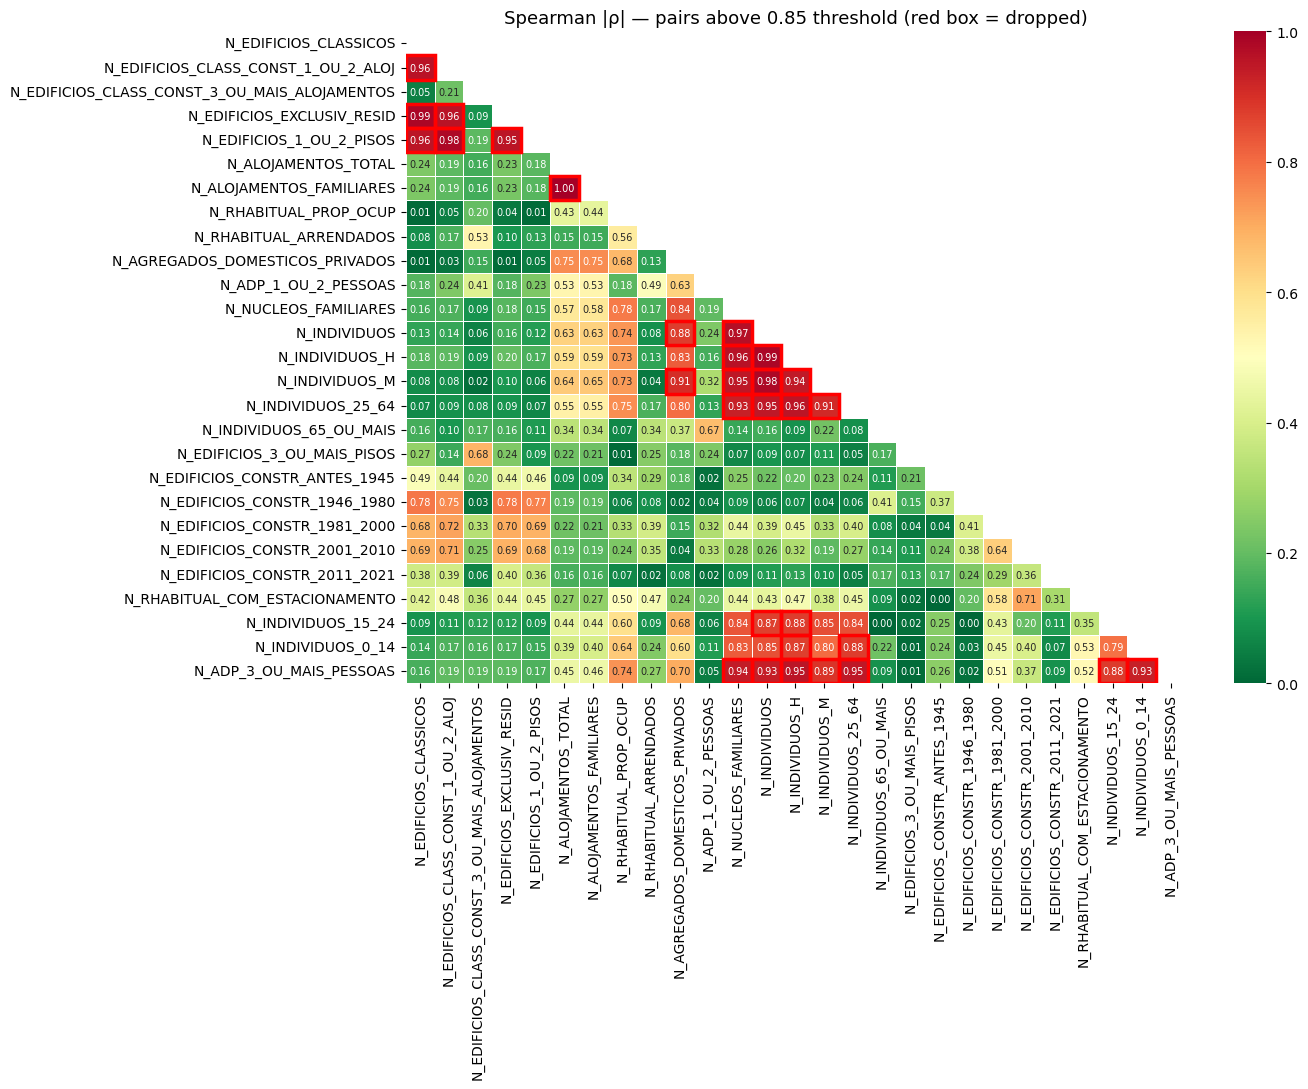

In [14]:
SPEARMAN_THRESHOLD = 0.85

_corr_mat, _ = stats.spearmanr(numeric_cols.values)
corr_abs      = pd.DataFrame(
    np.abs(_corr_mat),
    index=numeric_cols.columns,
    columns=numeric_cols.columns,
)

# Greedy removal: for each pair (i<j) with |ρ| > threshold, keep col i, drop col j
_to_drop = set()
_cols    = numeric_cols.columns.tolist()
for _i in range(len(_cols)):
    for _j in range(_i + 1, len(_cols)):
        if _cols[_i] not in _to_drop and corr_abs.iloc[_i, _j] > SPEARMAN_THRESHOLD:
            _to_drop.add(_cols[_j])

reduced_feature_set  = [c for c in _cols if c not in _to_drop]
dropped_from_reduced = sorted(_to_drop)

print(f"Full feature set     : {len(_cols)} variables")
print(f"Reduced feature set  : {len(reduced_feature_set)} variables")
print(f"Dropped (|ρ|>{SPEARMAN_THRESHOLD}): {dropped_from_reduced}")

# ── Correlation heatmap with threshold highlights ─────────────────────────────
fig, ax = plt.subplots(figsize=(14, 11))
mask    = np.triu(np.ones_like(corr_abs, dtype=bool))
sns.heatmap(corr_abs, mask=mask, cmap='RdYlGn_r', vmin=0, vmax=1,
            annot=True, fmt='.2f', linewidths=0.5, annot_kws={'size': 7}, ax=ax)

for _i in range(len(corr_abs)):
    for _j in range(_i):
        if corr_abs.iloc[_i, _j] > SPEARMAN_THRESHOLD:
            ax.add_patch(
                plt.Rectangle((_j, _i), 1, 1, fill=False, edgecolor='red', lw=2.5)
            )

ax.set_title(
    f'Spearman |ρ| — pairs above {SPEARMAN_THRESHOLD} threshold (red box = dropped)',
    fontsize=13
)
plt.tight_layout()
plt.show()

In [15]:
def _build_preprocessed(df11_raw: pd.DataFrame,
                         df21_raw: pd.DataFrame,
                         scaler_name: str,
                         var_set: str,
                         use_ilr: bool,
                         joint_scaling: bool,
                         use_pca: bool,
                         pca_variance: float = 0.90) -> np.ndarray:
    """
    Return a (n_obs, n_features) float64 array for SOM training.

    joint_scaling=True  → fit scaler on 2011+2021 jointly (preserves cross-year
                          comparability; recommended for longitudinal pooling).
    joint_scaling=False → fit on 2011, transform 2021 with the same fitted scaler
                          (avoids 2021 leaking into 2011's scale reference).
    """
    avail = df11_raw.columns.tolist()
    sel   = [c for c in reduced_feature_set if c in avail] \
            if var_set == 'reduced' else avail

    d11 = df11_raw[sel].copy().reset_index(drop=True)
    d21 = df21_raw[sel].copy().reset_index(drop=True)

    # ILR operates on raw counts — must come before scaling
    if use_ilr:
        d11 = _apply_ilr(d11)
        d21 = _apply_ilr(d21)
        common = [c for c in d11.columns if c in d21.columns]
        d11, d21 = d11[common], d21[common]

    ScalerCls = MinMaxScaler if scaler_name == 'minmax' else StandardScaler

    if joint_scaling:
        full = pd.concat([d11, d21], axis=0).reset_index(drop=True)
        sc   = ScalerCls()
        arr  = sc.fit_transform(full.values.astype(float))
        a11, a21 = arr[:len(d11)], arr[len(d11):]
    else:
        # Fit on 2011, apply to both — preserves a single reference scale
        sc  = ScalerCls().fit(d11.values.astype(float))
        a11 = sc.transform(d11.values.astype(float))
        a21 = sc.transform(d21.values.astype(float))

    X = np.vstack([a11, a21])

    if use_pca:
        pca = PCA(n_components=pca_variance, random_state=RANDOM_SEED)
        X   = pca.fit_transform(X)
        print(f"      PCA: {pca.n_components_} components ({pca_variance:.0%} var)", end=' ')

    return X.astype(np.float64)


def _evaluate_som(X: np.ndarray,
                  som_x: int, som_y: int, n_iter: int,
                  n_clusters: int, seed: int) -> dict:
    """Train a MiniSom and return QE, TE, silhouette, DB on neuron weights."""
    input_len = X.shape[1]
    som = MiniSom(x=som_x, y=som_y, input_len=input_len,
                  sigma=3.0, learning_rate=0.3,
                  topology='rectangular', random_seed=seed)
    som.train_random(X, n_iter)

    w_flat = som.get_weights()

    qe = float(np.mean([
        np.linalg.norm(x - w_flat[som.winner(x)])
        for x in X
    ]))

    te_errors = 0
    for x in X:
        b1 = som.winner(x)
        d  = np.linalg.norm(w_flat - x, axis=2)
        d[b1] = np.inf
        b2 = np.unravel_index(np.argmin(d), d.shape)
        if max(abs(b1[0] - b2[0]), abs(b1[1] - b2[1])) > 1:
            te_errors += 1
    te = te_errors / len(X)

    w   = w_flat.reshape(-1, input_len)
    km  = KMeans(n_clusters=n_clusters, random_state=seed, n_init=10)
    lbl = km.fit_predict(w)
    sil = silhouette_score(w, lbl)     if len(np.unique(lbl)) > 1 else 0.0
    db  = davies_bouldin_score(w, lbl) if len(np.unique(lbl)) > 1 else np.inf

    return dict(qe=qe, te=te, silhouette=sil, davies_bouldin=db,
                n_features=int(X.shape[1]))

In [16]:
PREP_SOM_X    = 20
PREP_SOM_Y    = 20
PREP_SOM_ITER = 1000   # fast; Section 5 uses SOM_ITER=5000 on the winner

# Extract raw (unscaled) per-year numeric DataFrames
df11_raw = (pooled_data
            .loc[pooled_data['ANO'] == 2011, numeric_cols.columns]
            .reset_index(drop=True))
df21_raw = (pooled_data
            .loc[pooled_data['ANO'] == 2021, numeric_cols.columns]
            .reset_index(drop=True))

# Full grid: 2×2×2×2×2 = 32 configurations
# Set PREP_FULL_GRID = False to run only the core 8 (±scaler × ±vars × ±ILR)
PREP_FULL_GRID = True

if PREP_FULL_GRID:
    joint_opts = [True, False]
    pca_opts   = [False, True]
else:
    joint_opts = [True]    # joint only for core comparison
    pca_opts   = [False]   # no PCA for core comparison

from itertools import product as _product

PREP_GRID = list(_product(
    ['zscore', 'minmax'],  # scaler
    ['full', 'reduced'],   # variable set
    [False, True],         # ILR
    joint_opts,            # joint scaling
    pca_opts,              # PCA
))

print(f"Running {len(PREP_GRID)} preprocessing configurations "
      f"(SOM {PREP_SOM_X}×{PREP_SOM_Y}, {PREP_SOM_ITER} iter)…\n")

prep_results = []

for scaler_name, var_set, use_ilr, joint, use_pca in PREP_GRID:
    label = (f"scaler={scaler_name} | vars={var_set} | ilr={use_ilr} | "
             f"joint={joint} | pca={use_pca}")
    print(f"  ▶ {label} … ", end='', flush=True)
    try:
        X  = _build_preprocessed(df11_raw, df21_raw,
                                  scaler_name, var_set,
                                  use_ilr, joint, use_pca)
        m  = _evaluate_som(X, PREP_SOM_X, PREP_SOM_Y,
                           PREP_SOM_ITER, OPTIMAL_K, RANDOM_SEED)
        prep_results.append(dict(
            scaler=scaler_name, var_set=var_set,
            ilr=use_ilr, joint=joint, pca=use_pca,
            label=label, **m
        ))
        print(f"QE={m['qe']:.4f}  TE={m['te']:.4f}  Sil={m['silhouette']:.4f}")
    except Exception as exc:
        print(f"ERROR — {exc}")

prep_comparison_df = pd.DataFrame(prep_results)
print(f"\nDone — {len(prep_comparison_df)} configs evaluated.")

Running 32 preprocessing configurations (SOM 20×20, 1000 iter)…

  ▶ scaler=zscore | vars=full | ilr=False | joint=True | pca=False … QE=2.3066  TE=0.0531  Sil=0.2756
  ▶ scaler=zscore | vars=full | ilr=False | joint=True | pca=True … 

c:\Users\Botelho\miniconda3\envs\tese\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


      PCA: 7 components (90% var) QE=1.8116  TE=0.0669  Sil=0.2814
  ▶ scaler=zscore | vars=full | ilr=False | joint=False | pca=False … 

c:\Users\Botelho\miniconda3\envs\tese\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


QE=4.6339  TE=0.0598  Sil=0.3020
  ▶ scaler=zscore | vars=full | ilr=False | joint=False | pca=True … 

c:\Users\Botelho\miniconda3\envs\tese\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


... (54 outputs left out)

QE=0.2460  TE=0.0650  Sil=0.1971
  ▶ scaler=minmax | vars=reduced | ilr=True | joint=False | pca=True … 

c:\Users\Botelho\miniconda3\envs\tese\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


      PCA: 7 components (90% var) QE=0.1927  TE=0.0796  Sil=0.2668

Done — 32 configs evaluated.


c:\Users\Botelho\miniconda3\envs\tese\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=2.
  warnings.warn(


=== Preprocessing Comparison — Ranked (best → worst) ===
scaler var_set   ilr  joint   pca  n_features       qe       te  silhouette  davies_bouldin  composite_score
minmax reduced False   True  True           7 0.206915 0.072322    0.330706        1.043389         0.214016
minmax    full False   True  True           6 0.219918 0.067737    0.312061        1.026915         0.216865
minmax    full  True  False  True           6 0.207211 0.050855    0.289277        1.123264         0.217031
minmax    full  True   True  True           6 0.186009 0.060025    0.276446        1.112865         0.224314
minmax reduced  True   True  True           7 0.180023 0.074823    0.296417        1.087587         0.225833
minmax reduced  True  False  True           7 0.192659 0.079617    0.266837        1.214667         0.245003
minmax reduced False   True False          18 0.255904 0.063360    0.194285        1.753067         0.288717
minmax reduced  True   True False          15 0.224238 0.056899    0.19

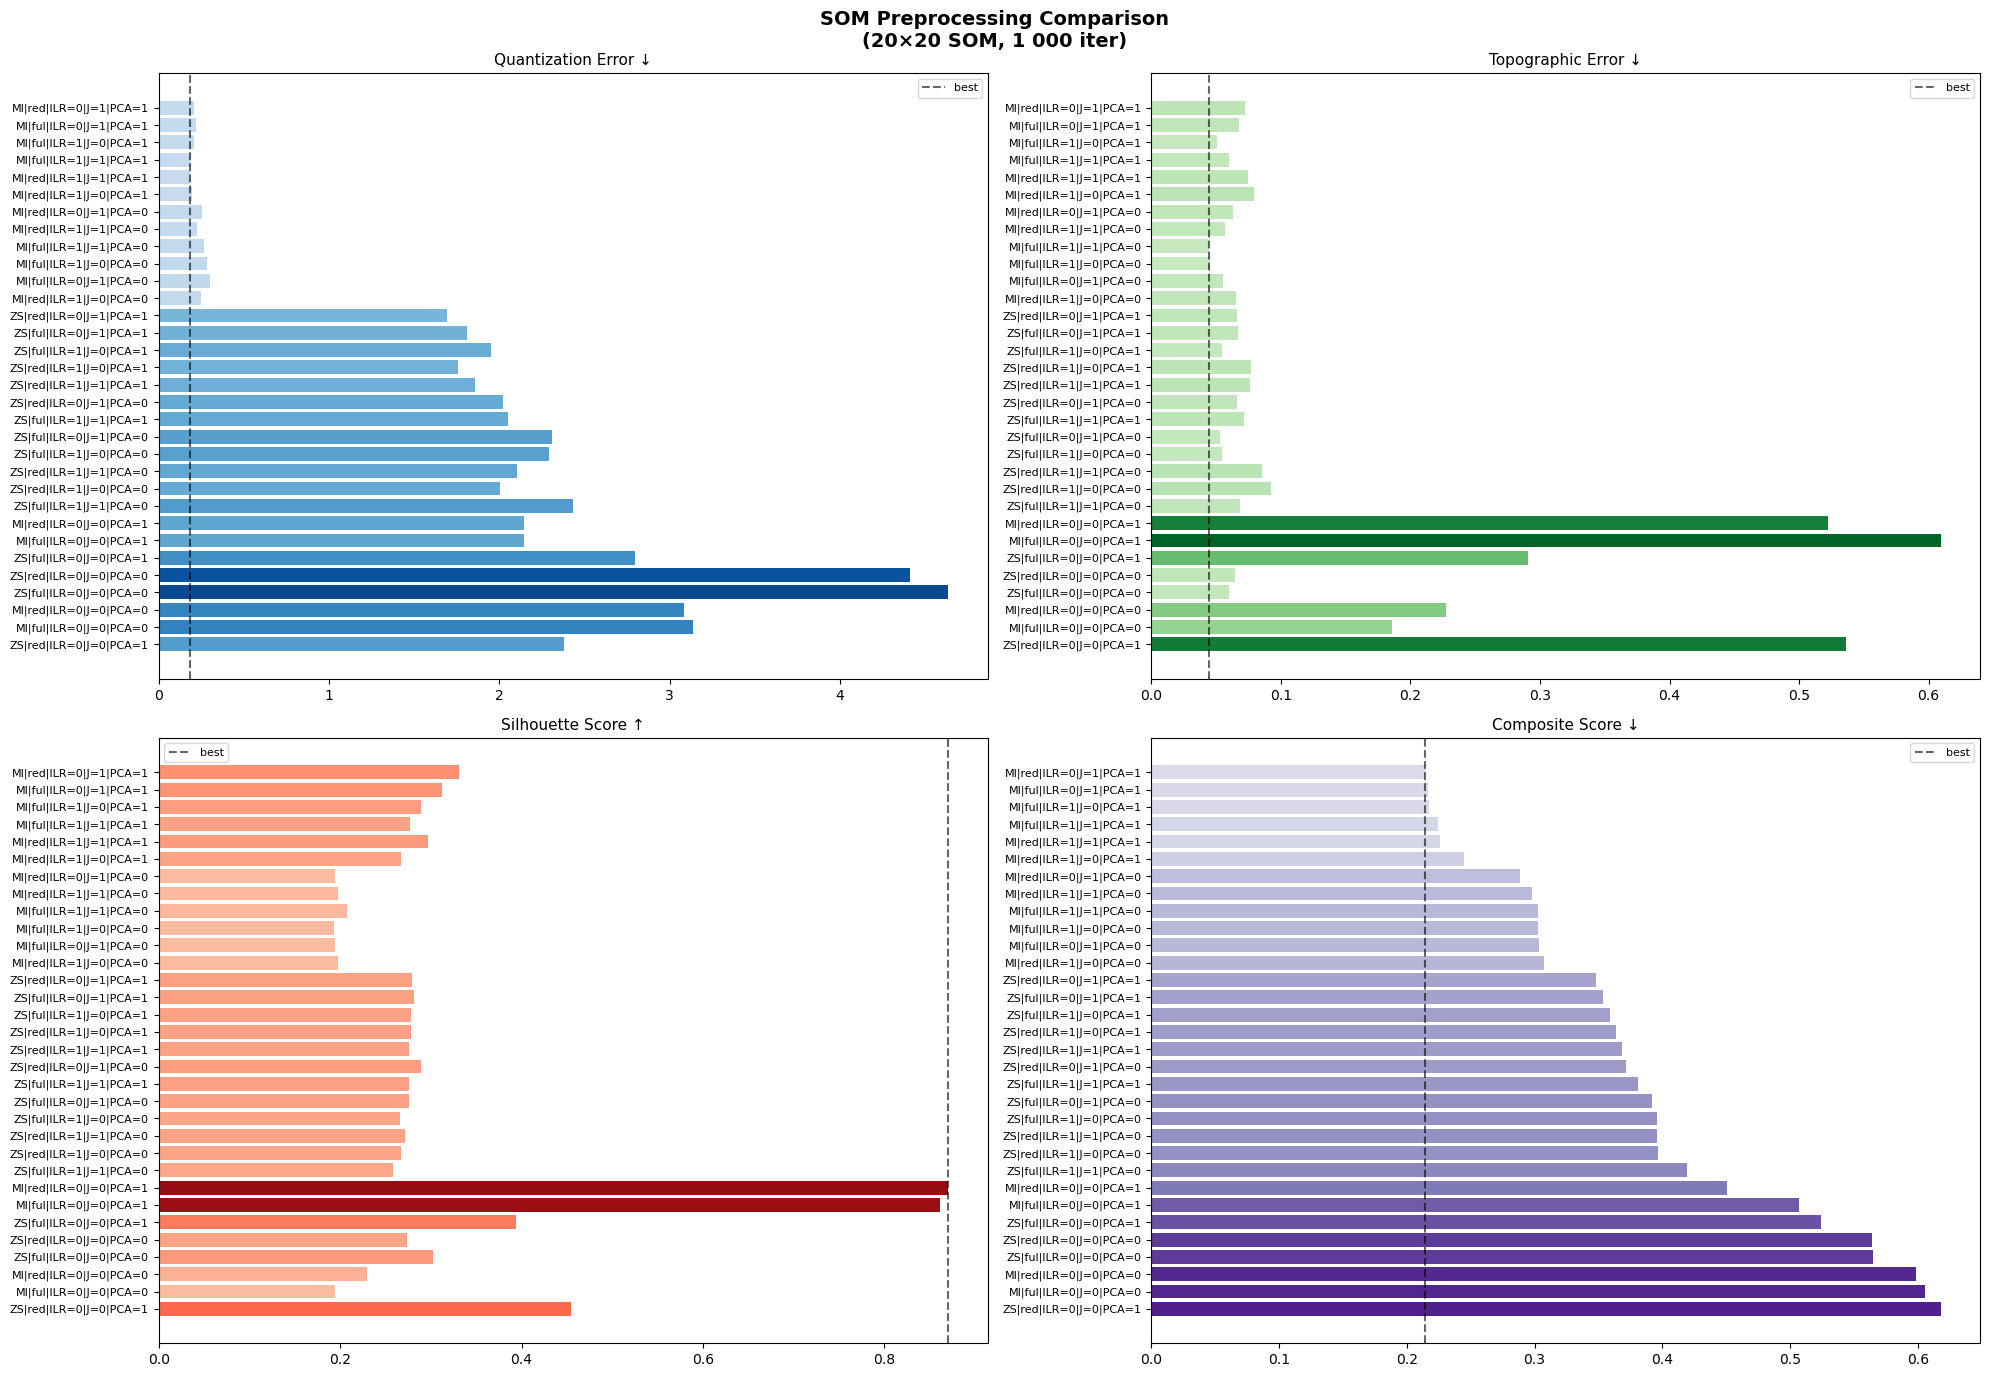

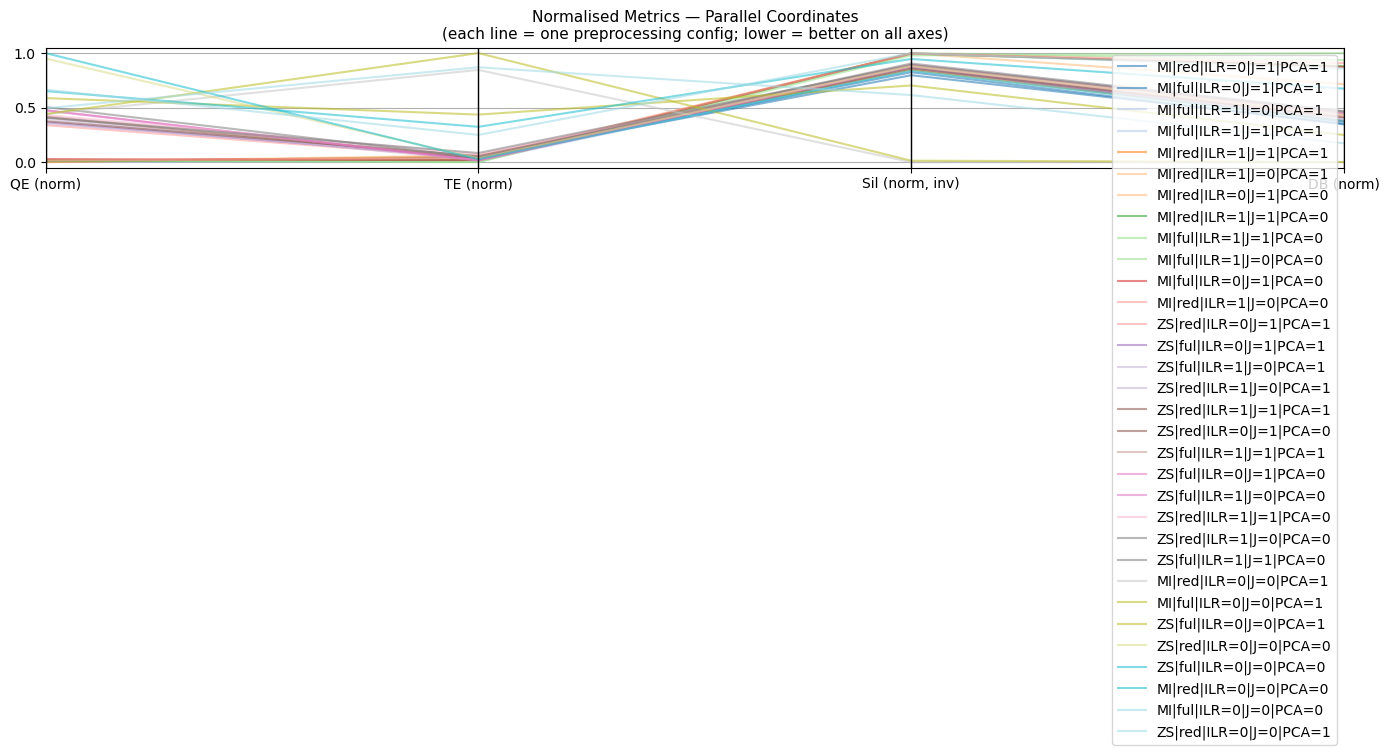

In [17]:
def _norm01(s: pd.Series) -> pd.Series:
    rng = s.max() - s.min()
    return (s - s.min()) / rng if rng > 0 else pd.Series(0.0, index=s.index)

prep_comparison_df['qe_n']  = _norm01(prep_comparison_df['qe'])
prep_comparison_df['te_n']  = _norm01(prep_comparison_df['te'])
# negate silhouette so "higher sil → lower normalised score → better rank"
prep_comparison_df['sil_n'] = _norm01(-prep_comparison_df['silhouette'])
prep_comparison_df['db_n']  = _norm01(prep_comparison_df['davies_bouldin'])

prep_comparison_df['composite_score'] = (
    0.35 * prep_comparison_df['qe_n']  +
    0.35 * prep_comparison_df['te_n']  +
    0.20 * prep_comparison_df['sil_n'] +
    0.10 * prep_comparison_df['db_n']
)
prep_comparison_df = (prep_comparison_df
                      .sort_values('composite_score')
                      .reset_index(drop=True))

disp_cols = ['scaler','var_set','ilr','joint','pca',
             'n_features','qe','te','silhouette','davies_bouldin','composite_score']
print("=== Preprocessing Comparison — Ranked (best → worst) ===")
print(prep_comparison_df[disp_cols].to_string(index=False))

# Short label for each config
short_labels = [
    (f"{r['scaler'][:2].upper()}|"
     f"{'red' if r['var_set']=='reduced' else 'ful'}|"
     f"ILR={int(r['ilr'])}|"
     f"J={int(r['joint'])}|"
     f"PCA={int(r['pca'])}")
    for _, r in prep_comparison_df.iterrows()
]

# ── 4-panel bar chart ─────────────────────────────────────────────────────────
metrics_info = [
    ('qe',             'Quantization Error ↓',    'Blues'),
    ('te',             'Topographic Error ↓',     'Greens'),
    ('silhouette',     'Silhouette Score ↑',       'Reds'),
    ('composite_score','Composite Score ↓',       'Purples'),
]

fig, axes = plt.subplots(2, 2, figsize=(20, 14))
fig.suptitle('SOM Preprocessing Comparison\n(20×20 SOM, 1 000 iter)', fontsize=14, fontweight='bold')

for ax, (metric, title, cmap_name) in zip(axes.flat, metrics_info):
    vals   = prep_comparison_df[metric].values.astype(float)
    normed = (vals - vals.min()) / (vals.max() - vals.min() + 1e-9)
    colors = plt.colormaps[cmap_name](0.25 + 0.65 * normed)
    ax.barh(range(len(prep_comparison_df)), vals, color=colors)
    ax.set_yticks(range(len(prep_comparison_df)))
    ax.set_yticklabels(short_labels, fontsize=8)
    ax.set_title(title, fontsize=11)
    # mark best value
    best_val = vals.min() if '↓' in title else vals.max()
    ax.axvline(best_val, color='black', linestyle='--', lw=1.5, alpha=0.6, label='best')
    ax.legend(fontsize=8)
    ax.invert_yaxis()

plt.tight_layout()
plt.show()

# ── Parallel-coordinates overview ─────────────────────────────────────────────
from pandas.plotting import parallel_coordinates as _pd_parallel

radar_df = prep_comparison_df[['qe_n','te_n','sil_n','db_n']].copy()
radar_df.insert(0, 'config', short_labels)
radar_df['scaler'] = prep_comparison_df['scaler'].values

fig2, ax2 = plt.subplots(figsize=(14, 5))
_pd_parallel(radar_df.drop(columns='scaler'), 'config',
             colormap=plt.cm.tab20, alpha=0.55, linewidth=1.5, ax=ax2)
ax2.set_title('Normalised Metrics — Parallel Coordinates\n'
              '(each line = one preprocessing config; lower = better on all axes)',
              fontsize=11)
ax2.set_xticklabels(['QE (norm)','TE (norm)','Sil (norm, inv)','DB (norm)'])
plt.tight_layout()
plt.show()

In [18]:
# === APPENDIX TABLE: top-10 preprocessing configurations by composite score ===
# Makes visible how narrow the margin is between the best PCA and non-PCA pipelines.
_top10 = prep_comparison_df.head(10).copy()

_top10_disp = _top10[['scaler', 'var_set', 'ilr', 'joint', 'pca',
                      'n_features', 'qe', 'te', 'silhouette',
                      'davies_bouldin', 'composite_score']].copy()

# Tidy formatting
_top10_disp['scaler']  = _top10_disp['scaler'].str.upper()
_top10_disp['var_set'] = _top10_disp['var_set'].map({'reduced': 'Spearman', 'full': 'Full'})
_top10_disp['ilr']     = _top10_disp['ilr'].map({True: 'ILR', False: 'Raw'})
_top10_disp['joint']   = _top10_disp['joint'].map({True: 'Joint', False: '2011-anchor'})
_top10_disp['pca']     = _top10_disp['pca'].map({True: 'PCA', False: 'No PCA'})
for c in ['qe', 'te', 'silhouette', 'davies_bouldin', 'composite_score']:
    _top10_disp[c] = _top10_disp[c].round(4)

_top10_disp.columns = ['Scaler', 'Variables', 'Composition', 'Scaling scope',
                       'PCA', 'Features', 'QE', 'TE', 'Silhouette',
                       'Davies-Bouldin', 'Composite']

print("TOP-10 PREPROCESSING CONFIGURATIONS (ranked by composite score)")
print(_top10_disp.to_string(index=False))

# Margin between best PCA and best non-PCA config
best_pca    = prep_comparison_df[prep_comparison_df['pca'] == True]['composite_score'].min()
best_nopca  = prep_comparison_df[prep_comparison_df['pca'] == False]['composite_score'].min()
print(f"\nBest composite WITH PCA    : {best_pca:.4f}")
print(f"Best composite WITHOUT PCA : {best_nopca:.4f}")
print(f"Absolute margin            : {abs(best_nopca - best_pca):.4f}")

TOP-10 PREPROCESSING CONFIGURATIONS (ranked by composite score)
Scaler Variables Composition Scaling scope    PCA  Features     QE     TE  Silhouette  Davies-Bouldin  Composite
MINMAX  Spearman         Raw         Joint    PCA         7 0.2069 0.0723      0.3307          1.0434     0.2140
MINMAX      Full         Raw         Joint    PCA         6 0.2199 0.0677      0.3121          1.0269     0.2169
MINMAX      Full         ILR   2011-anchor    PCA         6 0.2072 0.0509      0.2893          1.1233     0.2170
MINMAX      Full         ILR         Joint    PCA         6 0.1860 0.0600      0.2764          1.1129     0.2243
MINMAX  Spearman         ILR         Joint    PCA         7 0.1800 0.0748      0.2964          1.0876     0.2258
MINMAX  Spearman         ILR   2011-anchor    PCA         7 0.1927 0.0796      0.2668          1.2147     0.2450
MINMAX  Spearman         Raw         Joint No PCA        18 0.2559 0.0634      0.1943          1.7531     0.2887
MINMAX  Spearman         ILR    

In [19]:
best_cfg = prep_comparison_df.iloc[0]
print("Best preprocessing configuration:")
print(f"  scaler={best_cfg['scaler']}  var_set={best_cfg['var_set']}  "
      f"ilr={best_cfg['ilr']}  joint={best_cfg['joint']}  pca={best_cfg['pca']}")
print(f"  QE={best_cfg['qe']:.4f}  TE={best_cfg['te']:.4f}  "
      f"Sil={best_cfg['silhouette']:.4f}  Score={best_cfg['composite_score']:.4f}")

X_final = _build_preprocessed(
    df11_raw, df21_raw,
    scaler_name   = best_cfg['scaler'],
    var_set       = best_cfg['var_set'],
    use_ilr       = bool(best_cfg['ilr']),
    joint_scaling = bool(best_cfg['joint']),
    use_pca       = bool(best_cfg['pca']),
)

# `data` is consumed by Section 5's SOM grid-search
data = X_final

# `scaled_pooled` is consumed by Sections 6-8 for cluster assignment and
# trajectory/visualisation code — keep it as a DataFrame with the same index
scaled_pooled = pd.DataFrame(
    X_final,
    columns=[f'f{i}' for i in range(X_final.shape[1])]
)

print(f"\n`data` and `scaled_pooled` updated → shape {data.shape}")
print("→ Sections 5-8 will operate on the best-preprocessed feature space.")

Best preprocessing configuration:
  scaler=minmax  var_set=reduced  ilr=False  joint=True  pca=True
  QE=0.2069  TE=0.0723  Sil=0.3307  Score=0.2140
      PCA: 7 components (90% var) 
`data` and `scaled_pooled` updated → shape (4798, 7)
→ Sections 5-8 will operate on the best-preprocessed feature space.


In [20]:
X_final = _build_preprocessed(
    df11_raw, df21_raw,
    scaler_name   = best_cfg['scaler'],
    var_set       = best_cfg['var_set'],
    use_ilr       = bool(best_cfg['ilr']),
    joint_scaling = bool(best_cfg['joint']),
    use_pca       = False,
)

data = X_final

scaled_pooled = pd.DataFrame(
    X_final,
    columns=[f'f{i}' for i in range(X_final.shape[1])]
)

print(f"PCA desactivado — nova shape: {data.shape}")
print("→ Secções 5-8 vão usar este espaço de features.")

PCA desactivado — nova shape: (4798, 18)
→ Secções 5-8 vão usar este espaço de features.


In [21]:
print("=" * 65)
print("VERIFICATION — post-fix feature space summary")
print("=" * 65)

# 1. Harmonised numeric variables in pooled_data
_numeric = pooled_data.select_dtypes(include='number').columns.difference(['ANO', 'cluster'])
print(f"\n1. Harmonised numeric variables in pooled_data : {len(_numeric)}")
for v in sorted(_numeric):
    print(f"   {v}")

# 2. After Spearman reduction
print(f"\n2. After Spearman reduction (|rho|>{SPEARMAN_THRESHOLD}): {len(reduced_feature_set)} variables")
print("   Retained :", sorted(reduced_feature_set))
print("   Dropped  :", sorted(dropped_from_reduced))

# 3. ILR-transformed feature names + dimensionality
_demo_v = pooled_data.loc[pooled_data["ANO"] == 2021,
                           pooled_data.select_dtypes(include="float64").columns].reset_index(drop=True)
_demo_ilr = _apply_ilr(_demo_v)
_ilr_cols = [c for c in _demo_ilr.columns if c.startswith("ILR_")]
print(f"\n3. ILR-transformed features ({len(_ilr_cols)} coords from {len(COMPOSITIONAL_GROUPS)} groups):")
for c in _ilr_cols:
    print(f"   {c}")
print(f"   Final dimensionality after ILR: {_demo_ilr.shape[1]} features")

# 4. Pooled dataset shape and per-year counts
print(f"\n4. Pooled dataset shape : {pooled_data.shape}")
print(f"   2011 sections : {(pooled_data['ANO']==2011).sum()}")
print(f"   2021 sections : {(pooled_data['ANO']==2021).sum()}")

print("\n(SOM QE/TE will be printed after re-running the grid-search in Section 5)")
print("=" * 65)


VERIFICATION — post-fix feature space summary

1. Harmonised numeric variables in pooled_data : 27
   N_ADP_1_OU_2_PESSOAS
   N_ADP_3_OU_MAIS_PESSOAS
   N_AGREGADOS_DOMESTICOS_PRIVADOS
   N_ALOJAMENTOS_FAMILIARES
   N_ALOJAMENTOS_TOTAL
   N_EDIFICIOS_1_OU_2_PISOS
   N_EDIFICIOS_3_OU_MAIS_PISOS
   N_EDIFICIOS_CLASSICOS
   N_EDIFICIOS_CLASS_CONST_1_OU_2_ALOJ
   N_EDIFICIOS_CLASS_CONST_3_OU_MAIS_ALOJAMENTOS
   N_EDIFICIOS_CONSTR_1946_1980
   N_EDIFICIOS_CONSTR_1981_2000
   N_EDIFICIOS_CONSTR_2001_2010
   N_EDIFICIOS_CONSTR_2011_2021
   N_EDIFICIOS_CONSTR_ANTES_1945
   N_EDIFICIOS_EXCLUSIV_RESID
   N_INDIVIDUOS
   N_INDIVIDUOS_0_14
   N_INDIVIDUOS_15_24
   N_INDIVIDUOS_25_64
   N_INDIVIDUOS_65_OU_MAIS
   N_INDIVIDUOS_H
   N_INDIVIDUOS_M
   N_NUCLEOS_FAMILIARES
   N_RHABITUAL_ARRENDADOS
   N_RHABITUAL_COM_ESTACIONAMENTO
   N_RHABITUAL_PROP_OCUP

2. After Spearman reduction (|rho|>0.85): 18 variables
   Retained : ['N_ADP_1_OU_2_PESSOAS', 'N_AGREGADOS_DOMESTICOS_PRIVADOS', 'N_ALOJAMENTOS_TOT

---

<a id='4'></a>

## 4. Data Exploration



We visualise the distribution of each numeric variable through boxplots before feeding them to the SOM. This allows identifying extreme outliers and confirming that the scaling is adequate.

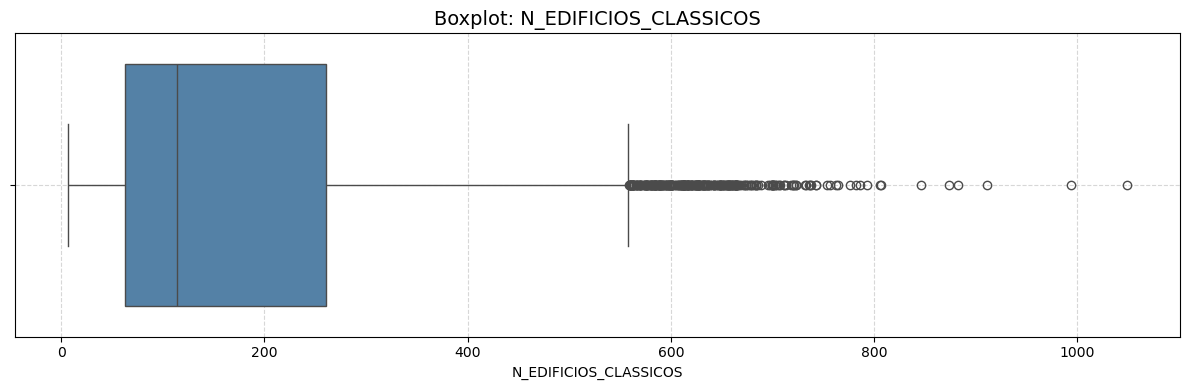

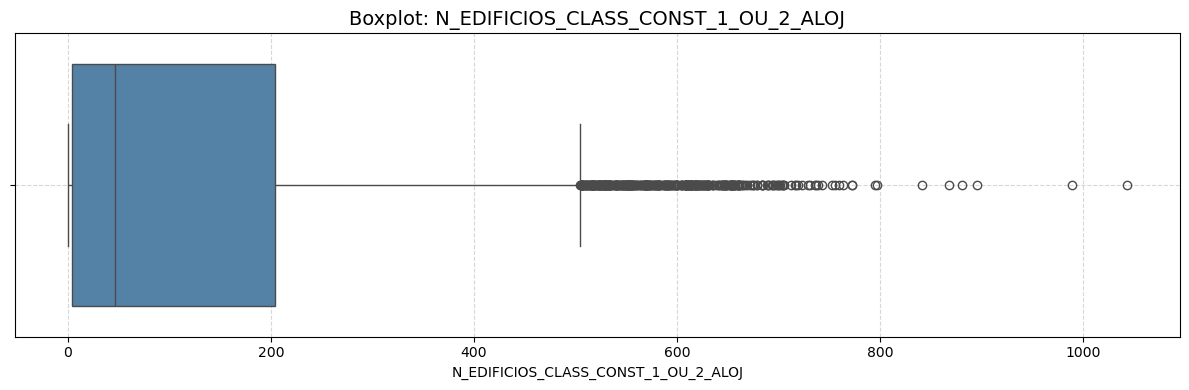

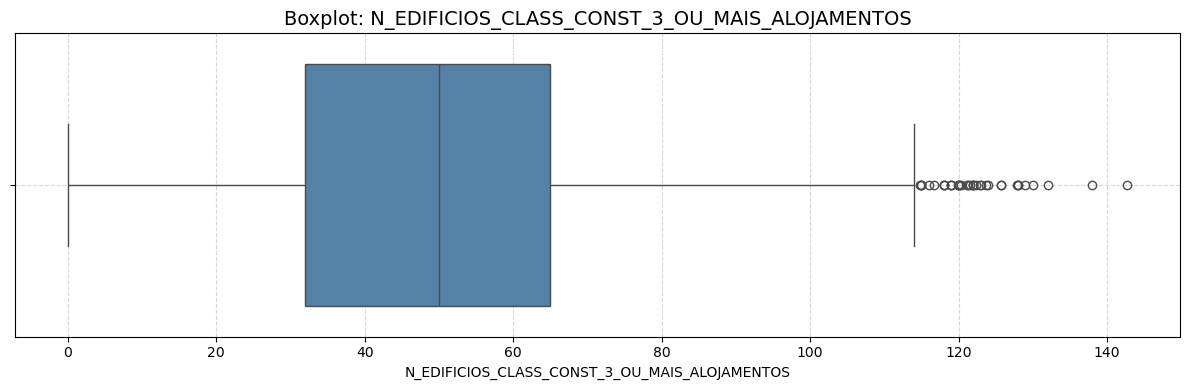

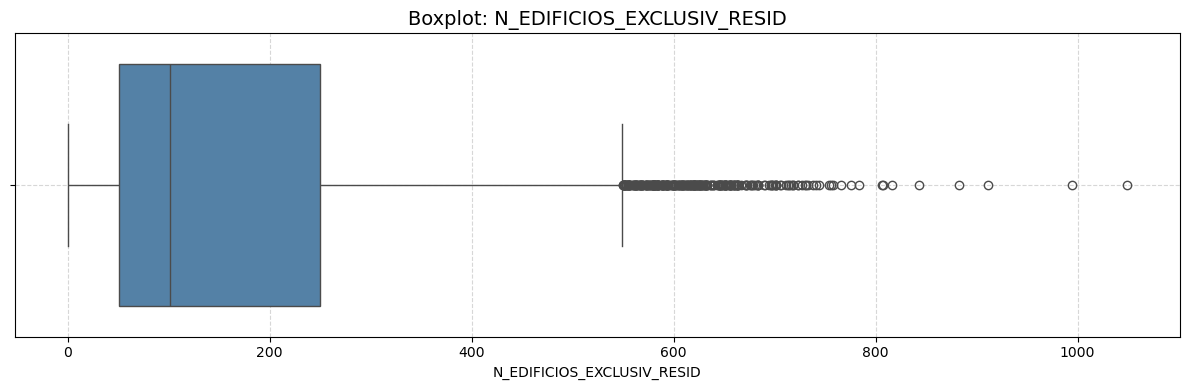

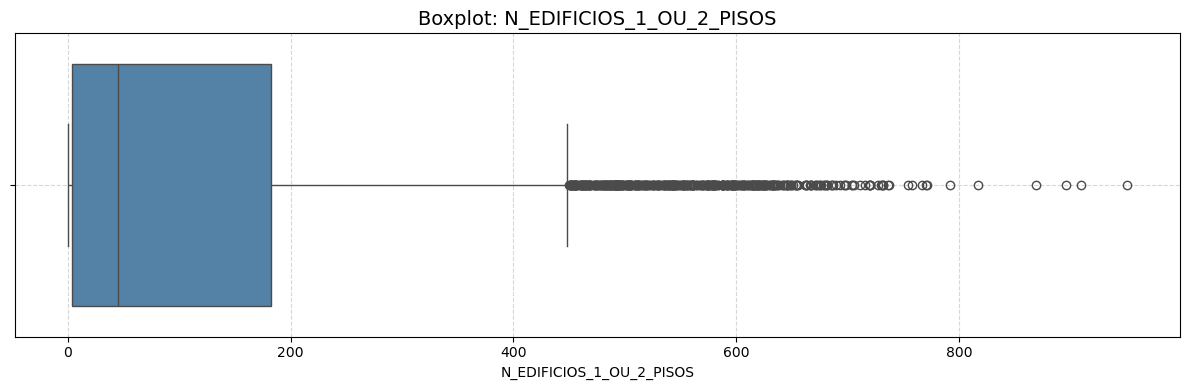

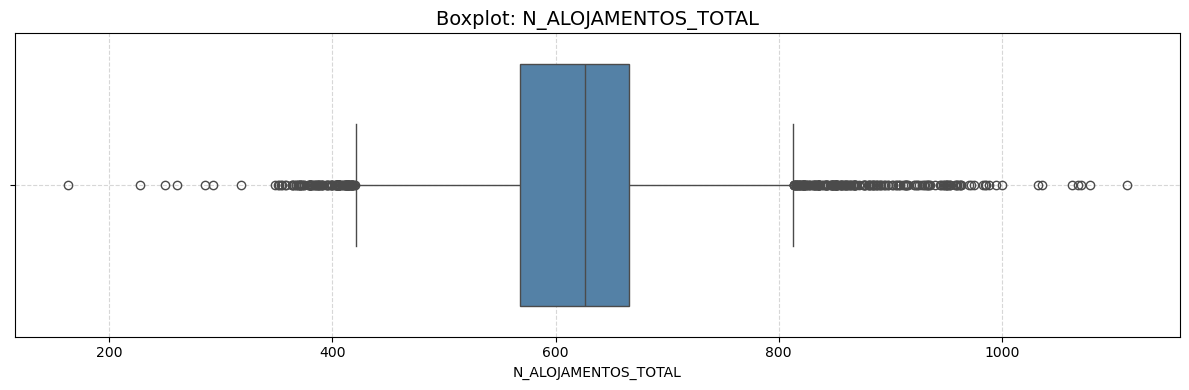

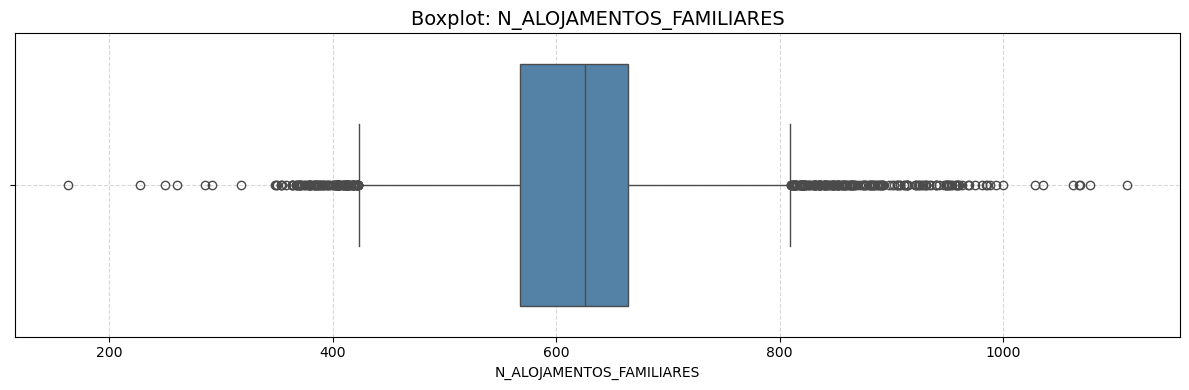

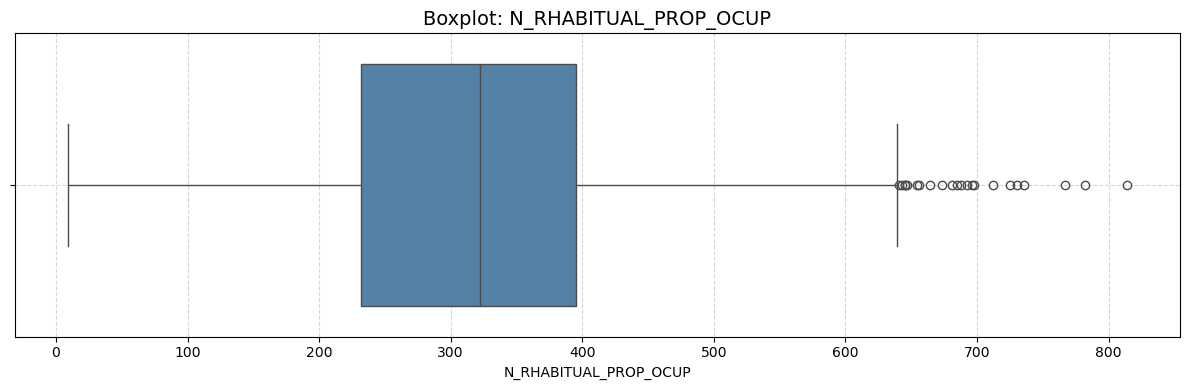

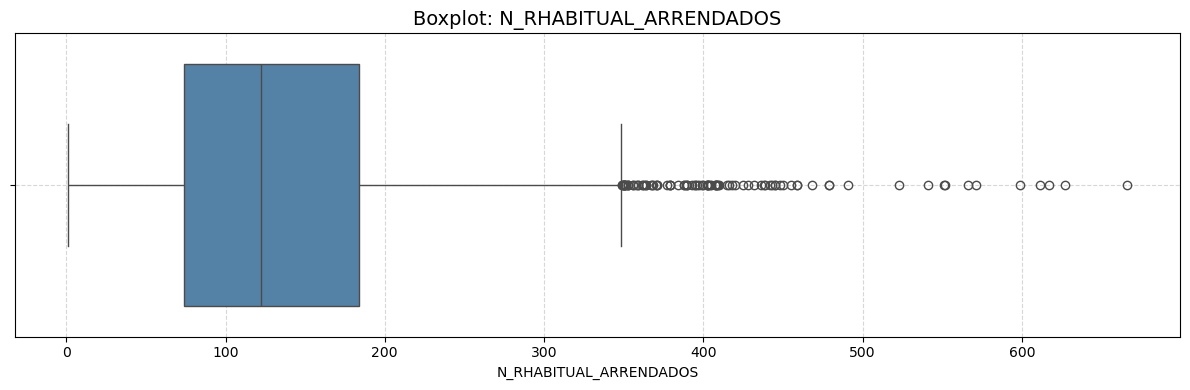

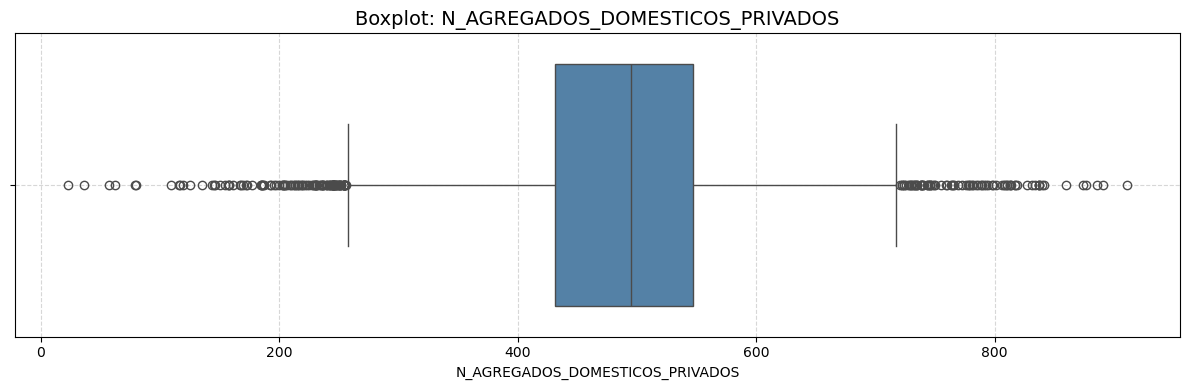

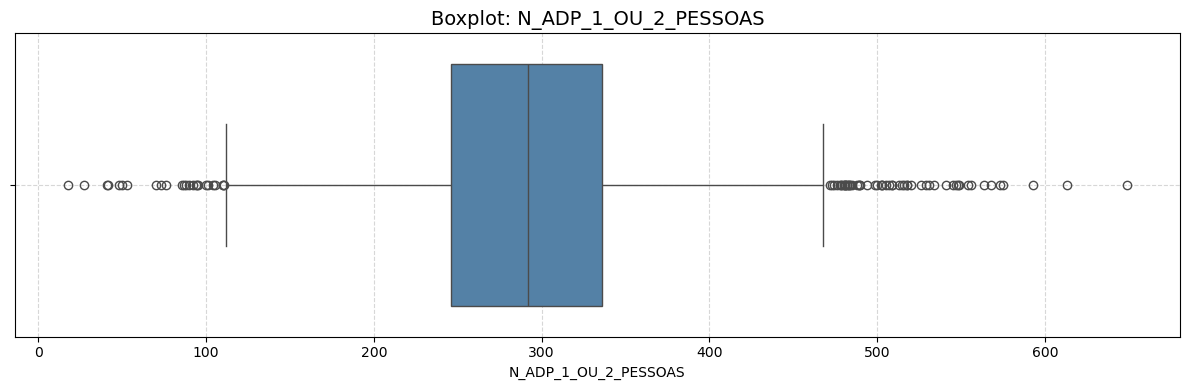

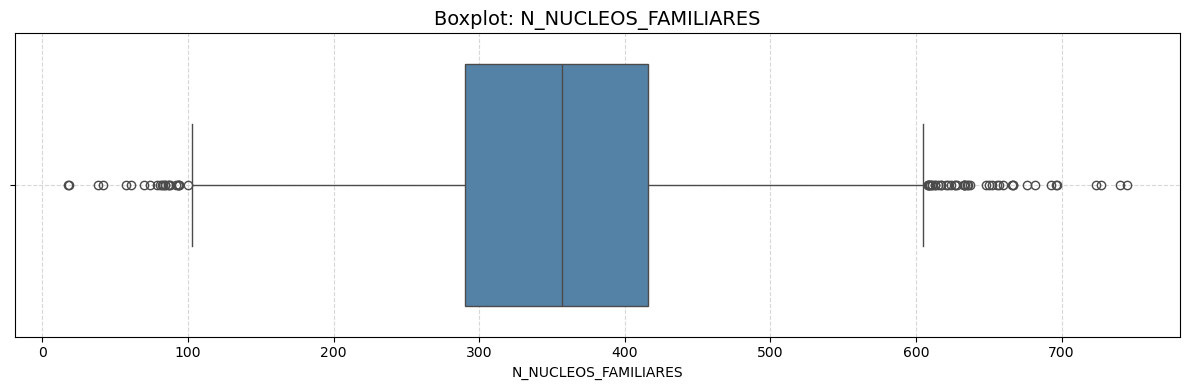

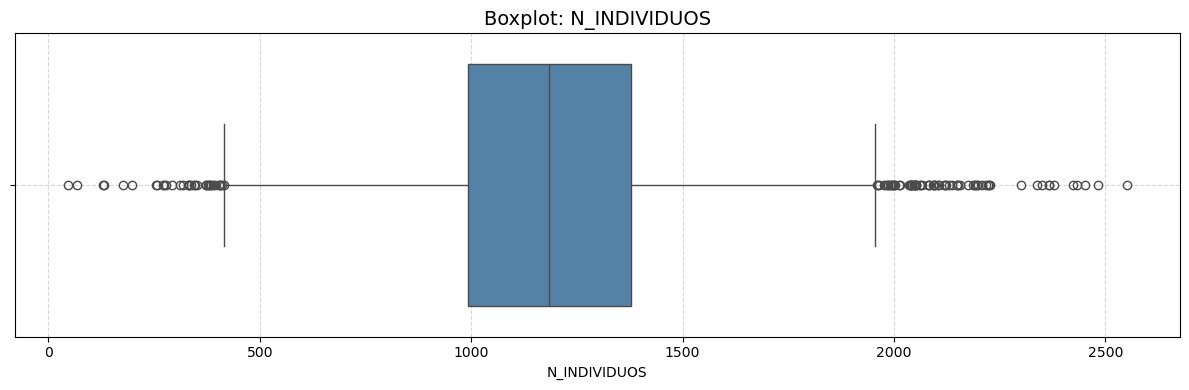

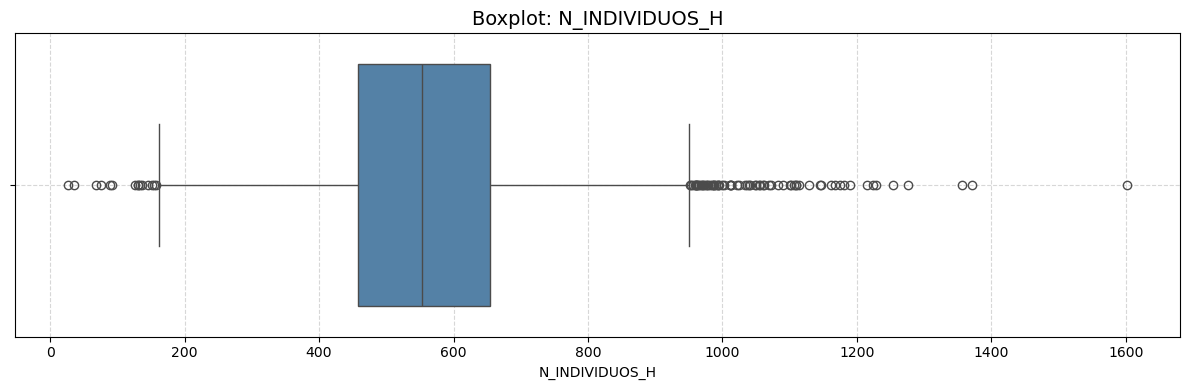

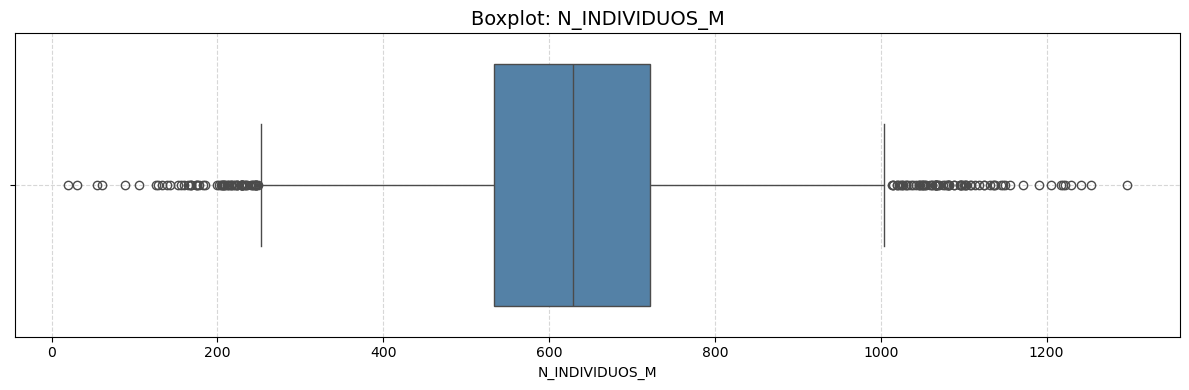

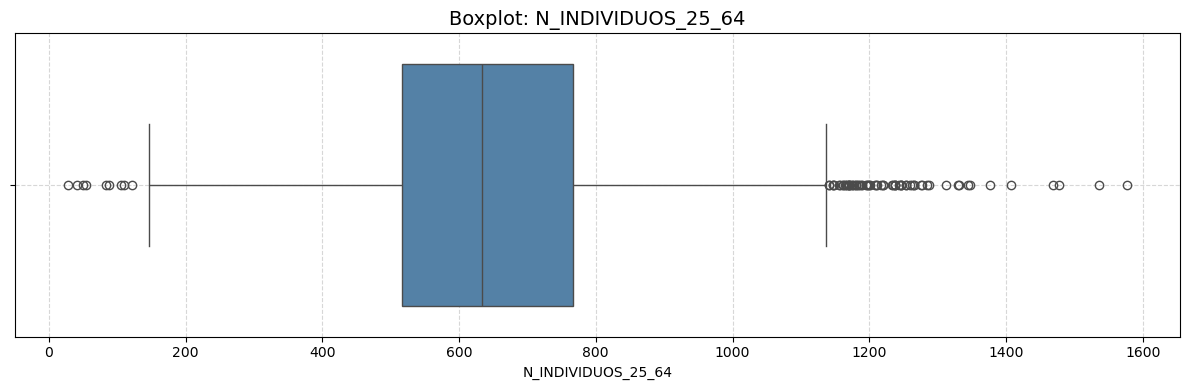

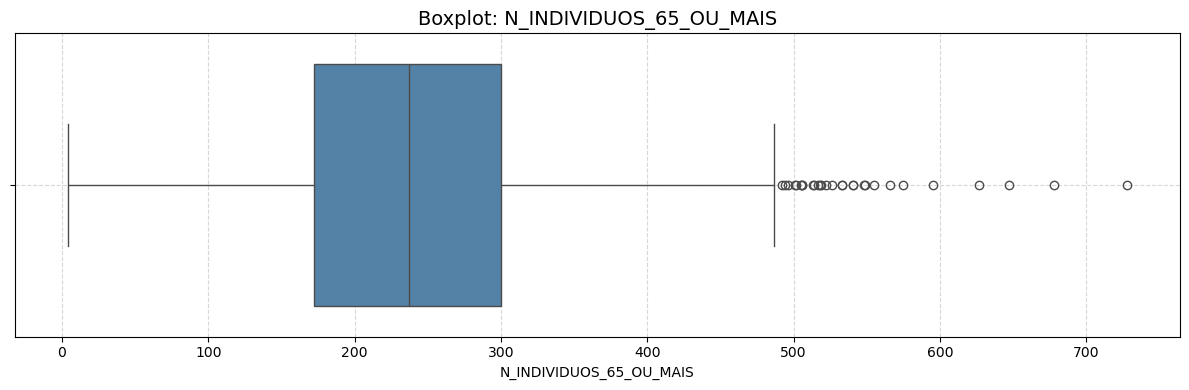

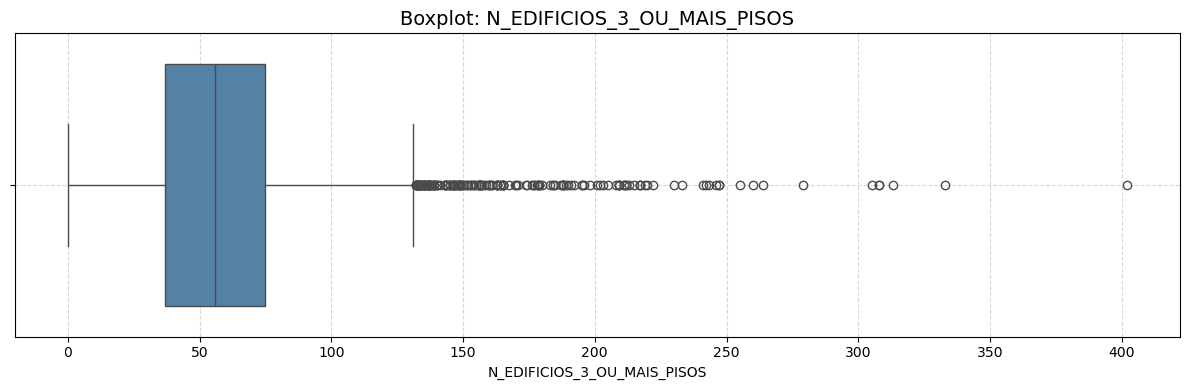

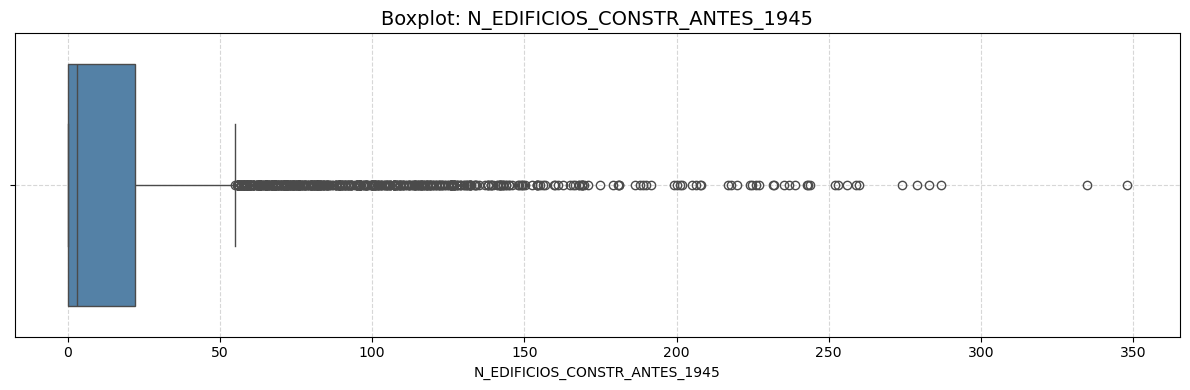

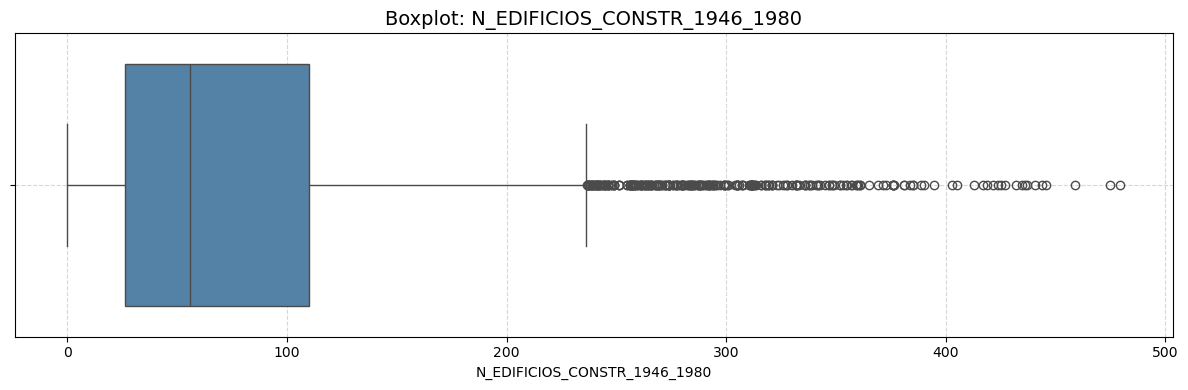

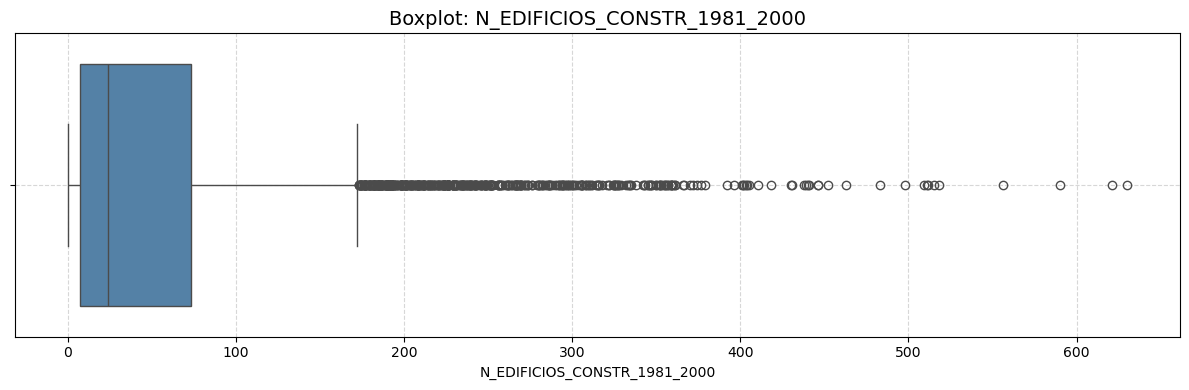

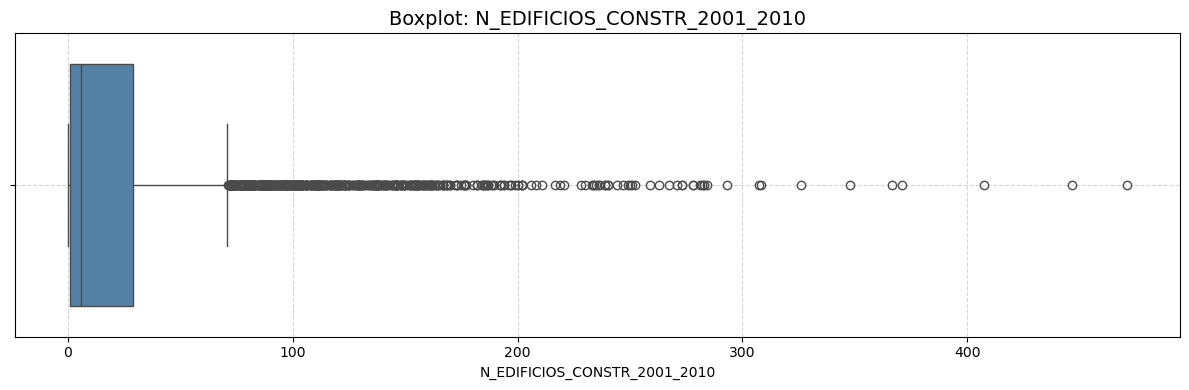

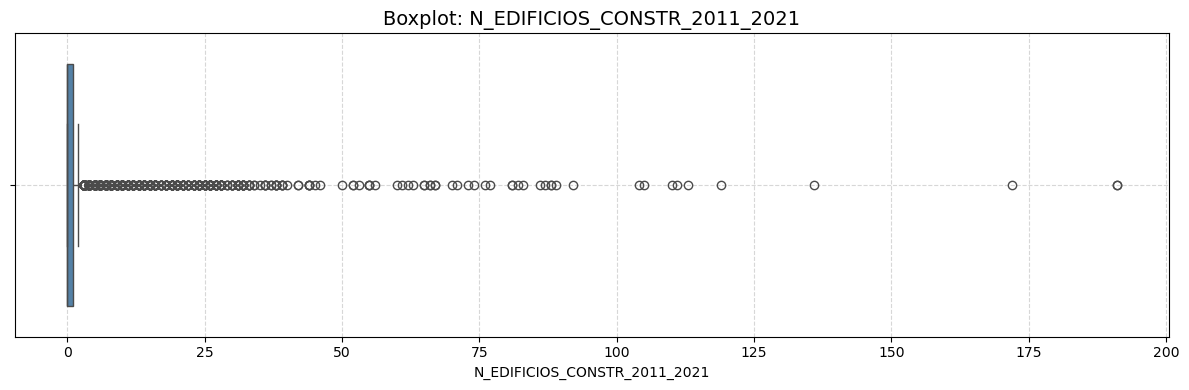

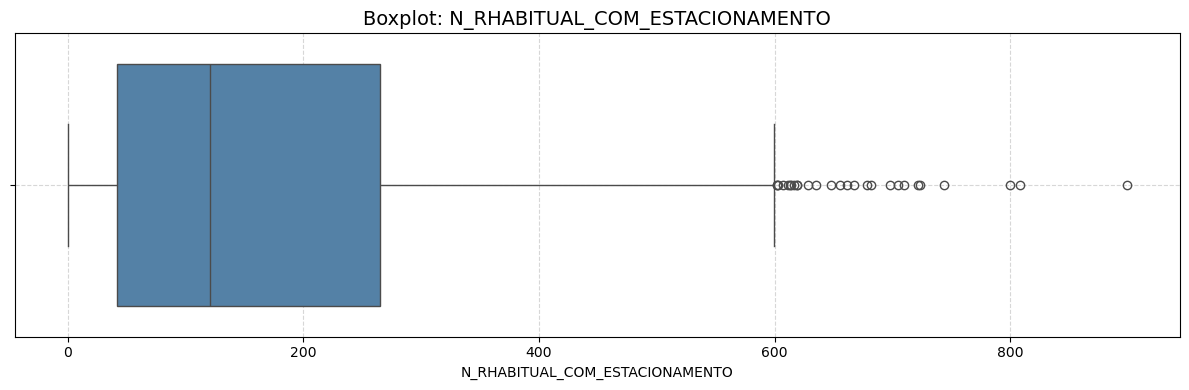

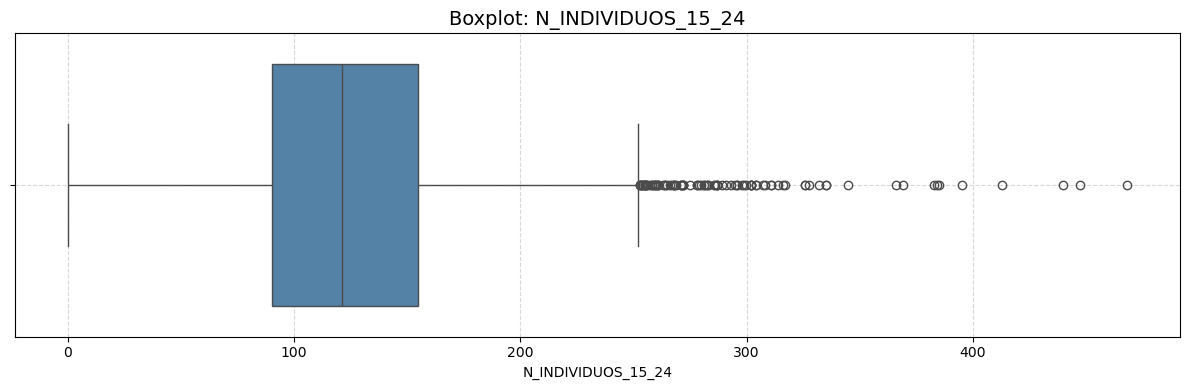

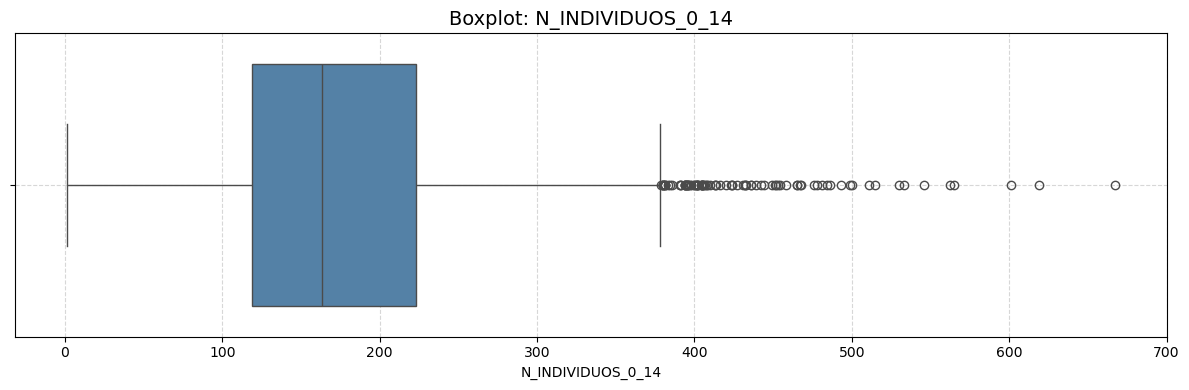

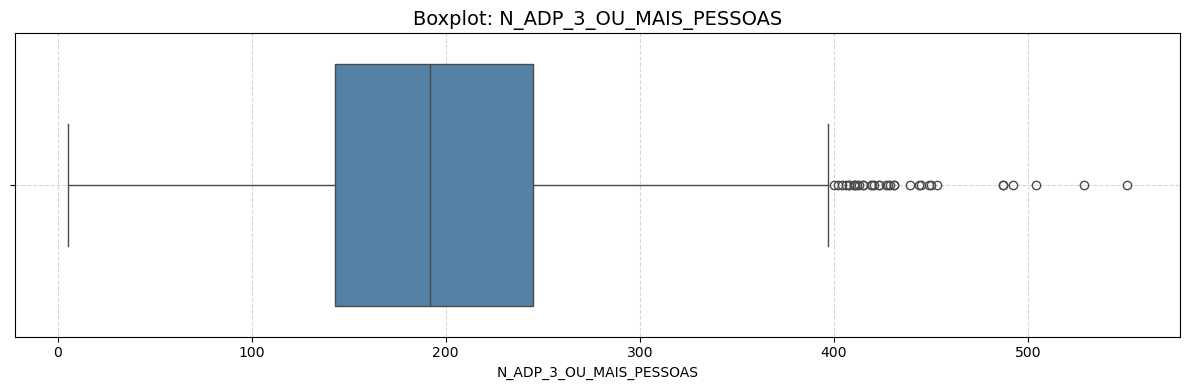

In [22]:
def plot_all_boxplots(df, figsize=(12, 4)):
    for col in df.columns:
        fig, ax = plt.subplots(figsize=figsize)
        sns.boxplot(x=df[col], color='steelblue', ax=ax)
        ax.set_title(f'Boxplot: {col}', fontsize=14)
        ax.set_xlabel(col)
        ax.grid(linestyle='--', alpha=0.5)
        plt.tight_layout()
        plt.show()

plot_all_boxplots(numeric_cols)

---

<a id='5'></a>

## 5. SOM Training — Grid Search



### 5.1 Evaluation Functions



We evaluate each SOM configuration with two complementary metrics:



- **Quantization Error (QE):** average distance between each observation and its winning neuron (BMU). Measures how well the map represents the data — lower is better.

- **Topographic Error (TE):** fraction of observations whose second-best BMU is not adjacent to the first. Measures topology preservation — lower is better.





In [23]:
def quantization_error(som, data):
    return np.mean([
        np.linalg.norm(x - som.get_weights()[som.winner(x)])
        for x in data
    ])

def topographic_error(som, data):
    errors  = 0
    weights = som.get_weights()
    for x in data:
        bmu1  = som.winner(x)
        dists = np.linalg.norm(weights - x, axis=2)
        dists[bmu1] = np.inf
        bmu2  = np.unravel_index(np.argmin(dists), dists.shape)
        if max(abs(bmu1[0] - bmu2[0]), abs(bmu1[1] - bmu2[1])) > 1:
            errors += 1
    return errors / len(data)

### 5.2 Grid Search



The grid search tests all hyperparameter combinations defined in `param_grid`.


The composite score normalises QE and TE to [0,1] and takes the weighted average. The model with the minimum score is the best trade-off between representation and topology.



In [24]:
def som_grid_search(data, param_grid, n_iter=SOM_ITER, random_seed=RANDOM_SEED):

    keys, values = zip(*param_grid.items())

    combos       = [dict(zip(keys, v)) for v in product(*values)]

    results      = []



    for params in combos:

        som = MiniSom(

            x=params['grid_x'], y=params['grid_y'],

            input_len=data.shape[1],

            sigma=params['sigma'],

            learning_rate=params['learning_rate'],

            topology=params['topology'],

            random_seed=random_seed,

        )

        som.train_random(data, n_iter)



        qe = quantization_error(som, data)

        te = topographic_error(som, data)

        results.append({**params, 'qe': qe, 'te': te})

        print(f"grid={params['grid_x']}x{params['grid_y']} "

              f"σ={params['sigma']} lr={params['learning_rate']} "

              f"topo={params['topology']} | QE={qe:.4f} TE={te:.4f}")



    results_df          = pd.DataFrame(results)

    results_df['qe_norm'] = (results_df['qe'] - results_df['qe'].min()) / np.ptp(results_df['qe'].values)

    results_df['te_norm'] = (results_df['te'] - results_df['te'].min()) / np.ptp(results_df['te'].values)

    results_df['score']   = 0.5 * results_df['qe_norm'] + 0.5 * results_df['te_norm']



    best_idx    = results_df['score'].idxmin()

    best_params = results_df.loc[best_idx]



    best_som = MiniSom(

        x=int(best_params['grid_x']), y=int(best_params['grid_y']),

        input_len=data.shape[1],

        sigma=best_params['sigma'],

        learning_rate=best_params['learning_rate'],

        topology=best_params['topology'],

        random_seed=random_seed,

    )

    best_som.train_random(data, n_iter)



    return best_som, results_df, best_params



param_grid = {

    'grid_x':        [25, 35, 45, 50],

    'grid_y':        [25, 35, 45, 50],

    'sigma':         [3.0, 5.0],

    'learning_rate': [0.3, 0.5, 0.7],

    'topology':      ['rectangular'],

}

# Use the best-preprocessed data from Section 3b if available,
# otherwise fall back to the default scaled features.
if 'X_final' not in dir():
    data = scaled_pooled.values

print(f"SOM input shape: {data.shape}")

best_som, results_df, best_params = som_grid_search(data, param_grid)



print("\nMelhor configuração:")

print(best_params[['grid_x','grid_y','sigma','learning_rate','topology','qe','te','score']])

SOM input shape: (4798, 18)
grid=25x25 σ=3.0 lr=0.3 topo=rectangular | QE=0.2081 TE=0.0571
grid=25x25 σ=3.0 lr=0.5 topo=rectangular | QE=0.2057 TE=0.0727
grid=25x25 σ=3.0 lr=0.7 topo=rectangular | QE=0.2061 TE=0.0830
grid=25x25 σ=5.0 lr=0.3 topo=rectangular | QE=0.2336 TE=0.0227
grid=25x25 σ=5.0 lr=0.5 topo=rectangular | QE=0.2345 TE=0.0317
grid=25x25 σ=5.0 lr=0.7 topo=rectangular | QE=0.2302 TE=0.0509
grid=25x35 σ=3.0 lr=0.3 topo=rectangular | QE=0.2048 TE=0.0561
grid=25x35 σ=3.0 lr=0.5 topo=rectangular | QE=0.1974 TE=0.0767
grid=25x35 σ=3.0 lr=0.7 topo=rectangular | QE=0.1950 TE=0.0834
grid=25x35 σ=5.0 lr=0.3 topo=rectangular | QE=0.2223 TE=0.0213
grid=25x35 σ=5.0 lr=0.5 topo=rectangular | QE=0.2226 TE=0.0340
grid=25x35 σ=5.0 lr=0.7 topo=rectangular | QE=0.2217 TE=0.0471
grid=25x45 σ=3.0 lr=0.3 topo=rectangular | QE=0.2065 TE=0.0617
grid=25x45 σ=3.0 lr=0.5 topo=rectangular | QE=0.1973 TE=0.0836
grid=25x45 σ=3.0 lr=0.7 topo=rectangular | QE=0.1925 TE=0.0973
grid=25x45 σ=5.0 lr=0.3 top

In [25]:
best_params

grid_x                    50
grid_y                    50
sigma                    5.0
learning_rate            0.5
topology         rectangular
qe                   0.19161
te                  0.032097
qe_norm             0.240945
te_norm             0.142466
score               0.191705
Name: 94, dtype: object

---

<a id='6'></a>

## 6. Clustering on Neurons



### 6.1 Selecting the Number of Clusters



Instead of clustering directly on the ~5000 observations, we run KMeans on the **SOM neuron weights**. This is computationally more efficient and leverages the SOM's ability to smooth the feature space.



We use three criteria to select `k`:

- **Elbow Method (Inertia):** we look for the point where the reduction in inertia slows down.

- **Silhouette Score:** measures cluster separation - higher is better.

- **Davies-Bouldin Index:** measures compactness and separation - lower is better.

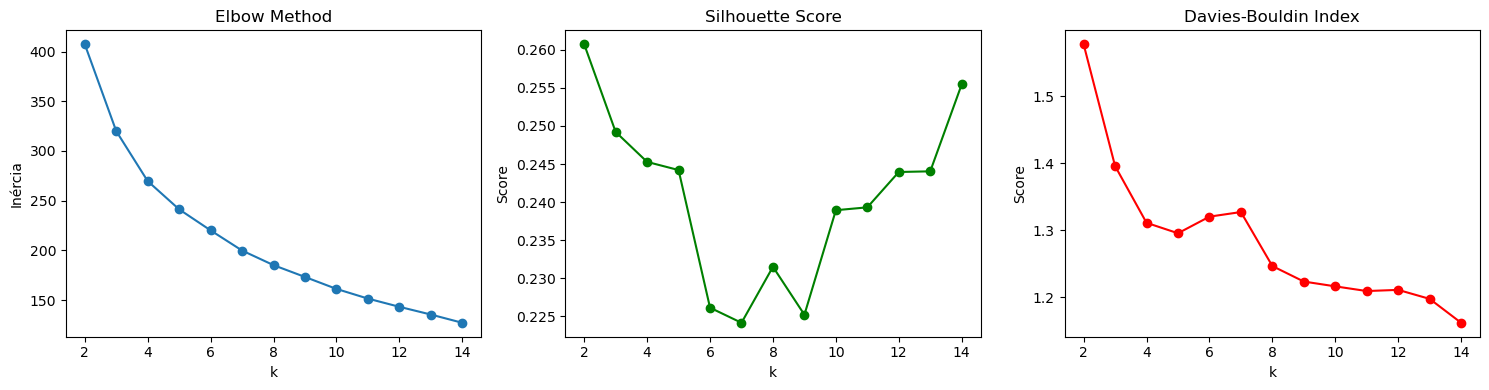

In [26]:
weights     = best_som.get_weights().reshape(-1, scaled_pooled.shape[1])
k_range     = range(2, 15)
inertias, silhouettes, db_scores = [], [], []

for k in k_range:
    km     = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    labels = km.fit_predict(weights)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(weights, labels))
    db_scores.append(davies_bouldin_score(weights, labels))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].plot(k_range, inertias, marker='o')
axes[0].set_title('Elbow Method')
axes[0].set_xlabel('k'); axes[0].set_ylabel('Inércia')

axes[1].plot(k_range, silhouettes, marker='o', color='green')
axes[1].set_title('Silhouette Score')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Score')

axes[2].plot(k_range, db_scores, marker='o', color='red')
axes[2].set_title('Davies-Bouldin Index')
axes[2].set_xlabel('k'); axes[2].set_ylabel('Score')

plt.tight_layout()
plt.show()

In [27]:
OPTIMAL_K = 5

### 6.2 Cluster Assignment



With `OPTIMAL_K` defined in the configuration cell, we train the final KMeans on the SOM weights. Each neuron receives a cluster label. We then map each observation in `pooled_data` to its BMU and, by extension, to that neuron's cluster.

In [28]:
km_final     = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_SEED, n_init=10)
node_labels  = km_final.fit_predict(weights)

grid_y = int(best_params['grid_y'])

def assign_cluster(row, som, node_labels, grid_y):
    bmu      = som.winner(row)
    node_idx = bmu[0] * grid_y + bmu[1]
    return node_labels[node_idx]

feature_cols              = [c for c in scaled_pooled.columns if c != 'cluster']
scaled_pooled['cluster']  = [
    assign_cluster(row, best_som, node_labels, grid_y)
    for row in scaled_pooled[feature_cols].values
]
pooled_data['cluster']    = scaled_pooled['cluster'].values

print("Distribuição de clusters:")
print(pooled_data.groupby(['ANO','cluster']).size().unstack(fill_value=0))

Distribuição de clusters:
cluster    0    1    2    3    4
ANO                             
2011     159  647  852  336  405
2021     240  435  993  343  388


In [29]:
from sklearn.metrics import adjusted_rand_score

ALT_SEEDS = [0, 1, 7, 123]          # alternative seeds (main run uses RANDOM_SEED=42)
base_labels = node_labels           # the k=5 labels used throughout the thesis

print(f"Cluster-stability check (k={OPTIMAL_K}), reference seed = {RANDOM_SEED}")
print("-" * 60)
ari_scores = []
for s in ALT_SEEDS:
    km_s   = KMeans(n_clusters=OPTIMAL_K, random_state=s, n_init=10)
    lbl_s  = km_s.fit_predict(weights)
    ari    = adjusted_rand_score(base_labels, lbl_s)
    ari_scores.append(ari)
    print(f"  seed={s:<4d}  ARI vs main solution = {ari:.4f}")

print("-" * 60)
print(f"Mean ARI across {len(ALT_SEEDS)} alternative seeds : {np.mean(ari_scores):.4f}")
print(f"Min  ARI                                        : {np.min(ari_scores):.4f}")
print("(ARI = 1.0 → identical partition; >0.90 → highly stable assignment)")

Cluster-stability check (k=5), reference seed = 42
------------------------------------------------------------
  seed=0     ARI vs main solution = 0.9095
  seed=1     ARI vs main solution = 0.9110
  seed=7     ARI vs main solution = 0.9003
  seed=123   ARI vs main solution = 0.9119
------------------------------------------------------------
Mean ARI across 4 alternative seeds : 0.9082
Min  ARI                                        : 0.9003
(ARI = 1.0 → identical partition; >0.90 → highly stable assignment)


### 6.3 Transition Matrix



The transition matrix shows how many sections moved from cluster `i` (2011) to cluster `j` (2021). The main diagonal represents sections that remained in the same cluster - the larger the diagonal, the more stable the socioeconomic structure of the AML.

      Para 0  Para 1  Para 2  Para 3  Para 4
De 0     127       6      16       1       9
De 1      74     396     165       7       5
De 2       8       2     775      64       3
De 3       0      29      33     268       6
De 4      31       2       4       3     365


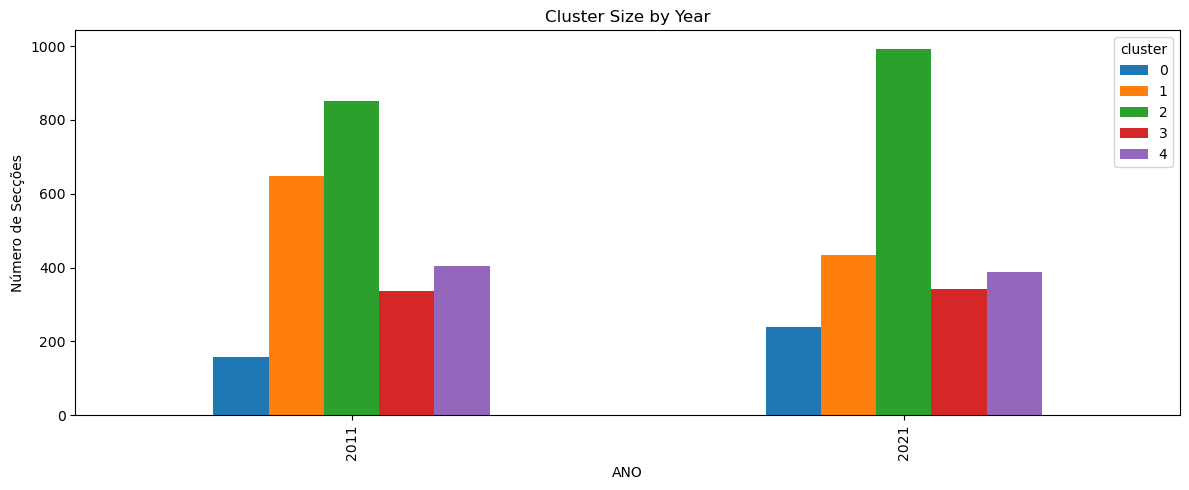

In [30]:
trajectory = pooled_data.pivot_table(index='DTMNFRSEC21', columns='ANO', values='cluster')

def transition_matrix(df, year1, year2, k):
    matrix = np.zeros((k, k), dtype=int)
    for _, row in df.iterrows():
        c1, c2 = row[year1], row[year2]
        if pd.notna(c1) and pd.notna(c2):
            matrix[int(c1)][int(c2)] += 1
    return pd.DataFrame(matrix,
                        index=[f'De {i}' for i in range(k)],
                        columns=[f'Para {j}' for j in range(k)])

trans = transition_matrix(trajectory, 2011, 2021, OPTIMAL_K)
print(trans)

cluster_counts = pooled_data.groupby(['ANO','cluster']).size().unstack(fill_value=0)
cluster_counts.plot(kind='bar', figsize=(12, 5), title='Cluster Size by Year')
plt.ylabel('Número de Secções')
plt.tight_layout()
plt.show()

In [31]:
# === PCA ROBUSTNESS: does the transition structure survive PCA compression? ===
# Re-runs the full pipeline (preprocess→SOM→KMeans→assign→transition) on the
# PCA-compressed configuration and compares dominant transitions to the
# interpretable (non-PCA) solution used in the thesis.

# 1) Build the PCA-compressed feature space (same winning config, PCA on)
X_pca = _build_preprocessed(
    df11_raw, df21_raw,
    scaler_name   = best_cfg['scaler'],
    var_set       = best_cfg['var_set'],
    use_ilr       = bool(best_cfg['ilr']),
    joint_scaling = bool(best_cfg['joint']),
    use_pca       = True,
)

# 2) Train a SOM with the SAME hyperparameters selected in Section 5
gx, gy = int(best_params['grid_x']), int(best_params['grid_y'])
som_pca = MiniSom(x=gx, y=gy, input_len=X_pca.shape[1],
                  sigma=best_params['sigma'],
                  learning_rate=best_params['learning_rate'],
                  topology=best_params['topology'],
                  random_seed=RANDOM_SEED)
som_pca.train_random(X_pca, SOM_ITER)

# 3) K-Means (k=5) on the PCA-SOM neuron weights
w_pca   = som_pca.get_weights().reshape(-1, X_pca.shape[1])
km_pca  = KMeans(n_clusters=OPTIMAL_K, random_state=RANDOM_SEED, n_init=10)
lbl_pca = km_pca.fit_predict(w_pca)

# 4) Assign every section (2011 & 2021) to a PCA cluster via its BMU
def _assign_pca(row_vec):
    bx, by = som_pca.winner(row_vec)
    return lbl_pca[bx * gy + by]

pca_clusters = np.array([_assign_pca(r) for r in X_pca])
pca_pooled = pooled_data[['DTMNFRSEC21', 'ANO']].copy()
pca_pooled['cluster_pca'] = pca_clusters

# 5) Build the PCA transition matrix
traj_pca = pca_pooled.pivot_table(index='DTMNFRSEC21', columns='ANO', values='cluster_pca')
trans_pca = transition_matrix(traj_pca, 2011, 2021, OPTIMAL_K)

# 6) Diagonal (stability) rate under PCA
diag_pca   = np.trace(trans_pca.values)
total_pca  = trans_pca.values.sum()
print("PCA TRANSITION MATRIX (k=5)")
print(trans_pca)
print(f"\nOverall stability under PCA : {100*diag_pca/total_pca:.1f}% "
      f"(interpretable pipeline reported ~80.5%)")
print("\nNote: cluster *numbers* are arbitrary and need not match the "
      "interpretable run — read the STRUCTURE (one dominant off-diagonal "
      "source feeding two destinations), not the label indices.")

      PCA: 7 components (90% var) PCA TRANSITION MATRIX (k=5)
      Para 0  Para 1  Para 2  Para 3  Para 4
De 0     393       2       1       2       6
De 1      21     404       6      13     157
De 2       0       0     318      25      25
De 3      12      37      10     287      59
De 4       1       7      34      14     565

Overall stability under PCA : 82.0% (interpretable pipeline reported ~80.5%)

Note: cluster *numbers* are arbitrary and need not match the interpretable run — read the STRUCTURE (one dominant off-diagonal source feeding two destinations), not the label indices.


---

<a id='7'></a>

## 7. Trajectory Analysis



For each statistical section we compute its position on the SOM grid in 2011 and in 2021. The **Euclidean distance** between the two positions on the grid measures the intensity of socioeconomic transformation: a section that remains on the same neuron has distance 0; one that migrates to the opposite corner of the grid underwent a profound transformation.

In [32]:
bmus = [best_som.winner(d) for d in scaled_pooled[feature_cols].values]

pooled_data['som_x'] = [b[0] for b in bmus]
pooled_data['som_y'] = [b[1] for b in bmus]

df_2011_pos = pooled_data[pooled_data['ANO'] == 2011][['DTMNFRSEC21','som_x','som_y']]
df_2021_pos = pooled_data[pooled_data['ANO'] == 2021][['DTMNFRSEC21','som_x','som_y']]

df_trajetorias = pd.merge(
    df_2011_pos, df_2021_pos,
    on='DTMNFRSEC21', suffixes=('_2011','_2021')
)

df_trajetorias['distancia_trajetoria'] = np.sqrt(
    (df_trajetorias['som_x_2021'] - df_trajetorias['som_x_2011'])**2 +
    (df_trajetorias['som_y_2021'] - df_trajetorias['som_y_2011'])**2
)

print(df_trajetorias['distancia_trajetoria'].describe())

count    2399.000000
mean        7.354498
std        11.529441
min         0.000000
25%         1.000000
50%         2.236068
75%         8.031129
max        57.489129
Name: distancia_trajetoria, dtype: float64


In [33]:
zero_displacement_count = (df_trajetorias['distancia_trajetoria'] == 0).sum()
total_sections = len(df_trajetorias)
pct_zero_disp = (zero_displacement_count / total_sections) * 100

print(f"Sections with zero displacement: {zero_displacement_count} out of {total_sections}")
print(f"Percentage: {pct_zero_disp:.1f}%")

Sections with zero displacement: 377 out of 2399
Percentage: 15.7%


In [34]:
# === TRAJECTORY DISTANCE CALIBRATION: what does a grid displacement mean? ===
# Translates abstract SOM-grid distances into real census-variable terms by
# profiling the 5 highest-displacement and 5 zero-displacement sections.

# Pivot raw (unscaled) census values per section per year for interpretability
id_col   = 'DTMNFRSEC21'
prof_vars = numeric_cols.columns.tolist()

raw_2011 = pooled_data[pooled_data['ANO'] == 2011].set_index(id_col)[prof_vars]
raw_2021 = pooled_data[pooled_data['ANO'] == 2021].set_index(id_col)[prof_vars]

# Pick the 5 most-displaced and 5 zero-displacement sections
top5  = df_trajetorias.nlargest(5, 'distancia_trajetoria')[[id_col, 'distancia_trajetoria']]
zero5 = (df_trajetorias[df_trajetorias['distancia_trajetoria'] == 0]
         .head(5)[[id_col, 'distancia_trajetoria']])

# A compact set of substantively meaningful variables for the illustrative table
KEY_VARS = ['N_INDIVIDUOS', 'N_INDIVIDUOS_65_OU_MAIS', 'N_RHABITUAL_PROP_OCUP',
            'N_RHABITUAL_ARRENDADOS', 'N_EDIFICIOS_CONSTR_2001_2010']
KEY_VARS = [v for v in KEY_VARS if v in prof_vars]

def _profile_block(sel_df, label):
    rows = []
    for _, r in sel_df.iterrows():
        sid = r[id_col]
        d   = r['distancia_trajetoria']
        rec = {'section': sid, 'traj_dist': round(d, 2)}
        for v in KEY_VARS:
            v11 = raw_2011.loc[sid, v] if sid in raw_2011.index else np.nan
            v21 = raw_2021.loc[sid, v] if sid in raw_2021.index else np.nan
            rec[f'{v}_2011'] = round(float(v11), 1)
            rec[f'{v}_2021'] = round(float(v21), 1)
        rows.append(rec)
    block = pd.DataFrame(rows)
    print(f"\n{'='*70}\n{label}\n{'='*70}")
    print(block.to_string(index=False))
    return block

calib_top  = _profile_block(top5,  "TOP 5 — largest trajectory displacement")
calib_zero = _profile_block(zero5, "5 sections with ZERO displacement (stable)")

# Aggregate contrast: mean 2011→2021 change for high vs zero displacement
print(f"\n{'='*70}\nMEAN |2021 − 2011| CHANGE: high-displacement vs stable sections\n{'='*70}")
for v in KEY_VARS:
    hi = (raw_2021.loc[top5[id_col], v].values - raw_2011.loc[top5[id_col], v].values)
    lo = (raw_2021.loc[zero5[id_col], v].values - raw_2011.loc[zero5[id_col], v].values)
    print(f"  {v:<32s} high Δ={np.nanmean(np.abs(hi)):8.1f}   stable Δ={np.nanmean(np.abs(lo)):8.1f}")


TOP 5 — largest trajectory displacement
  section  traj_dist  N_INDIVIDUOS_2011  N_INDIVIDUOS_2021  N_INDIVIDUOS_65_OU_MAIS_2011  N_INDIVIDUOS_65_OU_MAIS_2021  N_RHABITUAL_PROP_OCUP_2011  N_RHABITUAL_PROP_OCUP_2021  N_RHABITUAL_ARRENDADOS_2011  N_RHABITUAL_ARRENDADOS_2021  N_EDIFICIOS_CONSTR_2001_2010_2011  N_EDIFICIOS_CONSTR_2001_2010_2021
150314036      57.49              671.0             1052.0                         161.0                         234.0                       207.0                       343.0                         16.0                         27.0                               99.0                              104.0
150314039      57.49              675.3             1122.0                         135.7                         245.0                       222.7                       325.0                         20.4                         57.0                              128.1                              161.0
110913001      57.31              745.0           

---

<a id='8'></a>

## 8. Final Visualisations



### 8.1 U-Matrix with Clusters and Transition Arrows



The U-Matrix (Unified Distance Matrix) is the main SOM interpretation tool. Each cell represents the average distance of the neuron to its neighbours:

- **Dark zones (high distance)** → boundaries between distinct regions of the feature space.

- **Light zones (low distance)** → homogeneous regions where neurons are similar to each other.



The colour overlay shows which cluster each neuron belongs to. The arrows indicate the average migration of each cluster between 2011 and 2021 — their direction and length summarise the collective trajectory of each type of section.


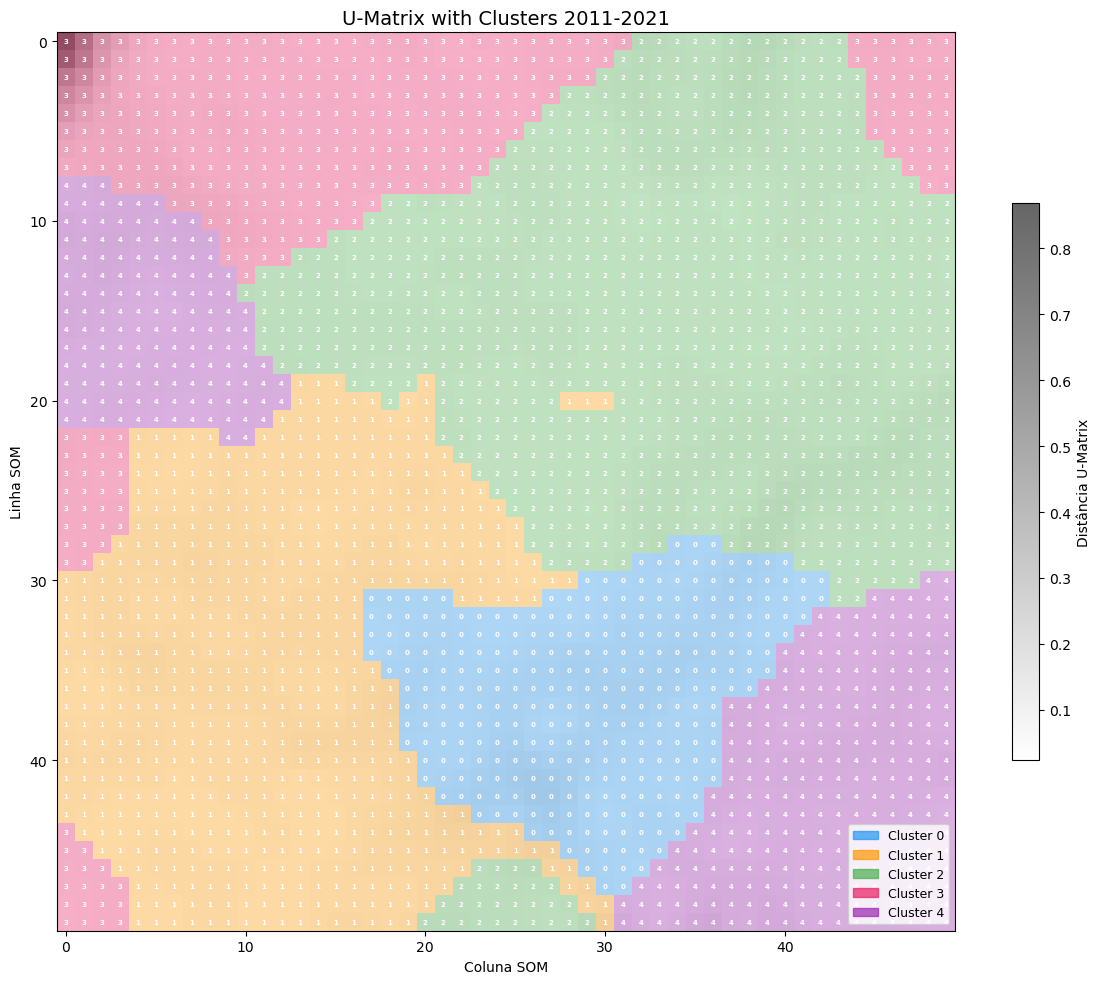

In [35]:
def plot_umatrix_with_clusters(som, node_labels, grid_x, grid_y,
                                year_data=None, title='U-Matrix'):
    weights  = som.get_weights()
    umatrix  = np.zeros((grid_x, grid_y))

    for i in range(grid_x):
        for j in range(grid_y):
            neighbors = []
            for di, dj in [(-1,0),(1,0),(0,-1),(0,1)]:
                ni, nj = i+di, j+dj
                if 0 <= ni < grid_x and 0 <= nj < grid_y:
                    neighbors.append(np.linalg.norm(weights[i,j] - weights[ni,nj]))
            umatrix[i,j] = np.mean(neighbors)

    cluster_map = node_labels.reshape(grid_x, grid_y)
    fig, ax     = plt.subplots(figsize=(12, 10))

    um = ax.imshow(umatrix, cmap='gray_r', alpha=0.6, interpolation='nearest')
    plt.colorbar(um, ax=ax, label='Distância U-Matrix', shrink=0.6)

    colors = [
        '#2196F3',
        '#FF9800',
        '#4CAF50',
        '#E91E63',
        '#9C27B0',
        '#CDDC39',
        '#F44336'
    ]
    cmap = ListedColormap(colors[:len(np.unique(node_labels))])
    ax.imshow(cluster_map, cmap=cmap, alpha=0.35, interpolation='nearest')

    for i in range(grid_x):
        for j in range(grid_y):
            ax.text(j, i, str(cluster_map[i,j]),
                    ha='center', va='center', fontsize=5,
                    color='white', fontweight='bold')

    patches = [mpatches.Patch(color=colors[i], label=f'Cluster {i}', alpha=0.7)
               for i in range(len(np.unique(node_labels)))]
    ax.legend(handles=patches, loc='lower right', fontsize=9)

    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Coluna SOM'); ax.set_ylabel('Linha SOM')
    plt.tight_layout()
    plt.show()


year_data = {
    2011: scaled_pooled.loc[pooled_data['ANO'] == 2011, feature_cols].reset_index(drop=True),
    2021: scaled_pooled.loc[pooled_data['ANO'] == 2021, feature_cols].reset_index(drop=True),
}

plot_umatrix_with_clusters(
    best_som, node_labels,
    int(best_params['grid_x']),
    int(best_params['grid_y']),
    year_data=year_data,
    title='U-Matrix with Clusters 2011-2021'
)

### 8.2 Hit Matrix — Distribution 2011 vs 2021



The Hit Matrix shows where the statistical sections "land" on the SOM grid. Circles represent 2011 sections and squares the 2021 ones. Random jitter prevents total overlap when multiple sections share the same winning neuron.



Comparing the two distributions reveals whether there was a systematic migration of sections towards other regions of the grid — which would indicate a structural transformation of the AML.

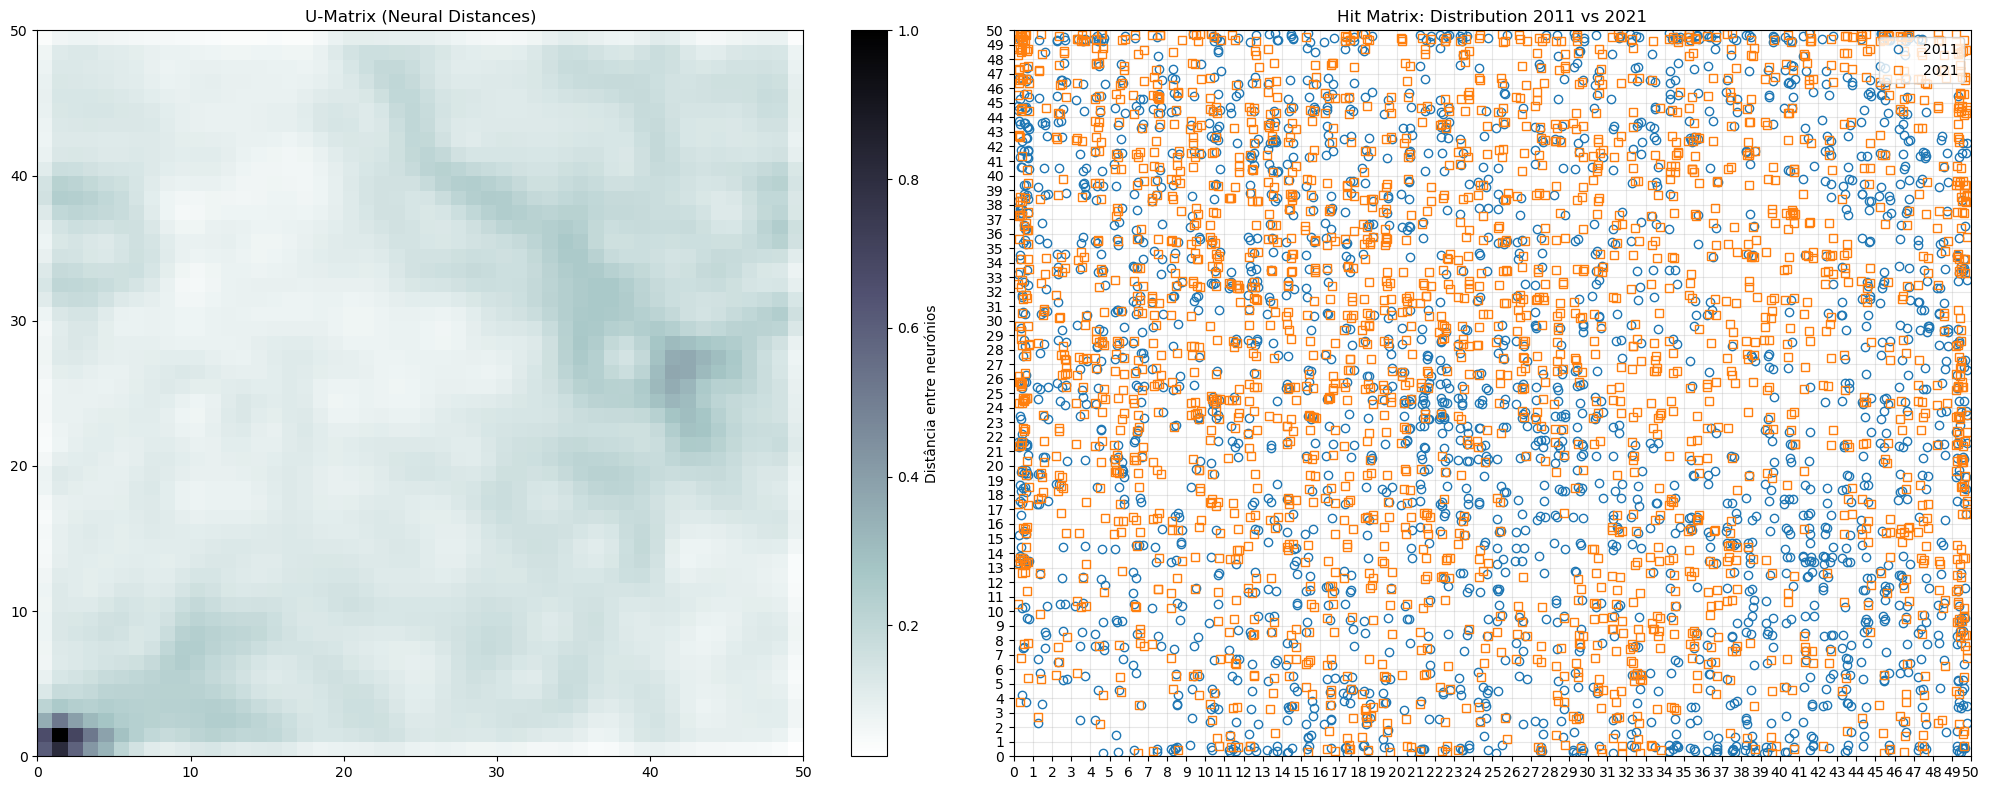

In [36]:
som_width  = int(best_params['grid_x'])
som_height = int(best_params['grid_y'])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 8))

u_matrix = best_som.distance_map().T
im1 = ax1.pcolor(u_matrix, cmap='bone_r')
fig.colorbar(im1, ax=ax1, label='Distância entre neurónios')
ax1.set_title('U-Matrix (Neural Distances)')

markers = {2011: 'o', 2021: 's'}
colors  = {2011: 'C0', 2021: 'C1'}

ax2.pcolor(np.zeros((som_width, som_height)).T, cmap='Greys', alpha=0.1)

np.random.seed(RANDOM_SEED)
for i, x in enumerate(data):
    w   = best_som.winner(x)
    ano = pooled_data.iloc[i]['ANO']
    jitter_x = w[0] + 0.5 + np.random.uniform(-0.3, 0.3)
    jitter_y = w[1] + 0.5 + np.random.uniform(-0.3, 0.3)
    ax2.plot(jitter_x, jitter_y, markers[ano],
             markerfacecolor='None', markeredgecolor=colors[ano],
             markersize=6, markeredgewidth=1)

legend_elements = [
    Line2D([0],[0], marker='o', color='C0', label='2011', markerfacecolor='None', linestyle='None'),
    Line2D([0],[0], marker='s', color='C1', label='2021', markerfacecolor='None', linestyle='None')
]
ax2.legend(handles=legend_elements, loc='upper right')
ax2.set_title('Hit Matrix: Distribution 2011 vs 2021')
ax2.set_xticks(range(som_width + 1))
ax2.set_yticks(range(som_height + 1))
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 8.3 Density Heatmaps by Year



The density heatmaps quantify the number of sections per grid cell in each year. Unlike the hit matrix, there is no overlap of points - each cell has a clear numeric value. Gaussian interpolation smooths the visualisation and helps identify the regions of highest concentration.

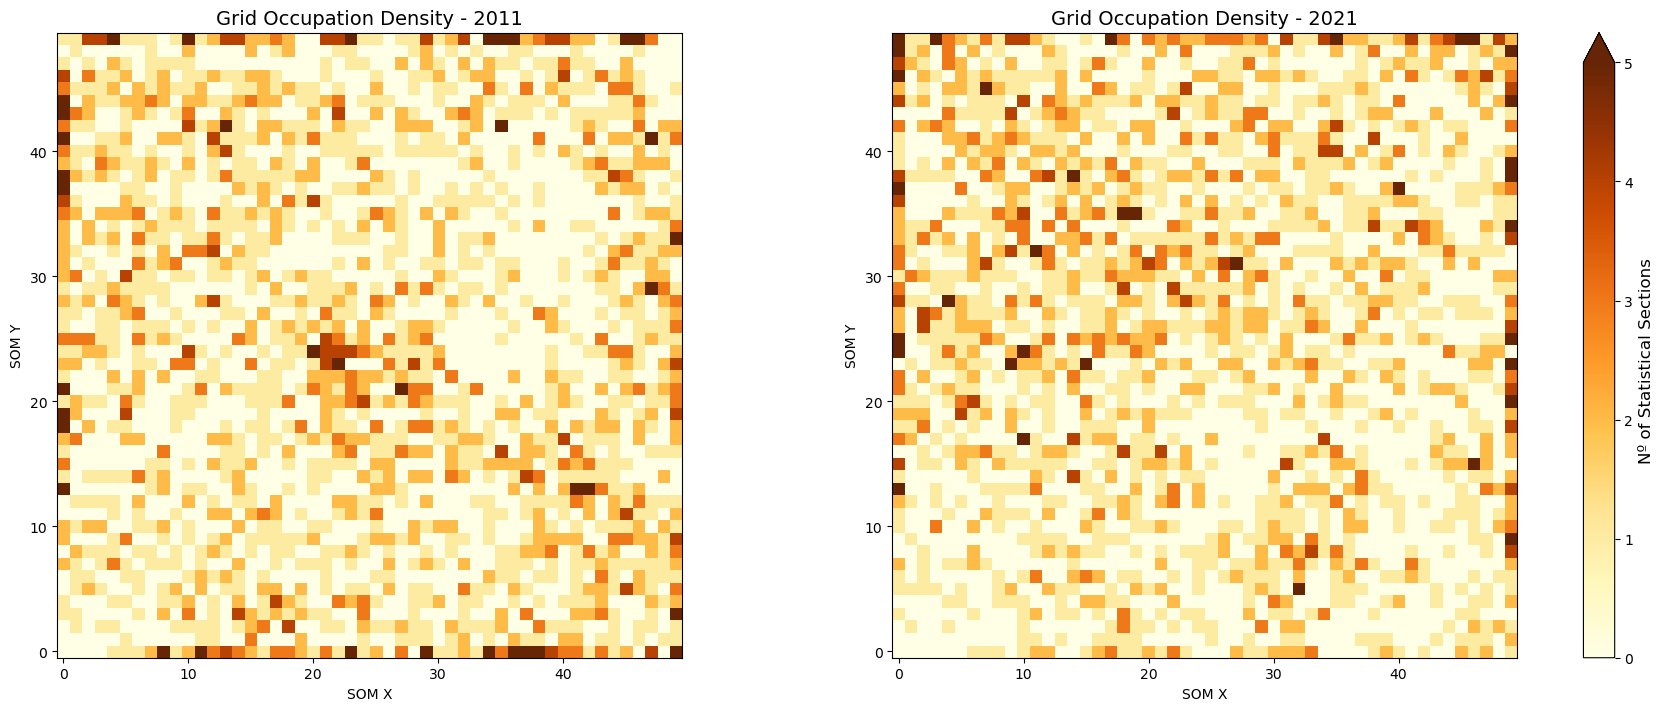

In [61]:
hits_2011 = np.zeros((som_width, som_height))
hits_2021 = np.zeros((som_width, som_height))

for i, x in enumerate(data):
    w   = best_som.winner(x)
    ano = pooled_data.iloc[i]['ANO']
    if ano == 2011:
        hits_2011[w[0], w[1]] += 1
    else:
        hits_2021[w[0], w[1]] += 1

# Escala robusta: usar percentil em vez do máximo absoluto,
# para que um único outlier não esmague a escala de cor
vmax_shared = np.percentile(np.concatenate([hits_2011.ravel(), hits_2021.ravel()]), 99)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)

im1 = ax1.imshow(hits_2011.T, cmap='YlOrBr', origin='lower', interpolation='nearest',
                  vmin=0, vmax=vmax_shared)
ax1.set_title('Grid Occupation Density - 2011', fontsize=14)
ax1.set_xlabel('SOM X'); ax1.set_ylabel('SOM Y')

im2 = ax2.imshow(hits_2021.T, cmap='YlOrBr', origin='lower', interpolation='nearest',
                  vmin=0, vmax=vmax_shared)
ax2.set_title('Grid Occupation Density - 2021', fontsize=14)
ax2.set_xlabel('SOM X'); ax2.set_ylabel('SOM Y')

# Colorbar com extend='max' para sinalizar que há valores acima do vmax mostrado
cbar = fig.colorbar(im2, ax=[ax1, ax2], fraction=0.046, pad=0.04, extend='max')
cbar.set_label('Nº of Statistical Sections', fontsize=12)

plt.show()

### 8.4 Feature Map on the SOM Grid



This chart projects the value of a specific variable onto the SOM grid: each cell shows the weight (normalised value) that the neuron learned for that variable. Regions with high values indicate that the sections mapping to those neurons have high values for that feature. This is useful for understanding which variables "explain" each region of the grid.



> **Note:** we use `scaled_pooled.columns` (after `VarianceThreshold`) for the variable index — not `numeric_cols.columns`, which may have more columns and produce a wrong index.

In [38]:
var_name = 'N_EDIFICIOS_CONSTR_2011_2021'

if var_name in feature_cols:
    idx = feature_cols.index(var_name)
    plt.figure(figsize=(8, 6))
    plt.pcolor(best_som.get_weights()[:,:,idx].T, cmap='coolwarm')
    plt.colorbar()
    plt.title(f'Impacto da variável: {var_name}')
    plt.xlabel('Coluna SOM'); plt.ylabel('Linha SOM')
    plt.show()
else:
    print(f"'{var_name}' foi removida pelo VarianceThreshold ou não existe no dataset.")
    print(f"Variáveis disponíveis: {feature_cols}")

'N_EDIFICIOS_CONSTR_2011_2021' foi removida pelo VarianceThreshold ou não existe no dataset.
Variáveis disponíveis: ['f0', 'f1', 'f2', 'f3', 'f4', 'f5', 'f6', 'f7', 'f8', 'f9', 'f10', 'f11', 'f12', 'f13', 'f14', 'f15', 'f16', 'f17']


### 8.5 Geographic Map of Change Intensity



We reproject the SOM trajectory distance back into geographic space. Each statistical section is coloured according to the distance it travelled on the grid between 2011 and 2021. Yellow indicates little change; red indicates intense transformation. This map allows identifying spatial patterns of change — for example, whether the transformation is concentrated in certain rings or axes of the AML.

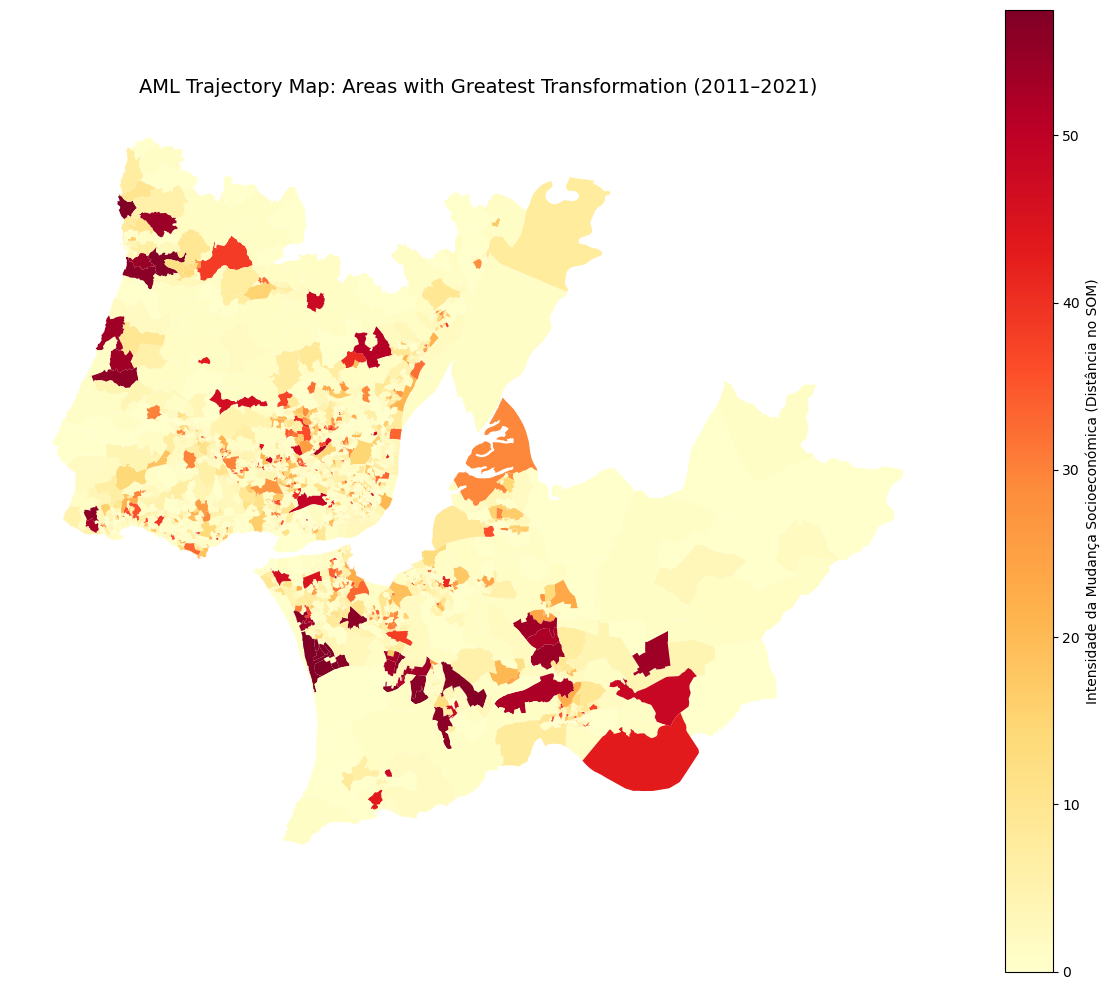

In [39]:
mapa_trajetorias = df_2021_seccoes.merge(df_trajetorias, on='DTMNFRSEC21')

fig, ax = plt.subplots(figsize=(12, 10))
mapa_trajetorias.plot(
    column='distancia_trajetoria',
    cmap='YlOrRd',
    legend=True,
    legend_kwds={'label': 'Intensidade da Mudança Socioeconómica (Distância no SOM)'},
    ax=ax
)
ax.set_title('AML Trajectory Map: Areas with Greatest Transformation (2011–2021)', fontsize=14)
ax.axis('off')
plt.tight_layout()
plt.show()

### 8.6 Top 10 Sections with Greatest Change — Trajectories on the SOM Grid



We highlight the 10 sections that moved the most on the SOM grid. Each arrow starts from the 2011 position and points to the 2021 position. The grey background points represent all 2021 sections, providing context for the grid's range. The section ID allows cross-referencing these results with specific geographic or administrative information.

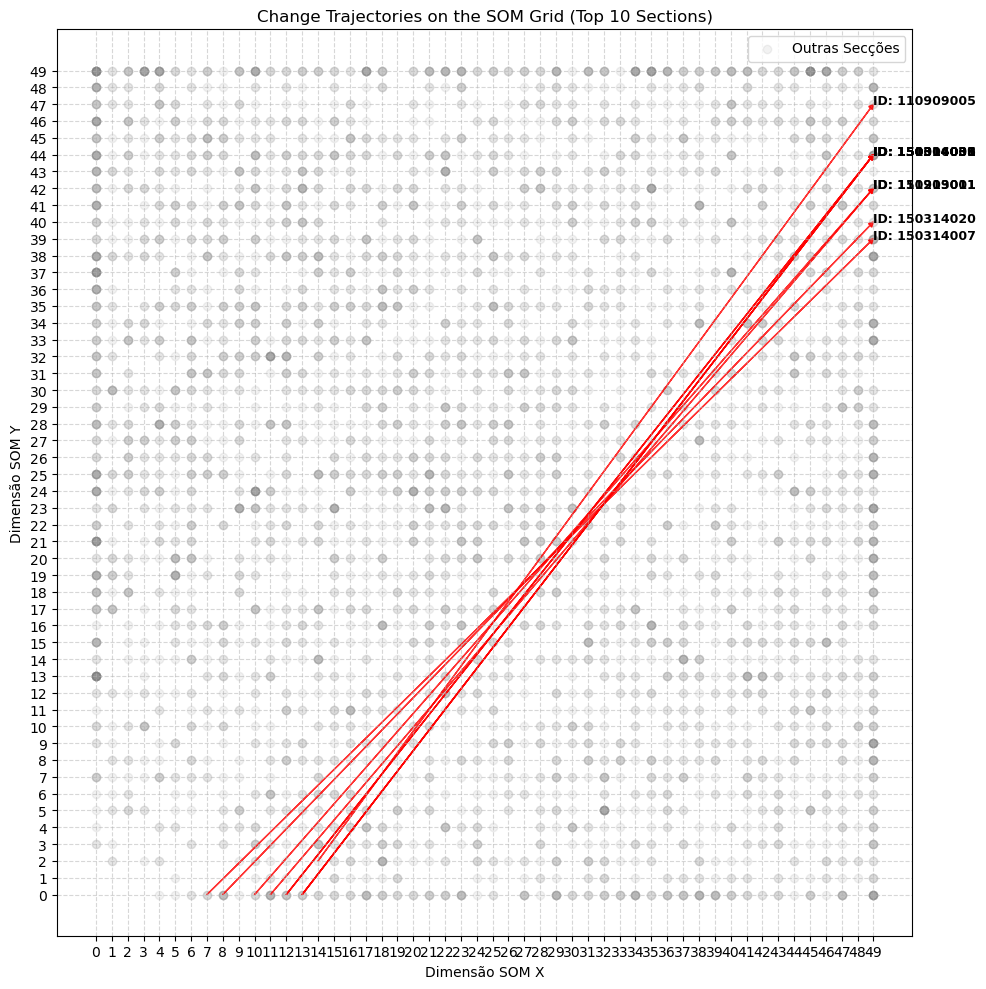

In [40]:
top_10_mudanca = df_trajetorias.nlargest(10, 'distancia_trajetoria')

plt.figure(figsize=(10, 10))
plt.title('Change Trajectories on the SOM Grid (Top 10 Sections)')
plt.scatter(pooled_data['som_x'], pooled_data['som_y'],
            alpha=0.1, color='gray', label='Outras Secções')

for _, row in top_10_mudanca.iterrows():
    x1, y1 = row['som_x_2011'], row['som_y_2011']
    x2, y2 = row['som_x_2021'], row['som_y_2021']
    plt.arrow(x1, y1, x2-x1, y2-y1,
              head_width=0.3, head_length=0.3,
              fc='red', ec='red', alpha=0.8, length_includes_head=True)
    plt.text(x2, y2, f"ID: {row['DTMNFRSEC21']}", fontsize=9, fontweight='bold')

plt.xticks(range(int(pooled_data['som_x'].max()) + 1))
plt.yticks(range(int(pooled_data['som_y'].max()) + 1))
plt.grid(True, linestyle='--', alpha=0.5)
plt.xlabel('Dimensão SOM X'); plt.ylabel('Dimensão SOM Y')
plt.legend()
plt.tight_layout()
plt.show()

### 8.7 Cluster Maps by Year



Direct comparison of the spatial distribution of clusters in 2011 and 2021 in the AML. Both maps use the same colour palette (`tab10`) for straightforward reading: a section that keeps the same colour between the two maps remained in the same cluster; a colour change indicates a socioeconomic transition.

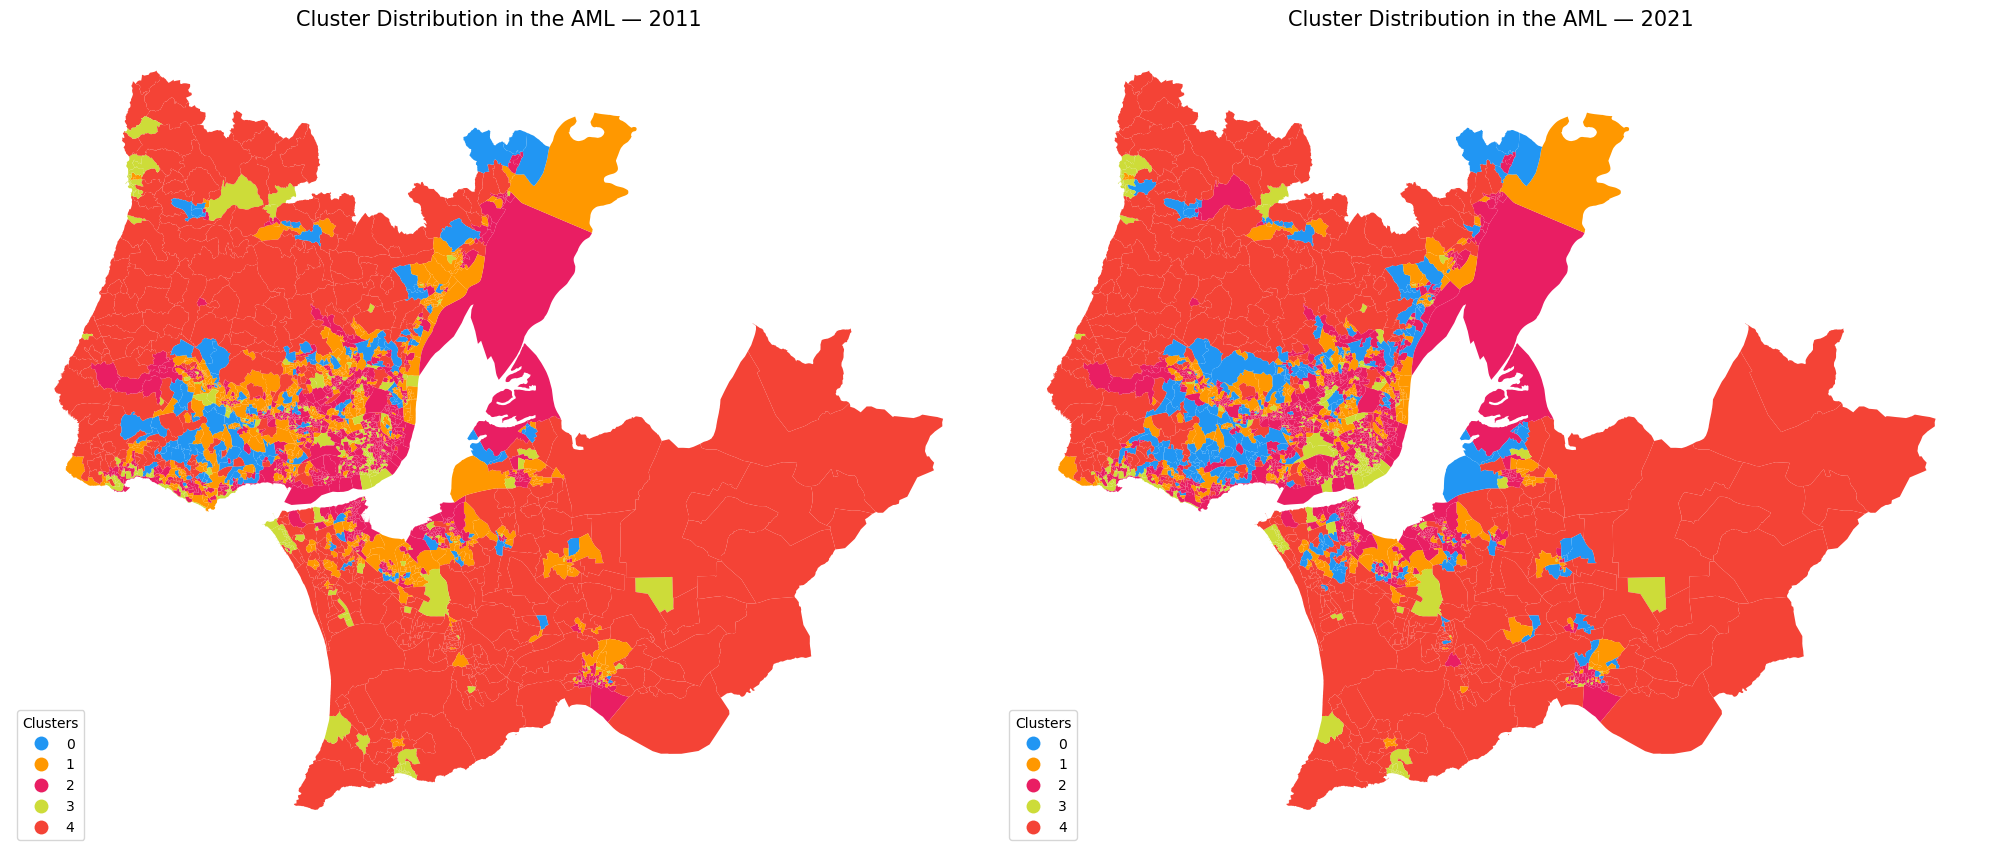

In [41]:
res_2011   = pooled_data[pooled_data['ANO'] == 2011][['DTMNFRSEC21','cluster']]
res_2021   = pooled_data[pooled_data['ANO'] == 2021][['DTMNFRSEC21','cluster']]
mapa_2011  = df_2021_seccoes.merge(res_2011, on='DTMNFRSEC21')
mapa_2021  = df_2021_seccoes.merge(res_2021, on='DTMNFRSEC21')

_CMAP_87 = ListedColormap([     '#2196F3',
    '#FF9800',
    '#4CAF50',
    '#E91E63',
    '#9C27B0',
    '#CDDC39', 
    '#F44336'
])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))

mapa_2011.plot(column='cluster', categorical=True, legend=True,
               cmap=_CMAP_87, ax=ax1,
               legend_kwds={'title': 'Clusters', 'loc': 'lower left'})
ax1.set_title('Cluster Distribution in the AML — 2011', fontsize=15)
ax1.axis('off')

mapa_2021.plot(column='cluster', categorical=True, legend=True,
               cmap=_CMAP_87, ax=ax2,
               legend_kwds={'title': 'Clusters', 'loc': 'lower left'})
ax2.set_title('Cluster Distribution in the AML — 2021', fontsize=15)
ax2.axis('off')

plt.tight_layout()
plt.show()

### 8.8 Average Variable Profile by Cluster



The profile heatmap allows substantive characterisation of each cluster. For each numeric variable we compute the mean by cluster and display the normalised values. Vertical patterns (columns very different between clusters) indicate discriminating variables; horizontal patterns (similar rows) indicate variables that are less informative for cluster distinction.

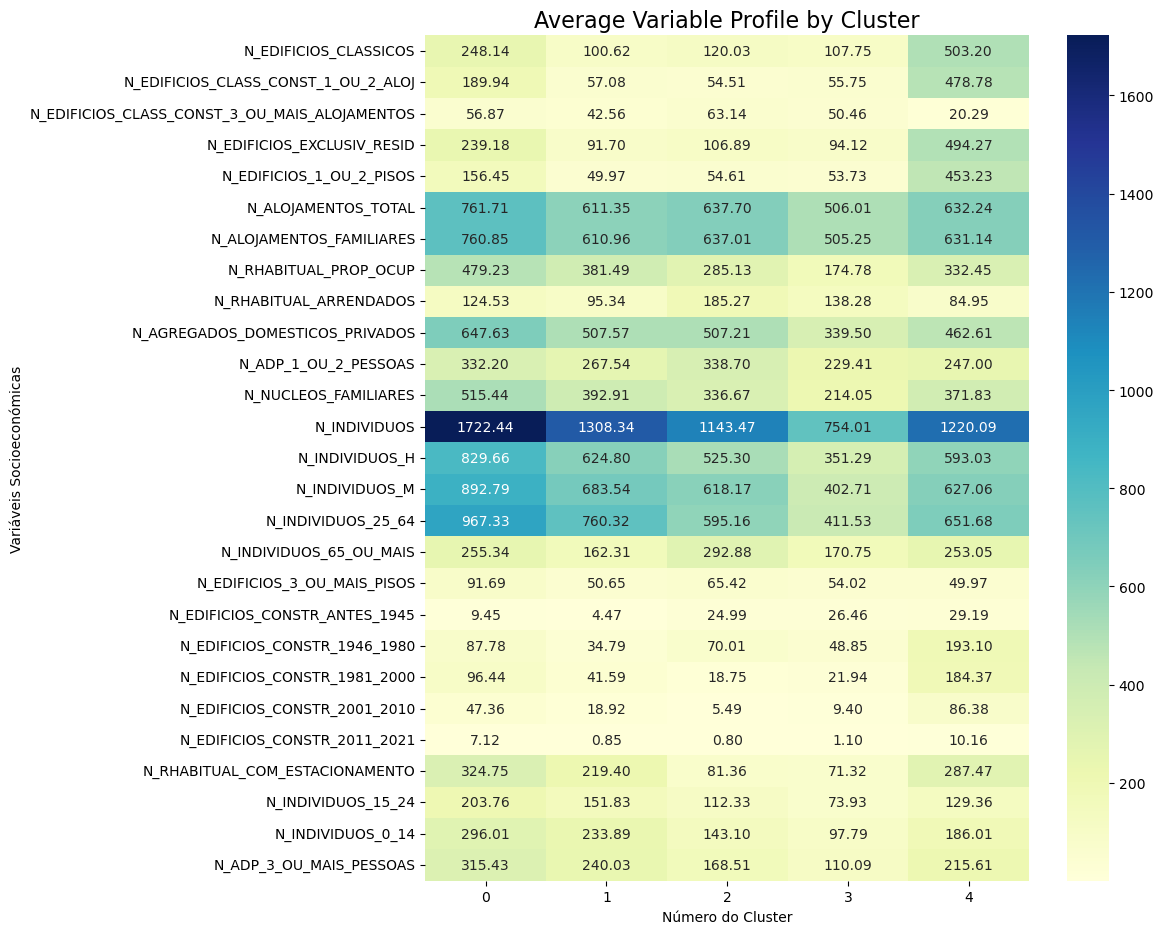

cluster                                                  0            1            2           3            4
N_EDIFICIOS_CLASSICOS                           248.140411   100.624392   120.032609  107.747863   503.195991
N_EDIFICIOS_CLASS_CONST_1_OU_2_ALOJ             189.943443    57.075672    54.507349   55.754485   478.779741
N_EDIFICIOS_CLASS_CONST_3_OU_MAIS_ALOJAMENTOS    56.873237    42.555880    63.138635   50.464502    20.286177
N_EDIFICIOS_EXCLUSIV_RESID                      239.184616    91.697329   106.886715   94.120119   494.265168
N_EDIFICIOS_1_OU_2_PISOS                        156.449817    49.974994    54.611780   53.730727   453.227847
N_ALOJAMENTOS_TOTAL                             761.710358   611.345661   637.699459  506.013047   632.242373
N_ALOJAMENTOS_FAMILIARES                        760.848052   610.959579   637.005153  505.246262   631.140787
N_RHABITUAL_PROP_OCUP                           479.233087   381.486722   285.134930  174.777872   332.449236
N_RHABITUA

In [42]:
perfil_clusters   = pooled_data.groupby('cluster')[numeric_cols.columns.tolist()].mean()
perfil_clusters_t = perfil_clusters.T

plt.figure(figsize=(12, max(6, len(perfil_clusters_t) * 0.35)))
sns.heatmap(perfil_clusters_t, annot=True, fmt='.2f', cmap='YlGnBu')
plt.title('Average Variable Profile by Cluster', fontsize=16)
plt.ylabel('Variáveis Socioeconómicas')
plt.xlabel('Número do Cluster')
plt.tight_layout()
plt.show()

print(perfil_clusters_t.to_string())

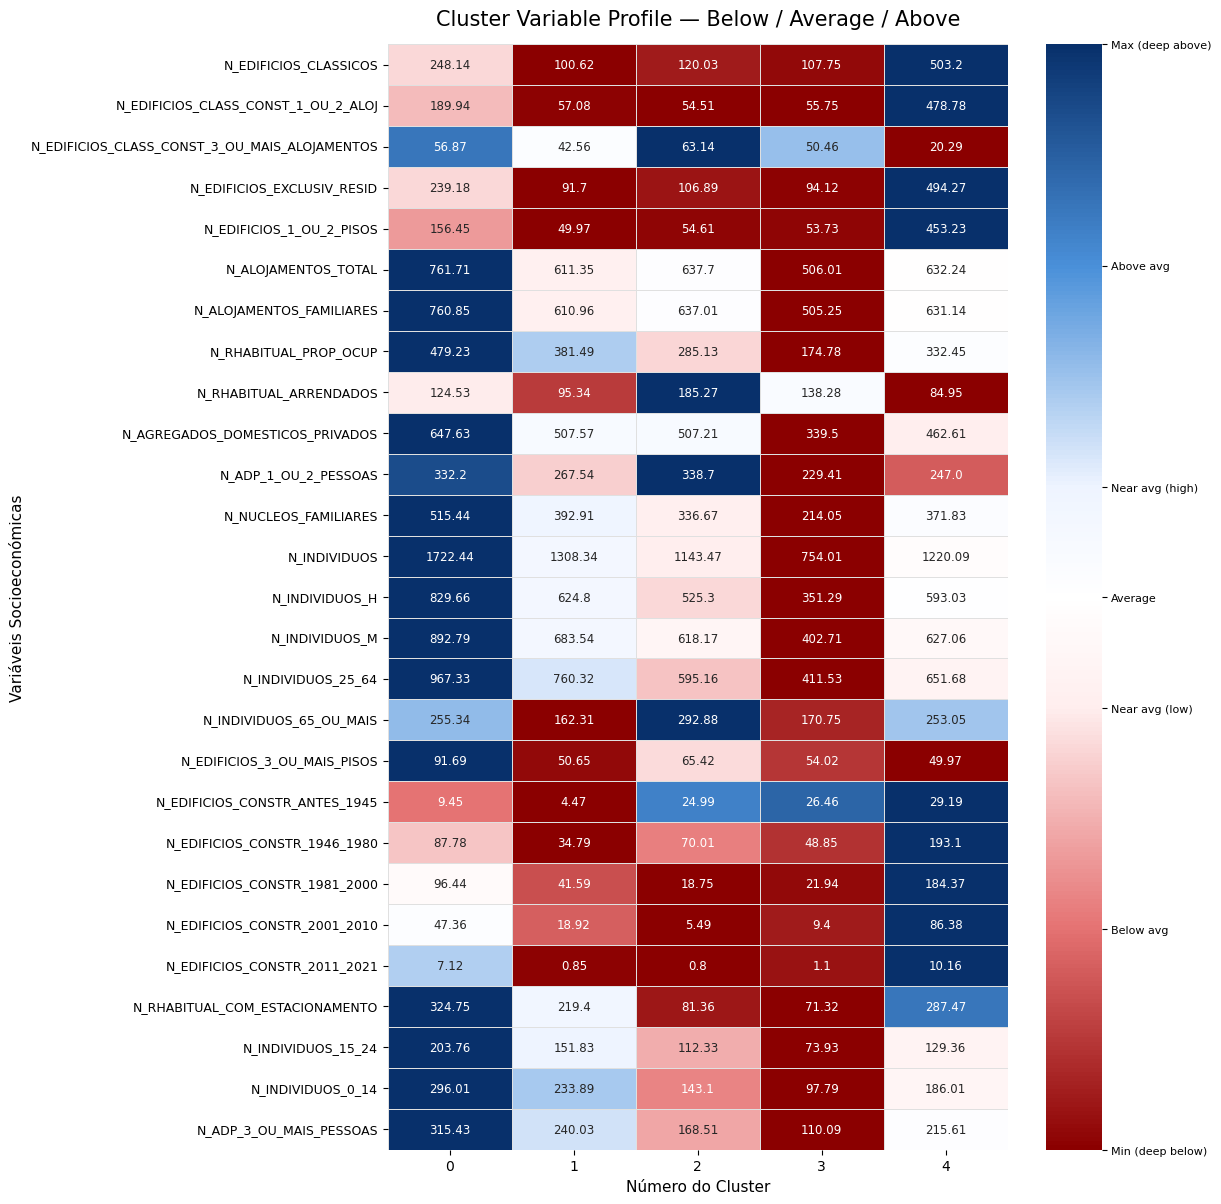

cluster                                                  0            1            2           3            4
N_EDIFICIOS_CLASSICOS                           248.140411   100.624392   120.032609  107.747863   503.195991
N_EDIFICIOS_CLASS_CONST_1_OU_2_ALOJ             189.943443    57.075672    54.507349   55.754485   478.779741
N_EDIFICIOS_CLASS_CONST_3_OU_MAIS_ALOJAMENTOS    56.873237    42.555880    63.138635   50.464502    20.286177
N_EDIFICIOS_EXCLUSIV_RESID                      239.184616    91.697329   106.886715   94.120119   494.265168
N_EDIFICIOS_1_OU_2_PISOS                        156.449817    49.974994    54.611780   53.730727   453.227847
N_ALOJAMENTOS_TOTAL                             761.710358   611.345661   637.699459  506.013047   632.242373
N_ALOJAMENTOS_FAMILIARES                        760.848052   610.959579   637.005153  505.246262   631.140787
N_RHABITUAL_PROP_OCUP                           479.233087   381.486722   285.134930  174.777872   332.449236
N_RHABITUA

In [43]:
# Compute cluster profiles
perfil_clusters   = pooled_data.groupby('cluster')[numeric_cols.columns.tolist()].mean()
perfil_clusters_t = perfil_clusters.T

# --- Percentile-rank normalization (row-wise, i.e. per variable) ---
# For each variable (row), compute where each cluster stands
# relative to the range across all clusters (0=min, 1=max)
perfil_norm = perfil_clusters_t.copy().astype(float)

for idx in perfil_norm.index:
    row     = perfil_norm.loc[idx]
    row_min = row.min()
    row_max = row.max()
    if row_max > row_min:
        perfil_norm.loc[idx] = (row - row_min) / (row_max - row_min)
    else:
        perfil_norm.loc[idx] = 0.5   # flat row → neutral

# --- Custom diverging colormap ---
# Below average  (0.00–0.40) : red gradient   (light → deep red)
# Average        (0.41–0.60) : white / neutral
# Above average  (0.61–1.00) : blue gradient  (light → deep blue)
colors = [
    (0.00, "#8B0000"),   # deep red
    (0.20, "#E57373"),   # medium red
    (0.40, "#FFEEEE"),   # very light red (just below average)
    (0.50, "#FFFFFF"),   # white (average)
    (0.60, "#EEF4FF"),   # very light blue (just above average)
    (0.80, "#4A90D9"),   # medium blue
    (1.00, "#08306B"),   # deep blue
]
cmap = mcolors.LinearSegmentedColormap.from_list(
    "below_avg_above", [(v, c) for v, c in colors]
)

# --- Plot ---
fig, ax = plt.subplots(figsize=(12, max(6, len(perfil_clusters_t) * 0.45)))

sns.heatmap(
    perfil_norm,
    annot=perfil_clusters_t.round(2),   # show original values
    fmt='',
    cmap=cmap,
    vmin=0, vmax=1,
    linewidths=0.4,
    linecolor='#e0e0e0',
    ax=ax,
    annot_kws={"size": 8.5},
)

# --- Colorbar labels ---
cbar = ax.collections[0].colorbar
cbar.set_ticks([0.0, 0.20, 0.40, 0.50, 0.60, 0.80, 1.0])
cbar.set_ticklabels([
    'Min (deep below)',
    'Below avg',
    'Near avg (low)',
    'Average',
    'Near avg (high)',
    'Above avg',
    'Max (deep above)',
])
cbar.ax.tick_params(labelsize=8)

# --- Titles & labels ---
ax.set_title('Cluster Variable Profile — Below / Average / Above', fontsize=15, pad=14)
ax.set_ylabel('Variáveis Socioeconómicas', fontsize=11)
ax.set_xlabel('Número do Cluster', fontsize=11)
ax.tick_params(axis='y', labelsize=9)

plt.tight_layout()
plt.show()

print(perfil_clusters_t.to_string())

### 8.9 Trajectory Vectors by Section on the SOM

Each arrow represents a statistical section: it starts at its BMU position in 2011 and points to its position in 2021. Arrows are coloured by the origin cluster (2011). A slight jitter prevents total overlap when multiple sections share the same neuron. For visual clarity, only a fraction (`sample_frac`) of sections is shown — the full population would make the chart illegible.

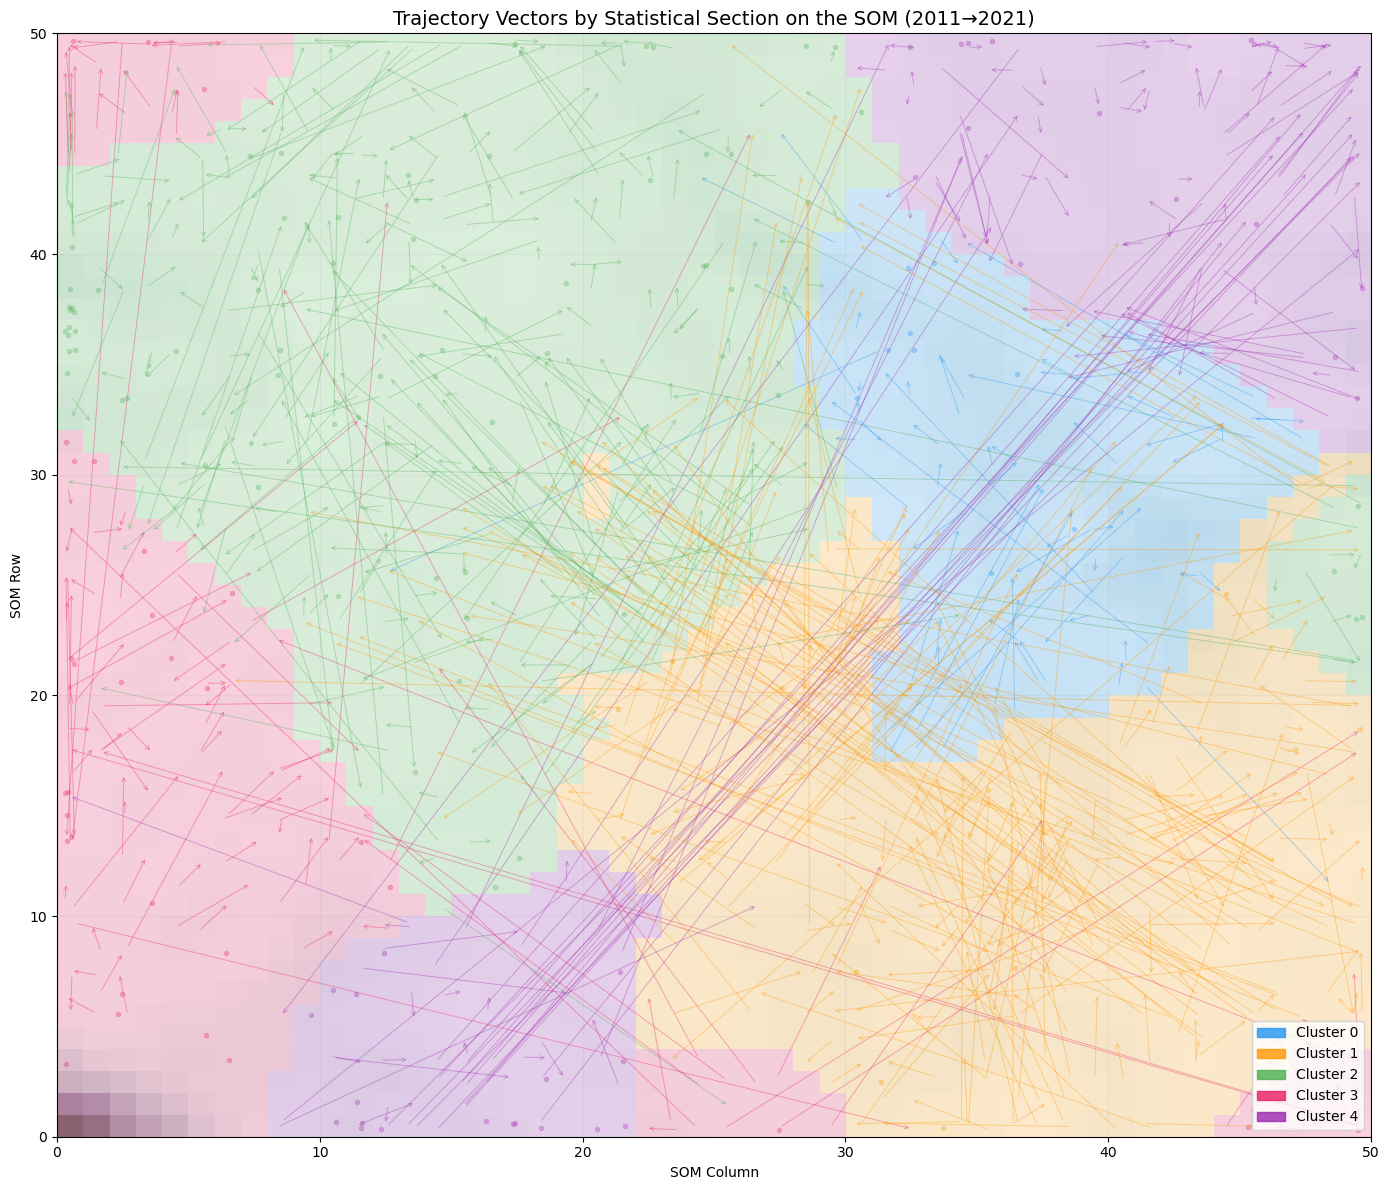

In [44]:
_COLORS_VIZ = [     '#2196F3',
    '#FF9800',
    '#4CAF50',
    '#E91E63',
    '#9C27B0',
    '#CDDC39', 
    '#F44336'
]


def plot_trajectory_vectors_som(som, pooled_data, scaled_pooled, feature_cols,
                                node_labels, grid_x, grid_y,
                                sample_frac=0.4, seed=RANDOM_SEED,
                                title='Trajectory Vectors by Statistical Section on the SOM (2011→2021)'):
    idx_y1 = pooled_data[pooled_data['ANO'] == 2011][['DTMNFRSEC21']].reset_index(drop=True)
    idx_y1['row_y1'] = np.arange(len(idx_y1))
    idx_y2 = pooled_data[pooled_data['ANO'] == 2021][['DTMNFRSEC21']].reset_index(drop=True)
    idx_y2['row_y2'] = np.arange(len(idx_y2))
    matched = idx_y1.merge(idx_y2, on='DTMNFRSEC21').sample(frac=sample_frac, random_state=seed)

    data_y1 = scaled_pooled.loc[pooled_data['ANO'] == 2011, feature_cols].reset_index(drop=True).values
    data_y2 = scaled_pooled.loc[pooled_data['ANO'] == 2021, feature_cols].reset_index(drop=True).values

    wt = som.get_weights()
    umatrix = np.zeros((grid_x, grid_y))
    for i in range(grid_x):
        for j in range(grid_y):
            nbrs = [np.linalg.norm(wt[i, j] - wt[i+di, j+dj])
                    for di, dj in [(-1, 0), (1, 0), (0, -1), (0, 1)]
                    if 0 <= i+di < grid_x and 0 <= j+dj < grid_y]
            umatrix[i, j] = np.mean(nbrs)

    cluster_map = node_labels.reshape(grid_x, grid_y)
    cmap_c = ListedColormap(_COLORS_VIZ[:OPTIMAL_K])

    fig, ax = plt.subplots(figsize=(14, 12))
    ax.imshow(umatrix.T, cmap='bone_r', alpha=0.55, origin='lower',
              extent=[0, grid_x, 0, grid_y], aspect='auto')
    ax.imshow(cluster_map.T, cmap=cmap_c, alpha=0.20, origin='lower',
              extent=[0, grid_x, 0, grid_y], aspect='auto')

    np.random.seed(seed)
    for _, row in matched.iterrows():
        v1 = data_y1[int(row['row_y1'])]
        v2 = data_y2[int(row['row_y2'])]
        b1 = som.winner(v1)
        b2 = som.winner(v2)
        c  = _COLORS_VIZ[cluster_map[b1[0], b1[1]]]
        jx1 = b1[0] + 0.5 + np.random.uniform(-0.2, 0.2)
        jy1 = b1[1] + 0.5 + np.random.uniform(-0.2, 0.2)
        jx2 = b2[0] + 0.5 + np.random.uniform(-0.2, 0.2)
        jy2 = b2[1] + 0.5 + np.random.uniform(-0.2, 0.2)
        if b1 == b2:
            ax.plot(jx1, jy1, 'o', color=c, alpha=0.25, markersize=3)
        else:
            ax.annotate('', xy=(jx2, jy2), xytext=(jx1, jy1),
                        arrowprops=dict(arrowstyle='->', color=c, alpha=0.35,
                                        lw=0.7, mutation_scale=7))

    patches = [mpatches.Patch(color=_COLORS_VIZ[i], label=f'Cluster {i}', alpha=0.8)
               for i in range(OPTIMAL_K)]
    ax.legend(handles=patches, loc='lower right', fontsize=10)
    ax.set_xlim(0, grid_x); ax.set_ylim(0, grid_y)
    ax.set_xlabel('SOM Column'); ax.set_ylabel('SOM Row')
    ax.set_title(title, fontsize=14)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()


plot_trajectory_vectors_som(
    best_som, pooled_data, scaled_pooled, feature_cols,
    node_labels, int(best_params['grid_x']), int(best_params['grid_y']),
    sample_frac=0.4
)

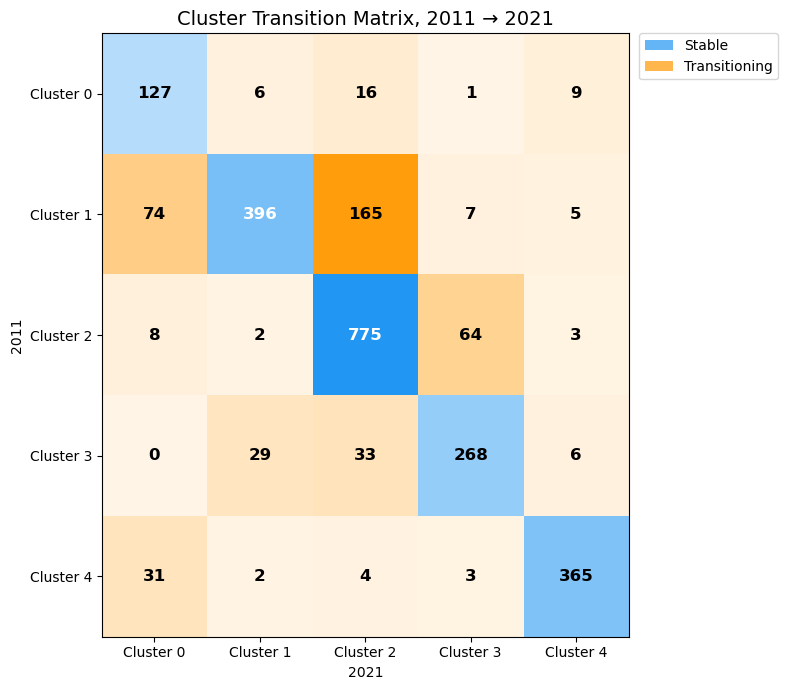

Sections stable across the decade: 80.5%


In [45]:
trans_matrix = trans.values
k = trans_matrix.shape[0]

diag_vals    = np.diag(trans_matrix)
offdiag_mask = ~np.eye(k, dtype=bool)
offdiag_vals = trans_matrix[offdiag_mask]

diag_max    = diag_vals.max() if diag_vals.max() > 0 else 1
offdiag_max = offdiag_vals.max() if offdiag_vals.max() > 0 else 1

color_matrix = np.zeros((k, k, 4))
for i in range(k):
    for j in range(k):
        val = trans_matrix[i, j]
        if i == j:
            alpha = 0.20 + 0.80 * (val / diag_max)
            color_matrix[i, j] = mcolors.to_rgba('#2196F3', alpha=alpha)
        else:
            alpha = 0.10 + 0.85 * (val / offdiag_max) if offdiag_max > 0 else 0.10
            color_matrix[i, j] = mcolors.to_rgba('#FF9800', alpha=alpha)

fig, ax = plt.subplots(figsize=(8, 7))
ax.imshow(color_matrix, aspect='auto')

for i in range(k):
    for j in range(k):
        text_color = 'white' if (i == j and trans_matrix[i, j] / diag_max > 0.5) else 'black'
        ax.text(j, i, str(int(trans_matrix[i, j])),
                ha='center', va='center', fontsize=12,
                fontweight='bold', color=text_color)

ax.set_xticks(range(k))
ax.set_yticks(range(k))
ax.set_xticklabels([f'Cluster {j}' for j in range(k)])
ax.set_yticklabels([f'Cluster {i}' for i in range(k)])
ax.set_xlabel('2021')
ax.set_ylabel('2011')
ax.set_title('Cluster Transition Matrix, 2011 → 2021', fontsize=14)

legend_elements = [
    mpatches.Patch(facecolor='#2196F3', alpha=0.7, label='Stable'),
    mpatches.Patch(facecolor='#FF9800', alpha=0.7, label='Transitioning'),
]
ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), borderaxespad=0)

plt.tight_layout()
plt.show()

pct_stable = np.trace(trans_matrix) / trans_matrix.sum() * 100
print(f"Sections stable across the decade: {pct_stable:.1f}%")

### 8.10 Convergence and Divergence Pattern

Two complementary panels:

- **Left — Net Flow:** each cell shows `arrivals − departures` between 2011 and 2021. Blue = convergence (more sections arrived than left); red = divergence (more sections left than arrived).
- **Right — Velocity Field:** quiver arrows show the average displacement of sections that left each cell. The orange background encodes the intensity (magnitude) of that average displacement.

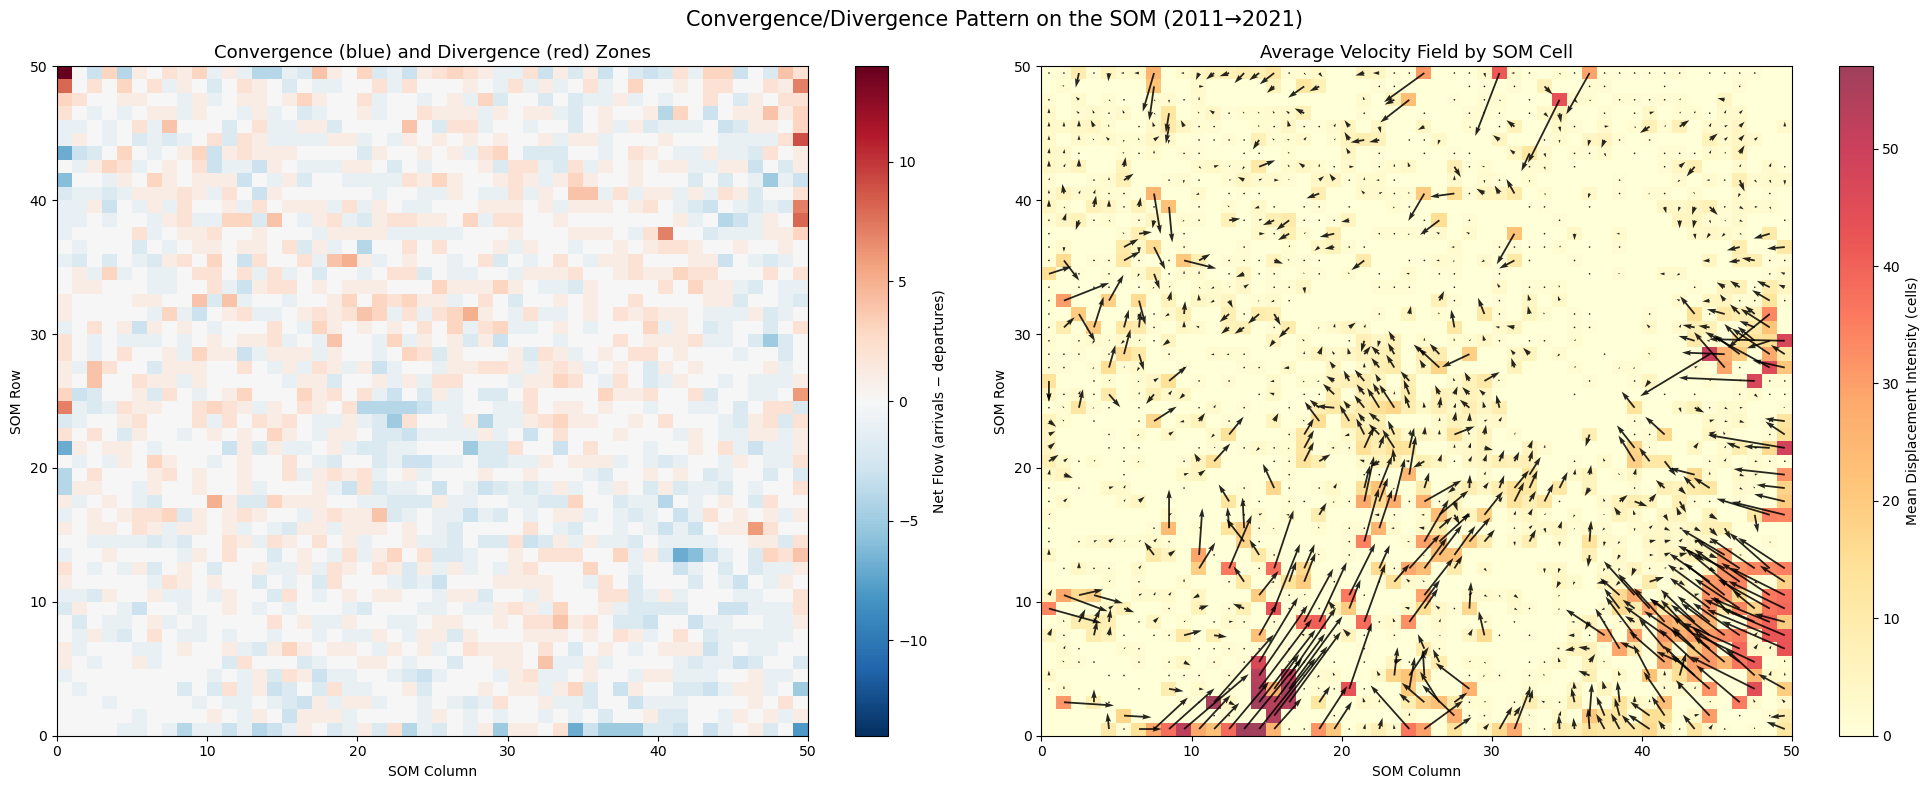

In [46]:
def plot_convergence_divergence(som, pooled_data, scaled_pooled, feature_cols,
                                grid_x, grid_y,
                                title='Convergence/Divergence Pattern on the SOM (2011→2021)'):
    idx_y1 = pooled_data[pooled_data['ANO'] == 2011][['DTMNFRSEC21']].reset_index(drop=True)
    idx_y1['row_y1'] = np.arange(len(idx_y1))
    idx_y2 = pooled_data[pooled_data['ANO'] == 2021][['DTMNFRSEC21']].reset_index(drop=True)
    idx_y2['row_y2'] = np.arange(len(idx_y2))
    matched = idx_y1.merge(idx_y2, on='DTMNFRSEC21')

    data_y1 = scaled_pooled.loc[pooled_data['ANO'] == 2011, feature_cols].reset_index(drop=True).values
    data_y2 = scaled_pooled.loc[pooled_data['ANO'] == 2021, feature_cols].reset_index(drop=True).values

    net_flow = np.zeros((grid_x, grid_y))
    dx_acc   = np.zeros((grid_x, grid_y))
    dy_acc   = np.zeros((grid_x, grid_y))
    count    = np.zeros((grid_x, grid_y))

    for _, row in matched.iterrows():
        b1 = som.winner(data_y1[int(row['row_y1'])])
        b2 = som.winner(data_y2[int(row['row_y2'])])
        net_flow[b2[0], b2[1]] += 1
        net_flow[b1[0], b1[1]] -= 1
        dx_acc[b1[0], b1[1]]   += b2[0] - b1[0]
        dy_acc[b1[0], b1[1]]   += b2[1] - b1[1]
        count[b1[0], b1[1]]    += 1

    with np.errstate(invalid='ignore'):
        avg_dx = np.where(count > 0, dx_acc / count, 0.0)
        avg_dy = np.where(count > 0, dy_acc / count, 0.0)
    speed = np.sqrt(avg_dx**2 + avg_dy**2)

    fig, axes = plt.subplots(1, 2, figsize=(20, 8))

    ax = axes[0]
    vmax = max(np.abs(net_flow).max(), 1)
    im = ax.imshow(net_flow.T, cmap='RdBu_r', origin='lower',
                   extent=[0, grid_x, 0, grid_y], aspect='auto',
                   vmin=-vmax, vmax=vmax)
    plt.colorbar(im, ax=ax, label='Net Flow (arrivals − departures)')
    ax.set_title('Convergence (blue) and Divergence (red) Zones', fontsize=13)
    ax.set_xlabel('SOM Column'); ax.set_ylabel('SOM Row')

    ax = axes[1]
    im2 = ax.imshow(speed.T, cmap='YlOrRd', origin='lower',
                    extent=[0, grid_x, 0, grid_y], aspect='auto', alpha=0.75)
    plt.colorbar(im2, ax=ax, label='Mean Displacement Intensity (cells)')
    mask_q = count > 0
    X, Y = np.meshgrid(np.arange(grid_x) + 0.5, np.arange(grid_y) + 0.5, indexing='ij')
    ax.quiver(X[mask_q], Y[mask_q], avg_dx[mask_q], avg_dy[mask_q], alpha=0.85, color='black')
    ax.set_xlim(0, grid_x); ax.set_ylim(0, grid_y)
    ax.set_title('Average Velocity Field by SOM Cell', fontsize=13)
    ax.set_xlabel('SOM Column'); ax.set_ylabel('SOM Row')

    plt.suptitle(title, fontsize=15)
    plt.tight_layout()
    plt.show()


plot_convergence_divergence(
    best_som, pooled_data, scaled_pooled, feature_cols,
    int(best_params['grid_x']), int(best_params['grid_y'])
)

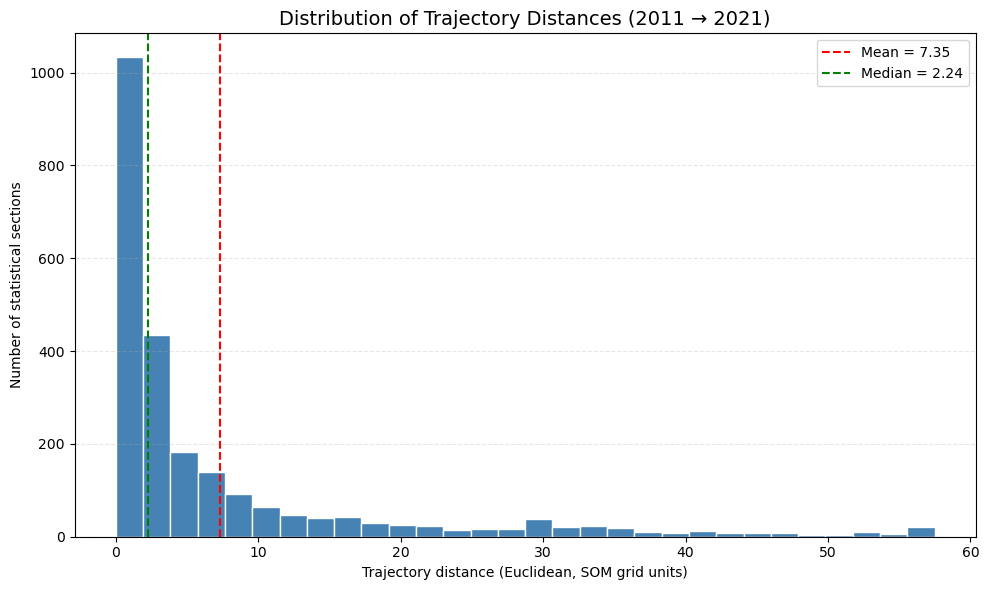

Mean: 7.354 | Median: 2.236 | Max: 57.489
Sections with zero displacement: 15.7%


In [47]:
fig, ax = plt.subplots(figsize=(10, 6))

dist = df_trajetorias['distancia_trajetoria']

ax.hist(dist, bins=30, color='steelblue', edgecolor='white')

mean_d   = dist.mean()
median_d = dist.median()
max_d    = dist.max()

ax.axvline(mean_d, color='red', linestyle='--', linewidth=1.5,
           label=f'Mean = {mean_d:.2f}')
ax.axvline(median_d, color='green', linestyle='--', linewidth=1.5,
           label=f'Median = {median_d:.2f}')

ax.set_title('Distribution of Trajectory Distances (2011 → 2021)', fontsize=14)
ax.set_xlabel('Trajectory distance (Euclidean, SOM grid units)')
ax.set_ylabel('Number of statistical sections')
ax.legend()
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

pct_zero = (dist == 0).mean() * 100
print(f"Mean: {mean_d:.3f} | Median: {median_d:.3f} | Max: {max_d:.3f}")
print(f"Sections with zero displacement: {pct_zero:.1f}%")

### 8.11 Parallel Coordinate Plot by Cluster

Each line represents a statistical section (sample of 300 per cluster to avoid overlap); thicker lines show the cluster mean. The vertical axes are the `n_vars` variables with the highest between-cluster variance, normalised 0–1. Crossing patterns between clusters identify variables where clusters reverse their ordering — typically the most discriminating ones.

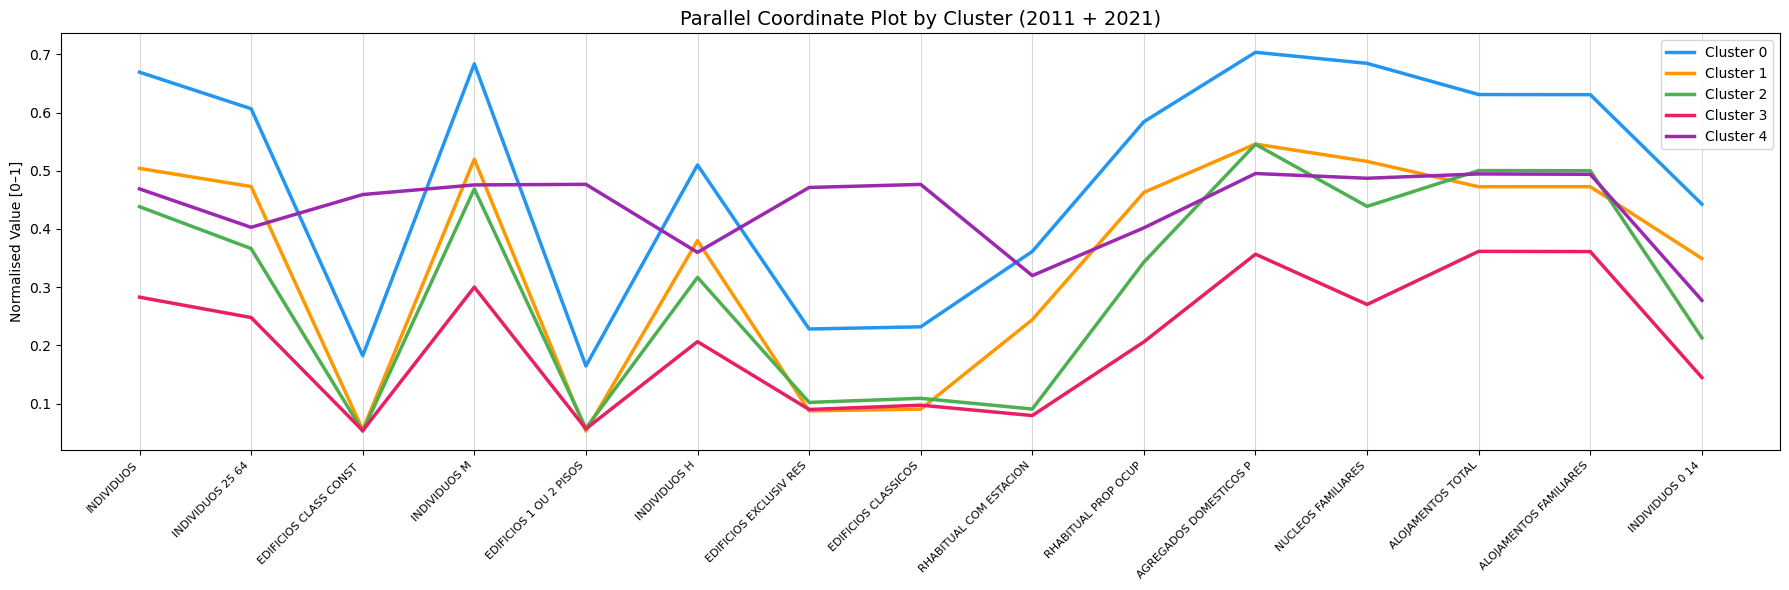

In [48]:
def plot_parallel_coordinates(pooled_data, numeric_cols_df, n_vars=15,
                              title='Parallel Coordinate Plot by Cluster (2011 + 2021)'):
    _C = [     '#2196F3',
    '#FF9800',
    '#4CAF50',
    '#E91E63',
    '#9C27B0',
    '#CDDC39', 
    '#F44336'
]
    cluster_means = pooled_data.groupby('cluster')[numeric_cols_df.columns.tolist()].mean()
    top_vars = cluster_means.var().nlargest(n_vars).index.tolist()

    plot_df = pooled_data[top_vars + ['cluster']].copy()
    for col in top_vars:
        mn, mx = plot_df[col].min(), plot_df[col].max()
        if mx > mn:
            plot_df[col] = (plot_df[col] - mn) / (mx - mn)

    fig, ax = plt.subplots(figsize=(18, 6))
    x_pos = np.arange(len(top_vars))

    for cluster_id in sorted(pooled_data['cluster'].unique()):
        color = _C[int(cluster_id)]
        subset = plot_df[plot_df['cluster'] == cluster_id]
        ax.plot(x_pos, subset[top_vars].mean().values, color=color,
                linewidth=2.5, label=f'Cluster {cluster_id}', zorder=5)

    ax.set_xticks(x_pos)
    labels = [v.replace('N_', '').replace('_', ' ')[:22] for v in top_vars]
    ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
    for xv in x_pos:
        ax.axvline(xv, color='gray', alpha=0.2, linewidth=0.5)
    ax.set_ylabel('Normalised Value [0–1]')
    ax.set_title(title, fontsize=14)
    ax.legend(loc='upper right', fontsize=10)
    ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()


plot_parallel_coordinates(pooled_data, numeric_cols, n_vars=15)

### 8.12 Boxplots by Cluster

For each of the `n_vars` most discriminating variables, a boxplot shows the within-cluster distribution. Extreme outliers are omitted (`showfliers=False`) to avoid compressing the IQR. Differences in median and IQR across clusters confirm the separation and allow substantive cluster naming (e.g. 'old-buildings cluster', 'recent-growth cluster').

C:\Users\Botelho\AppData\Local\Temp\ipykernel_22076\570965626.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pooled_data, x='cluster', y=var,
C:\Users\Botelho\AppData\Local\Temp\ipykernel_22076\570965626.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pooled_data, x='cluster', y=var,
C:\Users\Botelho\AppData\Local\Temp\ipykernel_22076\570965626.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pooled_data, x='cluster', y=var,
C:\Users\Botelho\AppData\Local\Temp\ipykernel_22076\570965626.py:22: FutureWarning: 

Pa

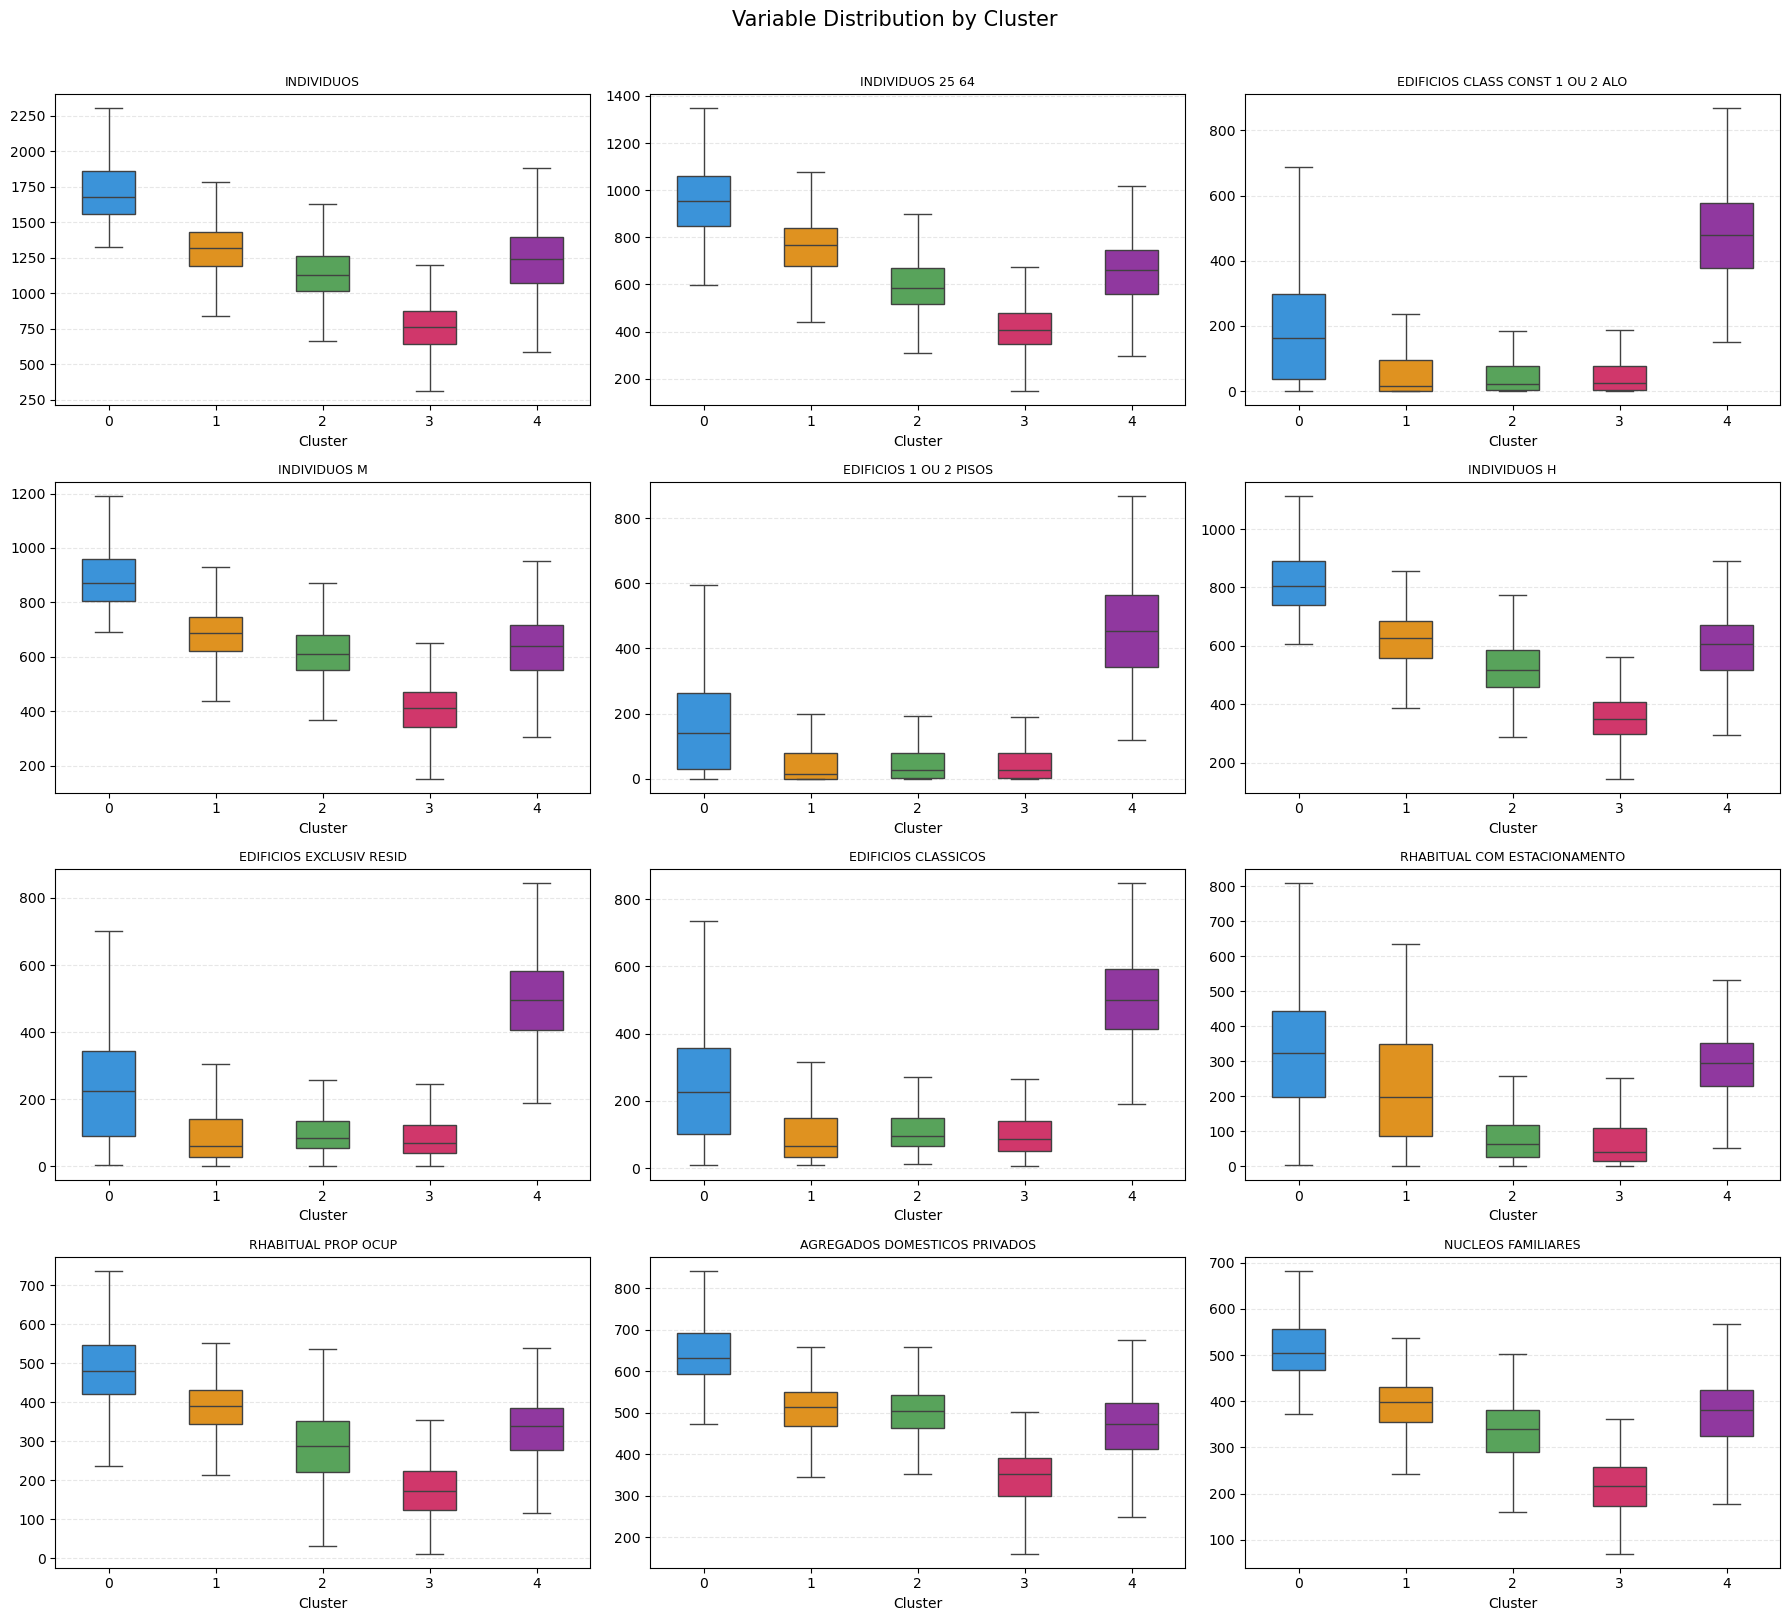

In [49]:
def plot_boxplots_per_cluster(pooled_data, numeric_cols_df, n_vars=12,
                              title='Variable Distribution by Cluster'):
    _C = [     '#2196F3',
    '#FF9800',
    '#4CAF50',
    '#E91E63',
    '#9C27B0',
    '#CDDC39', 
    '#F44336'
]
    cluster_means = pooled_data.groupby('cluster')[numeric_cols_df.columns.tolist()].mean()
    top_vars = cluster_means.var().nlargest(n_vars).index.tolist()
    palette  = {str(i): _C[i] for i in range(OPTIMAL_K)}

    n_cols = 3
    n_rows = (n_vars + n_cols - 1) // n_cols
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 4))
    axes = axes.flatten()

    for idx, var in enumerate(top_vars):
        ax = axes[idx]
        sns.boxplot(data=pooled_data, x='cluster', y=var,
                    palette=palette, ax=ax, showfliers=False, width=0.5)
        ax.set_title(var.replace('N_', '').replace('_', ' ')[:32], fontsize=9)
        ax.set_xlabel('Cluster'); ax.set_ylabel('')
        ax.grid(axis='y', alpha=0.3, linestyle='--')

    for idx in range(n_vars, len(axes)):
        axes[idx].set_visible(False)

    fig.suptitle(title, fontsize=15, y=1.01)
    plt.tight_layout()
    plt.show()


plot_boxplots_per_cluster(pooled_data, numeric_cols, n_vars=12)

### 8.13 Component Planes

One panel per variable: each SOM grid cell is coloured by the **learned weight** for that variable. Blue (negative) and red (positive) regions indicate areas where the SOM learned low or high values of that feature. Comparing the component planes with the U-Matrix and cluster maps reveals which variables 'explain' each region of the grid and, by extension, each cluster.

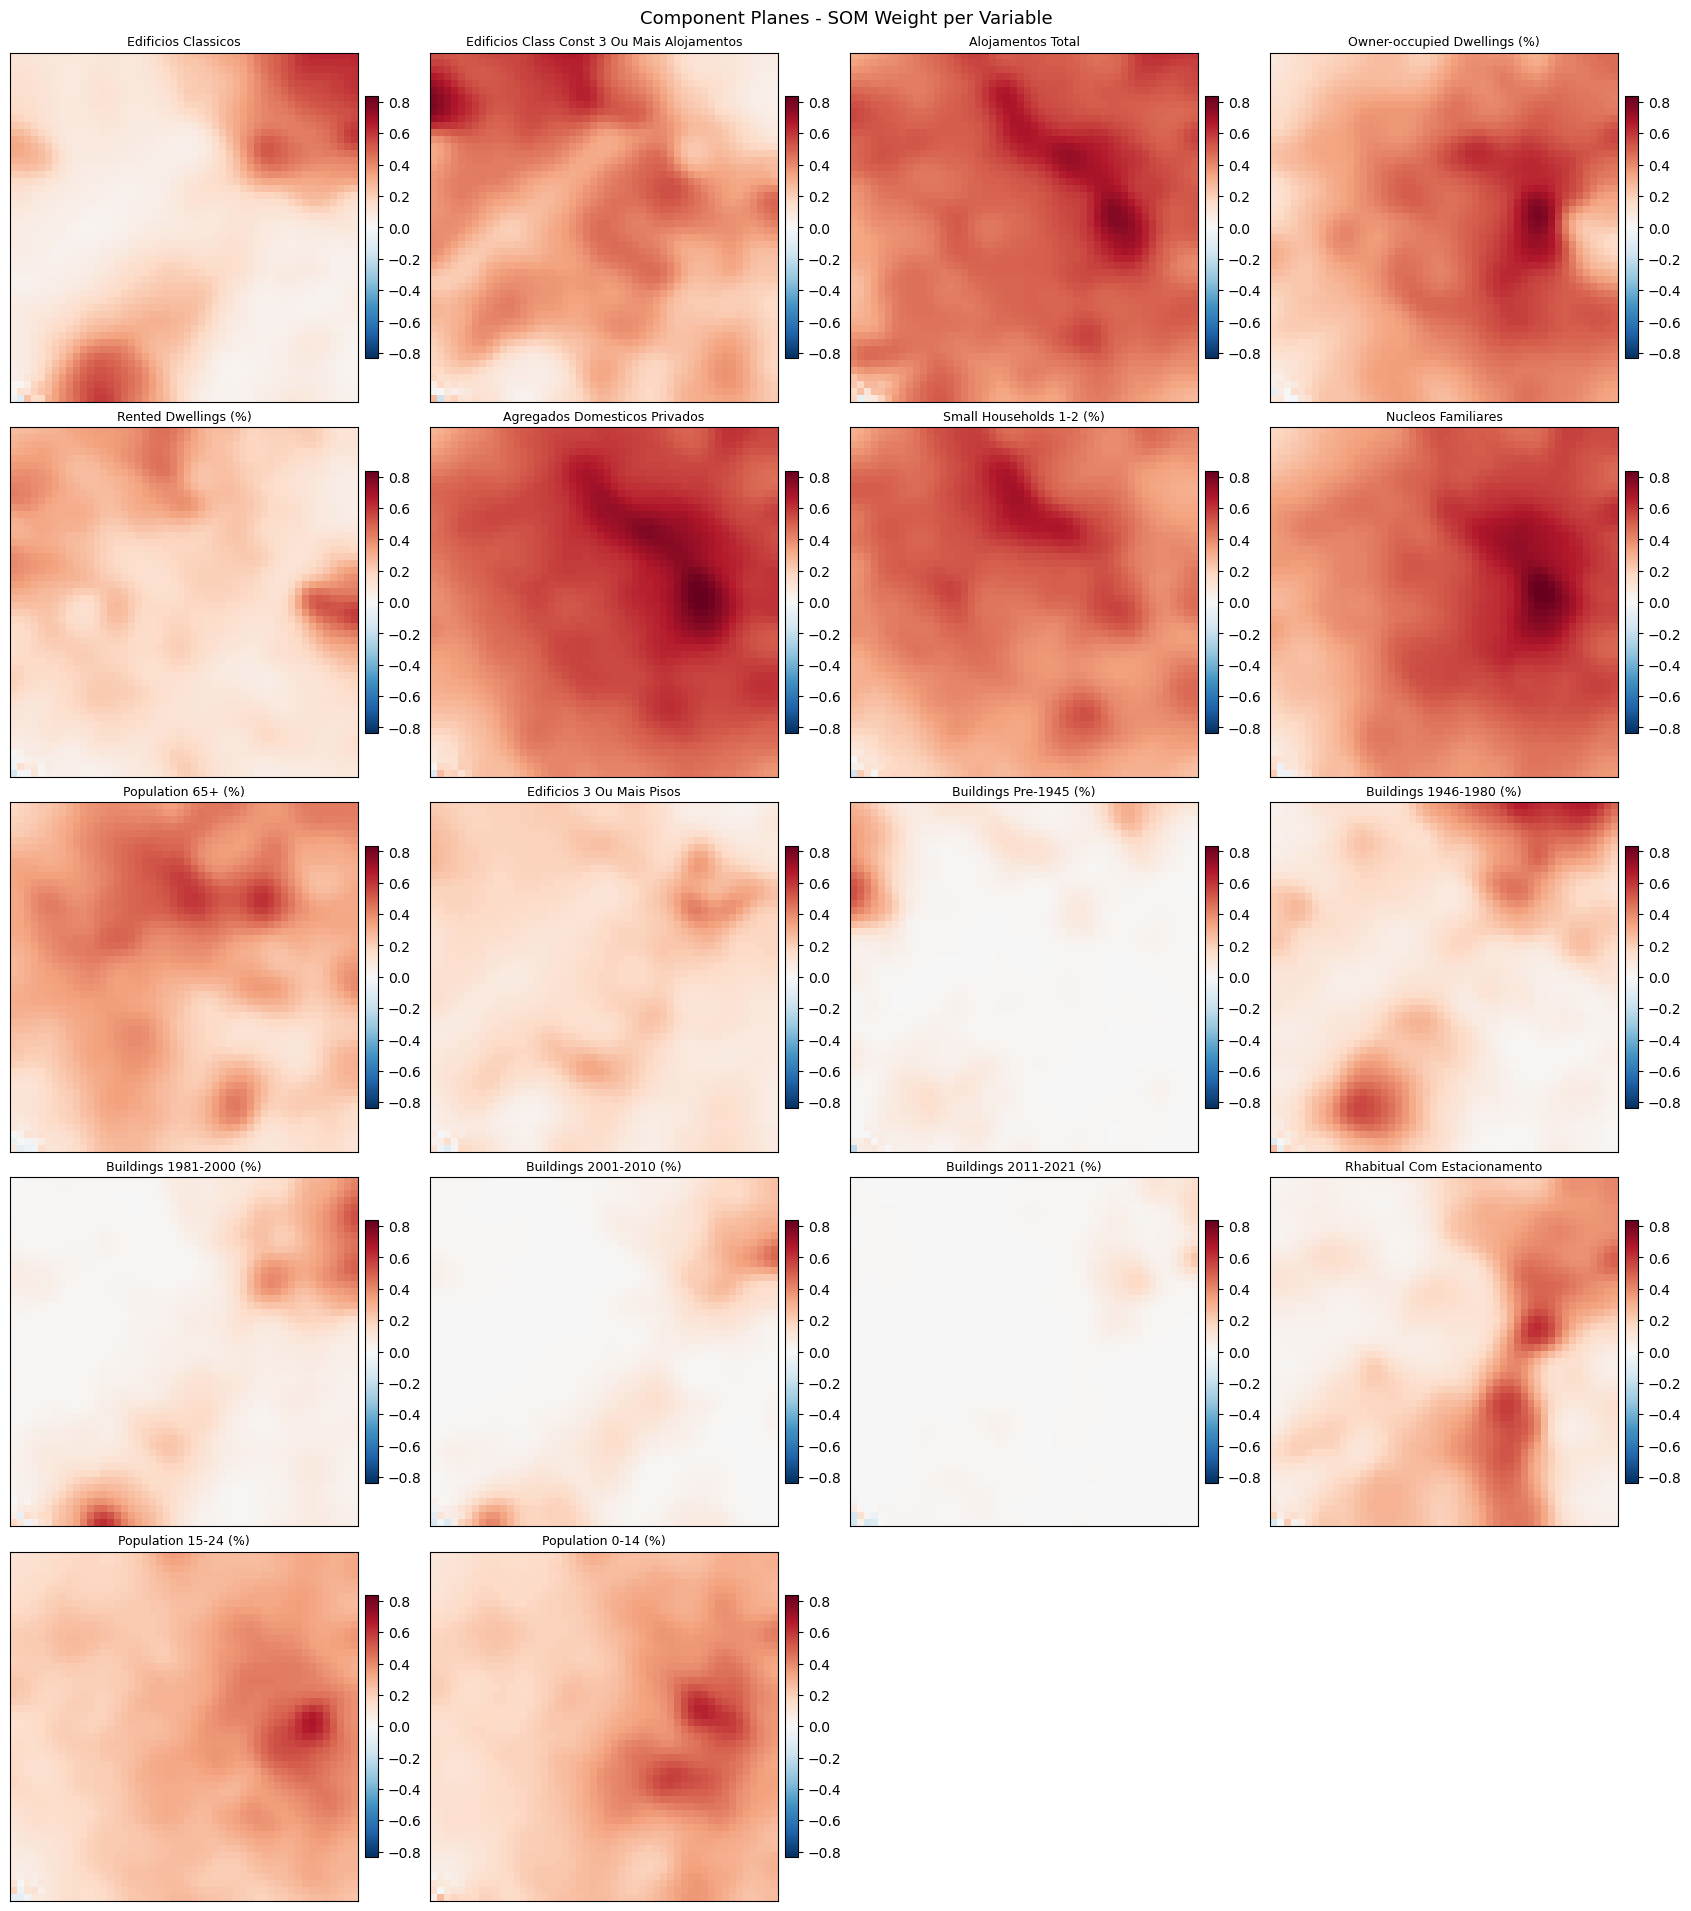

In [66]:
def plot_component_planes(som, feature_cols, grid_x, grid_y, n_cols=4,
                            title='Component Planes - SOM Weight per Variable',
                            var_labels=None,
                            save_path=None):
    weights = som.get_weights()
    n_vars  = len(feature_cols)
    n_rows  = (n_vars + n_cols - 1) // n_cols

    if var_labels is None:
        try:
            var_labels, _ = _build_variable_labels(feature_cols)
        except Exception:
            var_labels = {fi: fi for fi in feature_cols}

    vabs = np.abs(weights).max()

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 4.2, n_rows * 3.8),
                             constrained_layout=True)
    axes = axes.flatten()

    for idx, var in enumerate(feature_cols):
        ax = axes[idx]
        plane = weights[:, :, idx].T
        im = ax.imshow(plane, cmap='RdBu_r', origin='lower',
                       vmin=-vabs, vmax=vabs,
                       interpolation='nearest', aspect='auto')
        label = var_labels.get(var, var)
        ax.set_title(label, fontsize=9, pad=5, wrap=True)
        ax.set_xticks([]); ax.set_yticks([])
        plt.colorbar(im, ax=ax, shrink=0.75, pad=0.02)

    for idx in range(n_vars, len(axes)):
        axes[idx].set_visible(False)

    fig.suptitle(title, fontsize=13)

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')

    plt.show()


# Esta chamada agora está FORA da função (sem indentação),
# por isso é executada ao correr a célula
plot_component_planes(
    best_som, feature_cols,
    int(best_params['grid_x']), int(best_params['grid_y']),
    n_cols=4,
    var_labels=globals().get('VAR_LABELS', None),
    save_path='component_planes.png',
)

<a id='9'></a>
## 9. Interactive Dashboard

Este capítulo constrói um dashboard geodemográfico interativo de quatro separadores para
explorar os resultados SOM aplicados à AML (Censos 2011 e 2021).

Funcionalidades principais:
- **Vistas ligadas bidirecionalmente**: clicar num neurónio SOM destaca todas as secções
  geográficas associadas; clicar numa secção destaca o neurónio BMU correspondente.
- **Filtro de ano** (Tabs 1, 3 e 4): determina qual o mapeamento BMU utilizado.
- **Mapeamento *one-to-many***: cada neurónio pode ser BMU de zero, uma ou várias secções.
- **Sincronização *client-side***: toda a interatividade de seleção usa `CustomJS`.

```bash
pip install panel param bokeh --upgrade
```

### 9.1 Imports, Paleta & Constantes

Inicialização do Panel e do Bokeh, paleta de clusters e dimensões da grelha SOM.

A função `_build_variable_labels()` reconstrói os nomes originais das variáveis censitárias
a partir do pipeline de pré-processamento, mapeando os códigos internos `f0`–`fn` para
etiquetas legíveis usadas nos menus e títulos dos gráficos.

In [51]:
output_notebook()
pn.extension("bokeh")

# ── Paleta ────────────────────────────────────────────────────────────────────
CLUSTER_COLORS = [
    "#2196F3", "#FF9800", "#4CAF50", "#E91E63",
    "#9C27B0", "#CDDC39", "#F44336", "#00BCD4", "#607D8B",
]
CLUSTER_PAL = CLUSTER_COLORS[:OPTIMAL_K]
GRID_X = int(best_params["grid_x"])
GRID_Y = int(best_params["grid_y"])

feature_cols = [c for c in scaled_pooled.columns if c != "cluster"]


def _build_variable_labels(feature_cols):
    """Map each positional feature column (f0, f1, ...) to a human-readable label."""
    try:
        avail = df11_raw.columns.tolist()
        sel   = [c for c in reduced_feature_set if c in avail] \
                if best_cfg["var_set"] == "reduced" else avail
        d11 = df11_raw[sel].copy().reset_index(drop=True)
        if bool(best_cfg["ilr"]):
            d11 = _apply_ilr(d11)
        raw_names = d11.columns.tolist()
    except Exception:
        raw_names = feature_cols

    n = len(feature_cols)
    raw_names = (raw_names + feature_cols)[:n]

    FRIENDLY = {
        "ILR_age_0":                     "Age: Youth vs Elderly (ILR1)",
        "ILR_age_1":                     "Age: Working-age vs Young (ILR2)",
        "ILR_age_2":                     "Age: Senior vs Middle (ILR3)",
        "ILR_constr_era_0":              "Build. Era: Pre-1945 vs Recent (ILR1)",
        "ILR_constr_era_1":              "Build. Era: 1946-80 vs Post-80 (ILR2)",
        "ILR_constr_era_2":              "Build. Era: 1981-2000 vs Post-00 (ILR3)",
        "ILR_constr_era_3":              "Build. Era: 2001-10 vs 2011+ (ILR4)",
        "ILR_tenure_0":                  "Tenure: Owner-occ. vs Rented (ILR)",
        "ILR_hh_size_0":                 "HH Size: Small vs Large (ILR)",
        "ILR_bld_floors_0":              "Building: Low vs High-rise (ILR)",
        "N_INDIVIDUOS_0_14":             "Population 0-14 (%)",
        "N_INDIVIDUOS_15_24":            "Population 15-24 (%)",
        "N_INDIVIDUOS_25_64":            "Population 25-64 (%)",
        "N_INDIVIDUOS_65_OU_MAIS":       "Population 65+ (%)",
        "N_ADP_1_OU_2_PESSOAS":          "Small Households 1-2 (%)",
        "N_ADP_3_OU_MAIS_PESSOAS":       "Large Households 3+ (%)",
        "N_RHABITUAL_PROP_OCUP":         "Owner-occupied Dwellings (%)",
        "N_RHABITUAL_ARRENDADOS":        "Rented Dwellings (%)",
        "N_EDIFICIOS_CONSTR_ANTES_1945": "Buildings Pre-1945 (%)",
        "N_EDIFICIOS_CONSTR_1946_1980":  "Buildings 1946-1980 (%)",
        "N_EDIFICIOS_CONSTR_1981_2000":  "Buildings 1981-2000 (%)",
        "N_EDIFICIOS_CONSTR_2001_2010":  "Buildings 2001-2010 (%)",
        "N_EDIFICIOS_CONSTR_2011_2021":  "Buildings 2011-2021 (%)",
        "N_IND_RESID_EMPREGADOS":        "Employment Rate (%)",
        "N_IND_RESID_DESEMP_PROC_EMPRG":"Unemployment Rate (%)",
        "N_IND_RESID_PENS_REFORM":       "Retirees / Pensioners (%)",
        "N_IND_RESIDENT_FENSINO_SUP":    "Higher Education (%)",
        "N_IND_RESIDENT_FENSINO_SEC":    "Secondary Education (%)",
        "N_INDIV_RESIDENT_N_LER_ESCRV":  "Illiteracy Rate (%)",
        "N_IND_RESID_EMPREG_SECT_TERC":  "Tertiary Sector Workers (%)",
        "N_IND_RESID_EMPREG_SECT_SEQ":   "Secondary Sector Workers (%)",
        "N_IND_RESID_EMPREG_SECT_PRIM":  "Primary Sector Workers (%)",
    }

    label_map = {}
    for fi, raw in zip(feature_cols, raw_names):
        label_map[fi] = FRIENDLY.get(
            raw, raw.replace("N_", "").replace("_", " ").title()
        )
    return label_map, raw_names


VAR_LABELS, RAW_NAMES = _build_variable_labels(feature_cols)
print("Variable labels built:")
for fi, lbl in VAR_LABELS.items():
    print(f"  {fi:6s} -> {lbl}")


Loading BokehJS ...

C:\Users\Botelho\AppData\Local\Temp\ipykernel_22076\590870897.py:2: UserWarning: Using Panel interactively in VSCode notebooks requires the jupyter_bokeh package to be installed. You can install it with:

   pip install jupyter_bokeh

or:
    conda install jupyter_bokeh

and try again.
  pn.extension("bokeh")


Variable labels built:
  f0     -> Edificios Classicos
  f1     -> Edificios Class Const 3 Ou Mais Alojamentos
  f2     -> Alojamentos Total
  f3     -> Owner-occupied Dwellings (%)
  f4     -> Rented Dwellings (%)
  f5     -> Agregados Domesticos Privados
  f6     -> Small Households 1-2 (%)
  f7     -> Nucleos Familiares
  f8     -> Population 65+ (%)
  f9     -> Edificios 3 Ou Mais Pisos
  f10    -> Buildings Pre-1945 (%)
  f11    -> Buildings 1946-1980 (%)
  f12    -> Buildings 1981-2000 (%)
  f13    -> Buildings 2001-2010 (%)
  f14    -> Buildings 2011-2021 (%)
  f15    -> Rhabitual Com Estacionamento
  f16    -> Population 15-24 (%)
  f17    -> Population 0-14 (%)


### 9.2 Funções Auxiliares para ColumnDataSources

Dois utilitários sem estado chamados uma única vez durante a pré-computação:

- **`_to_xy(gdf)`** — converte geometrias de um GeoDataFrame para as listas `xs`/`ys`
  exigidas pelo glyph `patches` do Bokeh. Reprojecta para EPSG:4326 e trata
  `MultiPolygon` com separadores `NaN`.

- **`_make_traj_df()`** — para cada secção e cada ano censitário, consulta o SOM para
  encontrar o BMU, registando coordenadas fracionárias (para setas) e índice do neurório
  (para ligação cruzada entre painéis).

*Os painéis da Tab 1 partilham altura de 380 px e são dispostos horizontalmente
com margens de 10 px entre si.*

In [52]:
def _to_xy(gdf):
    """GeoDataFrame geometries -> (xs, ys) patch lists for Bokeh (WGS-84)."""
    gdf_wgs = gdf.to_crs(epsg=4326)
    xs, ys = [], []
    for geom in gdf_wgs.geometry:
        if geom is None or geom.is_empty:
            xs.append([]); ys.append([]); continue
        if geom.geom_type == "Polygon":
            x, y = geom.exterior.coords.xy
            xs.append(list(x)); ys.append(list(y))
        else:  # MultiPolygon
            px, py = [], []
            for part in geom.geoms:
                x, y = part.exterior.coords.xy
                px.extend(list(x) + [float("nan")])
                py.extend(list(y) + [float("nan")])
            xs.append(px); ys.append(py)
    return xs, ys


def _make_traj_df(pooled_data, scaled_pooled, feature_cols, som):
    """Assign a BMU to every section for each census year."""
    rows = []
    for year, grp in pooled_data.groupby("ANO"):
        feat = scaled_pooled.loc[grp.index, feature_cols].values
        bmus = [som.winner(v) for v in feat]
        for (bx, by), (_, r) in zip(bmus, grp.iterrows()):
            rows.append({
                "DTMNFRSEC21": r["DTMNFRSEC21"],
                "ANO":         year,
                "bmu_x":       float(bx) + 0.5,
                "bmu_y":       float(by) + 0.5,
                "bmu_xi":      int(bx),
                "bmu_yi":      int(by),
                "node_idx":    int(bx) * GRID_Y + int(by),
                "cluster":     str(int(r["cluster"])),
            })
    return pd.DataFrame(rows)


### 9.3 Pré-computação

Operações computacionalmente intensivas executadas uma única vez:

- **`traj_df`** — BMUs de todas as secções para 2011 e 2021; estrutura central das trajectórias.
- **`top_vars`** — 12 variáveis com maior variância inter-cluster, para o *parallel coordinates*
  e o perfil de cluster.
- **`profile_norm`** — médias de cluster normalizadas por min-max (escala [0, 1]).

In [53]:
print("Pre-computing dashboard data ...")

traj_df = _make_traj_df(pooled_data, scaled_pooled, feature_cols, best_som)

top_vars = (
    pooled_data.groupby("cluster")[numeric_cols.columns.tolist()]
    .mean().var().nlargest(12).index.tolist()
)

_prof        = pooled_data.groupby(["ANO", "cluster"])[numeric_cols.columns.tolist()].mean()
_mn          = _prof.min()
_mx          = _prof.max()
profile_norm = ((_prof - _mn) / (_mx - _mn + 1e-9)).reset_index()

print(f"  traj_df      : {len(traj_df)} rows")
print(f"  top_vars     : {top_vars}")
print("  profile_norm : done")


Pre-computing dashboard data ...
  traj_df      : 4798 rows
  top_vars     : ['N_INDIVIDUOS', 'N_INDIVIDUOS_25_64', 'N_EDIFICIOS_CLASS_CONST_1_OU_2_ALOJ', 'N_INDIVIDUOS_M', 'N_EDIFICIOS_1_OU_2_PISOS', 'N_INDIVIDUOS_H', 'N_EDIFICIOS_EXCLUSIV_RESID', 'N_EDIFICIOS_CLASSICOS', 'N_RHABITUAL_COM_ESTACIONAMENTO', 'N_RHABITUAL_PROP_OCUP', 'N_AGREGADOS_DOMESTICOS_PRIVADOS', 'N_NUCLEOS_FAMILIARES']
  profile_norm : done


### 9.4 Construção das Fontes Partilhadas

Cinco `ColumnDataSource` partilhados por todas as tabs e callbacks.

**Mapeamento *one-to-many* neurório -> secções (dependente do ano):**

| Campo em `som_src` | Conteúdo |
|---|---|
| `sections_2011` | IDs das secções cujo BMU em 2011 é este neurório (separados por vírgula) |
| `sections_2021` | IDs das secções cujo BMU em 2021 é este neurório |
| `sections` | Campo activo — actualizado pelo *watcher* Python quando o ano muda |

Da mesma forma, `src_cluster` tem `node_idx_2011`, `node_idx_2021` e `node_idx` (activo).

O *watcher* Python (`_on_year_change`) faz `.data = {...}` nos sources quando `selected_year`
muda — mantendo a sincronização do ano *server-driven*, enquanto a seleção de elementos
permanece *client-side* via `CustomJS`.

In [54]:
def _build_all_sources():
    """Build all shared ColumnDataSources with year-aware node->sections mappings."""

    # ── One-to-many node -> sections for both years ───────────────────────────
    node_to_secs_2011 = {i: [] for i in range(GRID_X * GRID_Y)}
    node_to_secs_2021 = {i: [] for i in range(GRID_X * GRID_Y)}
    for yr, mapping in [(2011, node_to_secs_2011), (2021, node_to_secs_2021)]:
        for _, row in traj_df[traj_df["ANO"] == yr].iterrows():
            mapping[int(row["node_idx"])].append(str(row["DTMNFRSEC21"]))

    # ── SOM grid source ───────────────────────────────────────────────────────
    weights = best_som.get_weights()
    umat = np.zeros((GRID_X, GRID_Y))
    for i in range(GRID_X):
        for j in range(GRID_Y):
            nbrs = [np.linalg.norm(weights[i, j] - weights[i+di, j+dj])
                    for di, dj in [(-1,0),(1,0),(0,-1),(0,1)]
                    if 0 <= i+di < GRID_X and 0 <= j+dj < GRID_Y]
            umat[i, j] = np.mean(nbrs)

    cluster_grid = node_labels.reshape(GRID_X, GRID_Y)
    cx, cy, cu, cc, cn, s11, s21 = [], [], [], [], [], [], []
    for i in range(GRID_X):
        for j in range(GRID_Y):
            ni = i * GRID_Y + j
            cx.append(i + 0.5); cy.append(j + 0.5)
            cu.append(float(umat[i, j]))
            cc.append(str(cluster_grid[i, j]))
            cn.append(ni)
            s11.append(",".join(node_to_secs_2011[ni]))
            s21.append(",".join(node_to_secs_2021[ni]))

    som_src = ColumnDataSource(dict(
        cx=cx, cy=cy, u_dist=cu, cluster=cc, node_idx=cn,
        sections=list(s21),  # active field; updated by _on_year_change
    ))

    # ── Geographic sources ────────────────────────────────────────────────────
    t11 = traj_df[traj_df["ANO"] == 2011].set_index("DTMNFRSEC21")
    t21 = traj_df[traj_df["ANO"] == 2021].set_index("DTMNFRSEC21")

    geo21 = df_2021_seccoes.merge(
        pooled_data[pooled_data["ANO"] == 2021][["DTMNFRSEC21", "cluster"]],
        on="DTMNFRSEC21", how="left"
    ).copy()
    geo21["cluster_str"] = geo21["cluster"].astype(str)
    _cluster_map_2011 = {
        str(k): str(v)
        for k, v in pooled_data.loc[pooled_data["ANO"] == 2011, ["DTMNFRSEC21", "cluster"]]
        .set_index("DTMNFRSEC21")["cluster"].to_dict().items()
    }
    geo21["cluster_str_2011"] = geo21["DTMNFRSEC21"].astype(str).map(_cluster_map_2011).fillna(geo21["cluster_str"])
    bmu_map_2021 = t21["node_idx"].to_dict()
    bmu_map_2011 = t11["node_idx"].to_dict()
    geo21["node_idx_2021"] = geo21["DTMNFRSEC21"].map(bmu_map_2021).fillna(-1).astype(int)
    geo21["node_idx_2011"] = geo21["DTMNFRSEC21"].map(bmu_map_2011).fillna(-1).astype(int)

    geo_traj = df_2021_seccoes.merge(df_trajetorias, on="DTMNFRSEC21", how="left").copy()
    geo_traj["node_idx_2021"] = geo_traj["DTMNFRSEC21"].map(bmu_map_2021).fillna(-1).astype(int)
    geo_traj["node_idx_2011"] = geo_traj["DTMNFRSEC21"].map(bmu_map_2011).fillna(-1).astype(int)

    xs21, ys21 = _to_xy(geo21)
    xst,  yst  = _to_xy(geo_traj)
    secs21     = list(geo21["DTMNFRSEC21"].astype(str))
    secs_t     = list(geo_traj["DTMNFRSEC21"].astype(str))

    src_cluster = ColumnDataSource(dict(
        xs=xs21, ys=ys21,
        section=secs21,
        cluster_str=list(geo21["cluster_str"]),
        cluster_str_2011=list(geo21["cluster_str_2011"]),
        node_idx_2021=list(geo21["node_idx_2021"]),
        node_idx_2011=list(geo21["node_idx_2011"]),
        node_idx=list(geo21["node_idx_2021"]),  # active field
    ))

    traj_vals = list(geo_traj["distancia_trajetoria"])
    src_traj = ColumnDataSource(dict(
        xs=xst, ys=yst,
        section=secs_t,
        dist=[float(v) if v is not None and not (isinstance(v, float) and np.isnan(v)) else 0.0
              for v in traj_vals],
        node_idx_2021=list(geo_traj["node_idx_2021"]),
        node_idx_2011=list(geo_traj["node_idx_2011"]),
        node_idx=list(geo_traj["node_idx_2021"]),  # always 2021 for traj tab
    ))

    # ── Trajectory arrows ─────────────────────────────────────────────────────
    common = t11.index.intersection(t21.index).intersection(pd.Index(secs21))
    np.random.seed(RANDOM_SEED)
    j4 = np.random.uniform(-0.15, 0.15, (len(common), 4))
    x0s, y0s, x1s, y1s, arr_cols, arr_secs = [], [], [], [], [], []
    for k, sec in enumerate(common):
        x0s.append(float(t11.loc[sec, "bmu_x"]) + j4[k, 0])
        y0s.append(float(t11.loc[sec, "bmu_y"]) + j4[k, 1])
        x1s.append(float(t21.loc[sec, "bmu_x"]) + j4[k, 2])
        y1s.append(float(t21.loc[sec, "bmu_y"]) + j4[k, 3])
        arr_cols.append(CLUSTER_COLORS[int(t11.loc[sec, "cluster"])])
        arr_secs.append(str(sec))

    src_arrows = ColumnDataSource(dict(
        x0=x0s, y0=y0s, x1=x1s, y1=y1s, color=arr_cols, section=arr_secs,
    ))

    return som_src, src_cluster, src_traj, src_arrows, secs21, s11, s21


som_src, src_cluster, src_traj, src_arrows, ALL_SECTIONS, _SOM_SECS_2011, _SOM_SECS_2021 = _build_all_sources()
SEC_TO_IDX = {s: i for i, s in enumerate(ALL_SECTIONS)}

# Year-specific arrays stored as Python lists (avoids Bokeh CDS KeyError in server mode)
_CLUSTER_STR_2021 = list(src_cluster.data["cluster_str"])
_CLUSTER_STR_2011 = list(src_cluster.data["cluster_str_2011"])
_NODE_IDX_2021    = list(src_cluster.data["node_idx_2021"])
_NODE_IDX_2011    = list(src_cluster.data["node_idx_2011"])

print(f"Sources built:")
print(f"  {len(ALL_SECTIONS)} geographic sections")
print(f"  {len(src_arrows.data['x0'])} trajectory arrows")
print(f"  {GRID_X * GRID_Y} SOM nodes")
_cnt11 = sum(1 for v in _SOM_SECS_2011 if v)
_cnt21 = sum(1 for v in _SOM_SECS_2021 if v)
print(f"  Nodes with sections: 2011={_cnt11}, 2021={_cnt21}")


Sources built:
  2399 geographic sections
  2399 trajectory arrows
  2500 SOM nodes
  Nodes with sections: 2011=1421, 2021=1399


### 9.5 Figure Factories

Cada *factory* cria um `figure` Bokeh independente. Todos os gráficos que participam na
seleção cruzada referenciam os `ColumnDataSource` partilhados de 9.4.

Decisões de design:
- **U-Matrix e Cluster Map** usam a ferramenta `tap` e partilham `som_src` — clicar em
  qualquer um aciona `_js_som_to_geo` (registado no `__init__` do Dashboard).
- **Seleção visual**: `selection_line_color='yellow'`, `selection_line_width=2.5`;
  `nonselection_fill_alpha=0.20` para escurecer os não selecionados.
- **Component plane** usa `VAR_LABELS` no título em vez do código interno `fi`.
- **Tab 4**: U-Matrix e Component Plane lado a lado com eixos partilhados
  (`f_umat.x_range = f_comp.x_range`) para *scroll/zoom* sincronizado.

*Dimensões: painéis SOM 380x380, mapas geográficos 520x480, arrow plot 480x460,
parallel coords stretch_width x 300, profile bar 420x360, heatmap 380x360,
component plane + U-Matrix 420x400 cada.*

In [55]:
def make_umatrix_fig(som_src, grid_x, grid_y, add_tap=True):
    """U-Matrix heat map of inter-neuron distances."""
    mapper = LinearColorMapper(
        palette=list(reversed(Viridis256)),
        low=min(som_src.data["u_dist"]),
        high=max(som_src.data["u_dist"]),
    )
    tools = "pan,wheel_zoom,reset,save"
    if add_tap:
        tools += ",tap"
    p = figure(
        title="U-Matrix  (click node -> highlight sections)",
        width=380, height=380,
        x_range=(0, grid_x), y_range=(0, grid_y),
        tools=tools, toolbar_location="above",
        sizing_mode="fixed",
    )
    p.grid.visible = False; p.axis.visible = False
    p.rect(x="cx", y="cy", width=1, height=1, source=som_src,
           fill_color={"field": "u_dist", "transform": mapper},
           line_color="white", line_width=0.3,
           selection_line_color="yellow", selection_line_width=2.5,
           nonselection_fill_alpha=0.20,
           nonselection_line_color="white", nonselection_line_width=0.2)
    p.add_layout(ColorBar(color_mapper=mapper, label_standoff=8,
                          title="Neuron Distance", title_text_font_size="9px"), "right")
    p.add_tools(HoverTool(tooltips=[
        ("Node", "@node_idx"), ("Cluster", "@cluster"),
        ("U-dist", "@u_dist{0.3f}"), ("Sections", "@sections{safe}")]))
    p.title.text_font_size = "12px"
    return p


def make_cluster_som_fig(som_src, grid_x, grid_y):
    """Cluster map: each SOM node coloured by its K-Means cluster."""
    cmap = CategoricalColorMapper(
        factors=[str(i) for i in range(OPTIMAL_K)], palette=CLUSTER_PAL)
    p = figure(
        title="Cluster Map  (click node -> highlight sections)",
        width=380, height=380,
        x_range=(0, grid_x), y_range=(0, grid_y),
        tools="pan,wheel_zoom,reset,tap,save", toolbar_location="above",
        sizing_mode="fixed",
    )
    p.grid.visible = False; p.axis.visible = False
    p.rect(x="cx", y="cy", width=1, height=1, source=som_src,
           fill_color={"field": "cluster", "transform": cmap},
           line_color="white", line_width=0.4,
           selection_line_color="yellow", selection_line_width=2.5,
           nonselection_fill_alpha=0.20,
           nonselection_line_color="white", nonselection_line_width=0.2)
    p.add_tools(HoverTool(tooltips=[
        ("Node", "@node_idx"), ("Cluster", "@cluster"),
        ("U-dist", "@u_dist{0.3f}")]))
    p.title.text_font_size = "12px"
    return p


def make_geo_cluster_fig(src_cluster):
    """Geographic choropleth coloured by cluster assignment."""
    cmap = CategoricalColorMapper(
        factors=[str(i) for i in range(OPTIMAL_K)], palette=CLUSTER_PAL)
    p = figure(
        title="Geodemographic Clusters AML  (click section -> highlights SOM node)",
        width=520, height=480,
        tools="pan,wheel_zoom,reset,tap,save", toolbar_location="above",
        sizing_mode="fixed",
    )
    p.patches(xs="xs", ys="ys", source=src_cluster,
              fill_color={"field": "cluster_str", "transform": cmap},
              fill_alpha=0.85, line_color="white", line_width=0.25,
              selection_fill_alpha=1.0,
              selection_line_color="yellow", selection_line_width=2.5,
              nonselection_fill_alpha=0.20,
              nonselection_line_color="white", nonselection_line_width=0.2)
    p.add_tools(HoverTool(tooltips=[
        ("Section", "@section"), ("Cluster", "@cluster_str"),
        ("SOM Node", "@node_idx")]))
    p.axis.visible = False
    p.title.text_font_size = "11px"
    return p


def make_geo_traj_fig(src_traj):
    """Geographic choropleth coloured by trajectory intensity."""
    vals   = [v for v in src_traj.data["dist"] if not np.isnan(v)]
    mapper = LinearColorMapper(
        palette=list(reversed(YlOrRd9)),
        low=float(np.min(vals)), high=float(np.max(vals)),
        nan_color="#cccccc",
    )
    p = figure(
        title="Socioeconomic Change Intensity 2011->2021",
        width=520, height=480,
        tools="pan,wheel_zoom,reset,tap,save", toolbar_location="above",
        sizing_mode="fixed",
    )
    p.patches(xs="xs", ys="ys", source=src_traj,
              fill_color={"field": "dist", "transform": mapper},
              fill_alpha=0.9, line_color="white", line_width=0.2,
              selection_fill_alpha=1.0,
              selection_line_color="yellow", selection_line_width=2.5,
              nonselection_fill_alpha=0.20,
              nonselection_line_color="white")
    p.add_layout(ColorBar(color_mapper=mapper, label_standoff=8,
                          title="SOM Distance", title_text_font_size="9px"), "right")
    p.add_tools(HoverTool(tooltips=[
        ("Section", "@section"), ("Delta SOM", "@dist{0.3f}"),
        ("SOM Node (2021)", "@node_idx")]))
    p.axis.visible = False
    p.title.text_font_size = "11px"
    return p


def make_trajectory_arrows_fig(src_arrows, grid_x, grid_y):
    """Arrow plot on the SOM grid: 2011->2021 displacement per section."""
    p = figure(
        title="Demographic Trajectories on SOM Grid (2011 -> 2021)",
        width=480, height=460,
        x_range=(0, grid_x), y_range=(0, grid_y),
        tools="pan,wheel_zoom,reset,save", toolbar_location="above",
        sizing_mode="fixed",
    )
    p.grid.visible = False
    p.background_fill_color = "#1a1a2e"
    for i in range(grid_x + 1):
        p.line([i, i], [0, grid_y], line_color="#333355", line_width=0.5)
    for j in range(grid_y + 1):
        p.line([0, grid_x], [j, j], line_color="#333355", line_width=0.5)
    p.segment(x0="x0", y0="y0", x1="x1", y1="y1", source=src_arrows,
              line_color="color", line_alpha=0.30, line_width=0.8,
              nonselection_line_alpha=0.07,
              selection_line_alpha=1.0, selection_line_width=3.0)
    p.triangle(x="x1", y="y1", source=src_arrows, size=5,
               fill_color="color", line_color=None,
               nonselection_fill_alpha=0.07, selection_fill_alpha=1.0)
    p.axis.visible = False
    p.title.text_font_size = "12px"
    return p


def make_profile_bar(profile_norm, cluster_id, year=2021):
    """Horizontal bar chart of normalised cluster means for top 12 variables."""
    sub = profile_norm[
        (profile_norm["cluster"] == cluster_id) &
        (profile_norm["ANO"] == year)
    ]
    if sub.empty:
        return figure(title="No data", width=420, height=360)
    vals   = sub[top_vars].values.flatten()
    labels = [v.replace("N_", "").replace("_", " ")[:32] for v in top_vars]
    src = ColumnDataSource(dict(
        vars=labels, vals=list(vals),
        colors=[CLUSTER_COLORS[cluster_id]] * len(labels),
    ))
    p = figure(
        title=f"Cluster {cluster_id} — Mean Profile ({year})",
        y_range=labels[::-1], width=420, height=360,
        toolbar_location=None, sizing_mode="fixed",
    )
    p.hbar(y="vars", right="vals", height=0.6, color="colors", source=src, alpha=0.85)
    p.xaxis.axis_label = "Normalised Mean [0-1]"
    p.x_range.start = 0; p.x_range.end = 1
    p.ygrid.grid_line_color = None; p.xgrid.grid_line_alpha = 0.3
    p.yaxis.major_label_text_font_size = "8px"
    p.title.text_font_size = "11px"
    return p


def make_transition_heatmap(pooled_data, optimal_k):
    """Heatmap of sections moving from cluster i (2011) to cluster j (2021)."""
    traj = pooled_data.pivot_table(
        index="DTMNFRSEC21", columns="ANO", values="cluster").dropna()
    mat  = np.zeros((optimal_k, optimal_k), dtype=int)
    for _, row_ in traj.iterrows():
        mat[int(row_[2011]), int(row_[2021])] += 1
    from_lbl = [f"From {i}" for i in range(optimal_k)]
    to_lbl   = [f"To {i}"   for i in range(optimal_k)]
    vmax = max(mat.max(), 1)
    xs, ys, vals, cols, alphas = [], [], [], [], []
    for i in range(optimal_k):
        for j in range(optimal_k):
            xs.append(to_lbl[j]); ys.append(from_lbl[i])
            v = int(mat[i, j]); vals.append(str(v))
            alphas.append(0.1 + 0.85 * (v / vmax))
            cols.append("#1565C0" if i == j else "#E65100")
    src = ColumnDataSource(dict(xs=xs, ys=ys, vals=vals, cols=cols, alphas=alphas))
    p = figure(
        title="Cluster Transition Matrix 2011 -> 2021",
        x_range=to_lbl, y_range=list(reversed(from_lbl)),
        width=380, height=360, toolbar_location=None, sizing_mode="fixed",
    )
    p.rect(x="xs", y="ys", width=1, height=1,
           source=src, color="cols", alpha="alphas", line_color="white")
    p.text(x="xs", y="ys", text="vals", source=src,
           text_align="center", text_baseline="middle",
           text_font_size="11px", text_color="white")
    p.xaxis.axis_label = "Cluster 2021"; p.yaxis.axis_label = "Cluster 2011"
    p.xgrid.grid_line_color = None; p.ygrid.grid_line_color = None
    p.title.text_font_size = "11px"
    return p


def make_parallel_coords(pooled_data, numeric_cols, top_vars, year=None):
    """Parallel coordinates of normalised cluster means for top variables."""
    df_  = pooled_data if year is None else pooled_data[pooled_data["ANO"] == year]
    means = df_.groupby("cluster")[top_vars].mean()
    mn    = means.min(); mx = means.max()
    norm  = (means - mn) / (mx - mn + 1e-9)
    n     = len(top_vars); xpos = list(range(n))
    labels = [v.replace("N_", "").replace("_", " ")[:18] for v in top_vars]
    p = figure(
        title="Parallel Coordinates — Mean Profiles by Cluster",
        width=900, height=300,
        x_range=(-0.5, n - 0.5), y_range=(-0.05, 1.05),
        toolbar_location="above", tools="pan,wheel_zoom,reset,save",
        sizing_mode="stretch_width",
    )
    p.background_fill_color = "#fafafa"
    for xp in xpos:
        p.line([xp, xp], [0, 1], line_color="#cccccc", line_width=1)
    for cl_id, row_ in norm.iterrows():
        color = CLUSTER_COLORS[int(cl_id)]
        ys    = [float(row_[v]) for v in top_vars]
        p.line(xpos, ys, line_color=color, line_width=2.5,
               alpha=0.9, legend_label=f"Cluster {cl_id}")
        p.circle(xpos, ys, fill_color=color, size=7, line_color="white", alpha=0.9)
    p.xaxis.ticker = xpos
    p.xaxis.major_label_overrides = {i: labels[i] for i in range(n)}
    p.xaxis.major_label_orientation = 0.8
    p.yaxis.axis_label = "Normalised Value [0-1]"
    p.legend.location = "top_right"; p.legend.click_policy = "hide"
    p.legend.label_text_font_size = "9px"
    p.title.text_font_size = "12px"
    return p


def make_component_plane(som, feature_cols, fi, grid_x, grid_y):
    """Component plane for feature fi; title shows the census variable name."""
    if fi not in feature_cols:
        return figure(title=f'"{fi}" not in feature_cols', width=420, height=400)
    idx   = feature_cols.index(fi)
    plane = som.get_weights()[:, :, idx]
    vabs  = max(np.abs(plane).max(), 1e-9)
    cx, cy, cv = [], [], []
    for i in range(grid_x):
        for j in range(grid_y):
            cx.append(i + 0.5); cy.append(j + 0.5)
            cv.append(float(plane[i, j]))
    src    = ColumnDataSource(dict(cx=cx, cy=cy, cv=cv))
    mapper = LinearColorMapper(palette=list(RdBu11), low=-vabs, high=vabs)
    label  = VAR_LABELS.get(fi, fi)
    p = figure(
        title=f"Component Plane: {label}",
        width=420, height=400,
        x_range=(0, grid_x), y_range=(0, grid_y),
        tools="pan,wheel_zoom,reset,save", toolbar_location="above",
        sizing_mode="fixed",
    )
    p.grid.visible = False; p.axis.visible = False
    p.rect(x="cx", y="cy", width=1, height=1, source=src,
           fill_color={"field": "cv", "transform": mapper}, line_color=None)
    p.add_layout(ColorBar(color_mapper=mapper, label_standoff=8,
                          title="Weight", title_text_font_size="9px"), "right")
    p.add_tools(HoverTool(tooltips=[("Weight", "@cv{0.4f}")]))
    p.title.text_font_size = "11px"
    return p


### 9.6 Classe Dashboard

Arquitectura `param.Parameterized` com quatro parâmetros reactivos:

| Parâmetro | Tipo | Usado em |
|---|---|---|
| `selected_year` | `ObjectSelector([2011, 2021])` | Tabs 1, 3, 4 |
| `selected_cluster` | `ObjectSelector(['Cluster 0', ...])` | Tabs 2, 3 |
| `selected_var` | `ObjectSelector(labels)` | Tab 4 |
| `trajectory_filter` | `Boolean` | Tab 2 |

**Gestão de callbacks:**
Os três `CustomJS` callbacks (`_js_geo_to_som`, `_js_traj_to_others`, `_js_som_to_geo`)
são registados **uma única vez** em `__init__` via `js_on_change`. O *flag*
`window._updating` evita ciclos de *feedback* entre callbacks.

**Mudança de ano:**
Um `param.watch` em `selected_year` chama `_on_year_change`, que actualiza os campos
`sections` (em `som_src`) e `node_idx` (em `src_cluster`) — sem re-renderizar nenhuma tab.

Layout via `pn.template.FastListTemplate` (com *fallback* manual se indisponível).

In [56]:
# Options for the variable dropdown: {label: fi_key}
_VAR_OPTIONS = {VAR_LABELS.get(fi, fi): fi for fi in feature_cols}
_VAR_LABELS_LIST = list(_VAR_OPTIONS.keys())
_CLUSTER_OPTS = [f"Cluster {i}" for i in range(OPTIMAL_K)]

_INFO_IDLE = '<i style="color:#888">Clique para explorar.</i>'


class GeodemographicDashboard(param.Parameterized):

    selected_year     = param.ObjectSelector(default=2021, objects=[2011, 2021])
    selected_cluster  = param.ObjectSelector(default=_CLUSTER_OPTS[0], objects=_CLUSTER_OPTS)
    selected_var      = param.ObjectSelector(default=_VAR_LABELS_LIST[0],
                                             objects=_VAR_LABELS_LIST)
    trajectory_filter = param.Boolean(default=False)

    def __init__(self, **params):
        super().__init__(**params)

        self.info_div = Div(
            text=_INFO_IDLE, height=36,
            styles={
                "padding": "8px", "background": "#f0f4ff",
                "border": "1px solid #c5cae9", "border-radius": "4px",
                "font-family": "sans-serif", "font-size": "13px",
                "overflow": "hidden",
            },
        )

        self._register_js_callbacks()
        self.param.watch(self._on_year_change, "selected_year")

    # ── Year-change watcher ───────────────────────────────────────────────────
    def _on_year_change(self, event):
        yr = int(event.new)
        new_sections    = _SOM_SECS_2011    if yr == 2011 else _SOM_SECS_2021
        new_node_idx    = _NODE_IDX_2011    if yr == 2011 else _NODE_IDX_2021
        new_cluster_str = _CLUSTER_STR_2011 if yr == 2011 else _CLUSTER_STR_2021
        som_src.data     = dict(som_src.data, sections=new_sections)
        src_cluster.data = dict(src_cluster.data,
                                node_idx=new_node_idx,
                                cluster_str=new_cluster_str)

    # ── Register all CustomJS callbacks exactly once ──────────────────────────
    def _register_js_callbacks(self):

        # GEO CLUSTER MAP -> SOM + TRAJ + ARROWS
        _js_geo_to_som = CustomJS(
            args={"geo": src_cluster, "som": som_src,
                  "traj": src_traj, "arr": src_arrows, "div": self.info_div},
            code="""
            if (window._upd) return; window._upd = true;
            const inds = geo.selected.indices;
            if (inds.length === 0) {
                som.selected.indices  = [];
                traj.selected.indices = [];
                arr.selected.indices  = [];
                div.text = '<i style="color:#888">Click to explore.</i>';
                window._upd = false; return;
            }
            const secs    = new Set(inds.map(i => geo.data['section'][i]));
            const nodeSet = new Set(inds.map(i => geo.data['node_idx'][i]).filter(v => v >= 0));
            if (nodeSet.size === 0) {
                div.text = '<i style="color:#888">No SOM mapping for this section in the selected year.</i>';
                window._upd = false; return;
            }

            const ni = som.data['node_idx'];
            window._from_geo = true;
            som.selected.indices  = ni.map((v,k) => nodeSet.has(v) ? k : -1).filter(k => k >= 0);
            const tj = traj.data['section'];
            traj.selected.indices = tj.map((v,k) => secs.has(v) ? k : -1).filter(k => k >= 0);
            const ar = arr.data['section'];
            arr.selected.indices  = ar.map((v,k) => secs.has(v) ? k : -1).filter(k => k >= 0);

            const s = geo.data['section'][inds[0]];
            const c = geo.data['cluster_str'][inds[0]];
            const n = geo.data['node_idx'][inds[0]];
            div.text = "<b>Section:</b> " + s + " &nbsp;|&nbsp; <b>Cluster:</b> " + c
                     + " &nbsp;|&nbsp; <b>SOM Node:</b> " + n
                     + " &nbsp;|&nbsp; <i>Highlighted in all panels.</i>";
            window._upd = false;
            """
        )
        src_cluster.selected.js_on_change("indices", _js_geo_to_som)

        # TRAJ MAP -> CLUSTER MAP + SOM + ARROWS
        _js_traj_to_others = CustomJS(
            args={"traj": src_traj, "geo": src_cluster,
                  "som": som_src, "arr": src_arrows, "div": self.info_div},
            code="""
            if (window._upd) return; window._upd = true;
            const inds = traj.selected.indices;
            if (inds.length === 0) {
                geo.selected.indices  = [];
                som.selected.indices  = [];
                arr.selected.indices  = [];
                div.text = '<i style="color:#888">Click to explore.</i>';
                window._upd = false; return;
            }
            const secs    = new Set(inds.map(i => traj.data['section'][i]));
            const nodeSet = new Set(inds.map(i => traj.data['node_idx'][i]));

            const cl = geo.data['section'];
            geo.selected.indices = cl.map((v,k) => secs.has(v) ? k : -1).filter(k => k >= 0);
            const ni = som.data['node_idx'];
            window._from_geo = true;
            som.selected.indices = ni.map((v,k) => nodeSet.has(v) ? k : -1).filter(k => k >= 0);
            const ar = arr.data['section'];
            arr.selected.indices = ar.map((v,k) => secs.has(v) ? k : -1).filter(k => k >= 0);

            const dist = traj.data['dist'][inds[0]];
            div.text = "<b>Section:</b> " + [...secs][0]
                     + " &nbsp;|&nbsp; <b>Delta SOM:</b> " + dist.toFixed(3)
                     + " &nbsp;|&nbsp; <i>Highlighted in all panels.</i>";
            window._upd = false;
            """
        )
        src_traj.selected.js_on_change("indices", _js_traj_to_others)

        # SOM NODE -> BOTH GEO MAPS + ARROWS
        _js_som_to_geo = CustomJS(
            args={"som": som_src, "geo": src_cluster,
                  "traj": src_traj, "arr": src_arrows, "div": self.info_div},
            code="""
            if (window._upd) return; window._upd = true;
            if (window._from_geo) { window._from_geo = false; window._upd = false; return; }
            const inds = som.selected.indices;
            if (inds.length === 0) {
                geo.selected.indices  = [];
                traj.selected.indices = [];
                arr.selected.indices  = [];
                div.text = '<i style="color:#888">Click to explore.</i>';
                window._upd = false; return;
            }
            const secs = new Set();
            for (const i of inds) {
                const csv = som.data['sections'][i];
                if (csv) csv.split(',').forEach(s => secs.add(s));
            }
            const cl = geo.data['section'];
            geo.selected.indices  = cl.map((v,k) => secs.has(v) ? k : -1).filter(k => k >= 0);
            const tj = traj.data['section'];
            traj.selected.indices = tj.map((v,k) => secs.has(v) ? k : -1).filter(k => k >= 0);
            const ar = arr.data['section'];
            arr.selected.indices  = ar.map((v,k) => secs.has(v) ? k : -1).filter(k => k >= 0);

            const ni  = som.data['node_idx'][inds[0]];
            const ci  = som.data['cluster'][inds[0]];
            const ui  = som.data['u_dist'][inds[0]].toFixed(3);
            div.text = "<b>SOM Node:</b> " + ni
                     + " &nbsp;|&nbsp; <b>Cluster:</b> " + ci
                     + " &nbsp;|&nbsp; <b>U-dist:</b> " + ui
                     + " &nbsp;|&nbsp; <b>Sections:</b> " + secs.size
                     + " &nbsp;|&nbsp; <i>Highlighted in all panels.</i>";
            window._upd = false;
            """
        )
        som_src.selected.js_on_change("indices", _js_som_to_geo)

    # ── Tab 1 — SOM Explorer ──────────────────────────────────────────────────
    @param.depends()
    def tab_som_explorer(self):
        f_umat = make_umatrix_fig(som_src, GRID_X, GRID_Y)
        f_csom = make_cluster_som_fig(som_src, GRID_X, GRID_Y)
        f_csom.x_range = f_umat.x_range
        f_csom.y_range = f_umat.y_range
        f_geo  = make_geo_cluster_fig(src_cluster)
        return pn.Column(
            pn.pane.Bokeh(self.info_div, margin=(5, 10, 5, 10)),
            pn.Row(
                pn.pane.Bokeh(f_umat, margin=(10, 10, 10, 10)),
                pn.pane.Bokeh(f_csom, margin=(10, 10, 10, 10)),
                pn.pane.Bokeh(f_geo,  margin=(10, 10, 10, 10)),
            ),
            styles={"padding": "12px"},
        )

    # ── Tab 2 — Trajectories ─────────────────────────────────────────────────
    @param.depends("selected_cluster", "trajectory_filter")
    def tab_trajectories(self):
        if self.trajectory_filter:
            cl_idx = int(self.selected_cluster.split(" ")[1])
            cl_str = str(cl_idx)
            t11 = traj_df[traj_df["ANO"] == 2011].set_index("DTMNFRSEC21")
            t21 = traj_df[traj_df["ANO"] == 2021].set_index("DTMNFRSEC21")
            common = t11.index.intersection(t21.index)
            common = common[t11.loc[common, "cluster"] == cl_str]
            np.random.seed(RANDOM_SEED)
            j4 = np.random.uniform(-0.15, 0.15, (len(common), 4))
            x0s, y0s, x1s, y1s, cols, secs = [], [], [], [], [], []
            for k, sec in enumerate(common):
                x0s.append(float(t11.loc[sec, "bmu_x"]) + j4[k, 0])
                y0s.append(float(t11.loc[sec, "bmu_y"]) + j4[k, 1])
                x1s.append(float(t21.loc[sec, "bmu_x"]) + j4[k, 2])
                y1s.append(float(t21.loc[sec, "bmu_y"]) + j4[k, 3])
                cols.append(CLUSTER_COLORS[int(t11.loc[sec, "cluster"])])
                secs.append(str(sec))
            arrow_src = ColumnDataSource(dict(
                x0=x0s, y0=y0s, x1=x1s, y1=y1s, color=cols, section=secs))
        else:
            arrow_src = src_arrows

        f_arrows = make_trajectory_arrows_fig(arrow_src, GRID_X, GRID_Y)
        f_traj   = make_geo_traj_fig(src_traj)
        return pn.Column(
            pn.Row(
                pn.pane.Bokeh(f_arrows, margin=(10, 10, 10, 10)),
                pn.pane.Bokeh(f_traj,   margin=(10, 10, 10, 10)),
            ),
            styles={"padding": "12px"},
        )

    # ── Tab 3 — Cluster Profiles ──────────────────────────────────────────────
    @param.depends("selected_cluster", "selected_year")
    def tab_profiles(self):
        cl_idx = int(self.selected_cluster.split(" ")[1])
        yr     = int(self.selected_year)
        return pn.Column(
            pn.pane.Bokeh(
                make_parallel_coords(pooled_data, numeric_cols, top_vars, year=yr),
                margin=(10, 10, 10, 10)),
            pn.Spacer(height=10),
            pn.Row(
                pn.pane.Bokeh(
                    make_profile_bar(profile_norm, cl_idx, year=yr),
                    margin=(10, 10, 10, 10)),
                pn.pane.Bokeh(
                    make_transition_heatmap(pooled_data, OPTIMAL_K),
                    margin=(10, 10, 10, 10)),
            ),
            styles={"padding": "12px"},
        )

    # ── Tab 4 — Component Planes ──────────────────────────────────────────────
    @param.depends("selected_var", "selected_year")
    def tab_component_planes(self):
        fi = _VAR_OPTIONS.get(self.selected_var, feature_cols[0])
        f_comp = make_component_plane(best_som, feature_cols, fi, GRID_X, GRID_Y)
        f_umat = make_umatrix_fig(som_src, GRID_X, GRID_Y, add_tap=False)
        f_umat.x_range = f_comp.x_range
        f_umat.y_range = f_comp.y_range
        return pn.Column(
            pn.pane.Markdown(
                f"**Variable:** {VAR_LABELS.get(fi, fi)}  *(internal code: `{fi}`)*",
                styles={"font-size": "12px", "color": "#555", "margin": "4px 0 8px 0"},
            ),
            pn.Row(
                pn.pane.Bokeh(f_comp, margin=(10, 10, 10, 10)),
                pn.pane.Bokeh(f_umat, margin=(10, 10, 10, 10)),
            ),
            styles={"padding": "12px"},
        )

    # ── Full layout ───────────────────────────────────────────────────────────
    def view(self):
        w_year    = pnw.Select.from_param(self.param.selected_year,    name="Year", width=220)
        w_cluster = pnw.Select.from_param(self.param.selected_cluster, name="Cluster (Tab 3)", width=220)
        w_var     = pnw.Select.from_param(
            self.param.selected_var, name="Variable (Tab 4)", width=220)
        w_traj    = pnw.Checkbox.from_param(
            self.param.trajectory_filter, name="Filter trajectories by cluster")

        legend_html = "\n".join(
            f'<span style="color:{CLUSTER_COLORS[i]}; font-size:16px;">&#9632;</span> Cluster {i}'
            for i in range(OPTIMAL_K)
        )

        sidebar = pn.Column(
            pn.pane.Markdown("### Controls"),
            pn.pane.Markdown("**Year** *(Tabs 1, 3, 4)*",
                             styles={"font-size": "12px", "margin": "4px 0 2px 0"}),
            w_year,
            pn.Spacer(height=6),
            pn.pane.Markdown("**Cluster** *(Tab 3)*",
                             styles={"font-size": "12px", "margin": "4px 0 2px 0"}),
            w_cluster,
            pn.Spacer(height=6),
            pn.pane.Markdown("**Variable** *(Tab 4)*",
                             styles={"font-size": "12px", "margin": "4px 0 2px 0"}),
            w_var,
            pn.Spacer(height=6),
            w_traj,
            pn.pane.Markdown("---"),
            pn.pane.HTML(
                "<b style='font-size:12px'>Legenda de clusters</b><br>" + legend_html,
                styles={"line-height": "2.0", "font-size": "12px"},
            ),
            width=260,
            styles={"background": "#f0f4f8", "padding": "16px"},
        )

        tabs = pn.Tabs(
            ("SOM Explorer",     self.tab_som_explorer),
            ("Trajectories",       self.tab_trajectories),
            ("Cluster Profiles", self.tab_profiles),
            ("Component Planes",  self.tab_component_planes),
            dynamic=True,
        )

        try:
            template = pn.template.FastListTemplate(
                title="Geodemographic Dashboard - AML 2011-2021",
                sidebar=[sidebar],
                main=[tabs],
                header_background="#1a237e",
                accent_base_color="#4fc3f7",
            )
            return template
        except Exception:
            header = pn.pane.HTML(
                '<div style="background:#1a237e;color:white;padding:16px 32px;'
                'font-family:sans-serif;width:100%">'
                '<h2 style="margin:0">Geodemographic Dashboard - AML 2011-2021</h2>'
                '<p style="margin:4px 0 0 0;font-size:13px">SOM-based trajectory analysis</p>'
                '</div>',
                sizing_mode="stretch_width",
            )
            return pn.Column(
                header,
                pn.Row(sidebar, tabs, sizing_mode="stretch_width"),
                sizing_mode="stretch_width",
            )


### 9.7 Lançamento

Instanciar o dashboard e chamar `.servable()` para que o Panel encontre o objecto raiz.

Workflow recomendado (terminal):
```bash
panel serve Tese_Code_fixed.ipynb --show --port 5006
```

A segunda célula de código lança um servidor *standalone* a partir do interior do notebook.

In [57]:
dashboard = GeodemographicDashboard()

In [58]:
# Standalone server — only run this cell if serving outside JupyterLab
pn.serve(dashboard.view, port=5017, show=True, title="AML Geodemographic Dashboard")


Launching server at http://localhost:5017
